# feat_crn — Bureau + On-us **SCORING / INFERENCE** (churn pre-closure model)

Strictly a **scoring** notebook: it builds the exact features the already-trained bureau model
(`model.pkl`) expects and outputs **predictions**. It does **not** build labels, the 90-day
outcome, `preclosure_flag`, train/test splits, or fit/retrain any model.

Reproduces the Jan-26 OOT scoring pattern (`0_10_oot_base_prep` + `0_12_oot_validation`):
1. build bureau features (verbatim feature functions) for the cohort, as of `SNAPSHOT_DATE`
2. attach the two on-us features the model uses (`pos`, `last_3_pay_sum_delinquency`)
3. select **`model.feature_names`** (the exact trained-model contract) and `predict`
4. save the model-ready feature frame + the prediction scores

`SNAPSHOT_DATE` = last day of the month before `COHORT` (e.g. `mar_26` -> `2026-02-28`).
All features use only information available as of `SNAPSHOT_DATE`; leakage + bureau-vintage
guards fail loudly otherwise.

## 0a. Install pinned dependencies (run once)
Installs the exact runtime into **this** kernel. Comment the cell out after the first successful run. See `requirements.txt` for the pins and the rationale (xgboost 1.7.4, numpy<2.0).

In [46]:
# Already installed via the terminal (conda env 'churn' + pip install -r requirements.txt)?
# Then DO NOT run this cell on the churn kernel - it would reinstall. Only needed to set up a
# fresh kernel. Installs the production-matched runtime (see requirements.txt).
%pip install -q -r requirements.txt


Note: you may need to restart the kernel to use updated packages.


## 0. Configuration — the only cell you edit

In [40]:
import os
from datetime import datetime
from dateutil.relativedelta import relativedelta

# ============================ EDIT ME ============================
COHORT          = "jan_26"     # "<mon>_<yy>": e.g. "jul_25","sep_25","nov_25","jan_26","mar_26"
BUILD_FROM_ROOT = True         # True = build cohort inputs from Redshift; False = read existing scrub/base artifacts
BASE_HISTORY_MONTHS = 8        # EMI history pulled before the cohort month for population selection
# =================================================================

DRIVE_ROOT = "/Users/khushi.goyal/Library/CloudStorage/GoogleDrive-khushi.goyal@dmifinance.in/Shared drives/DS Team Data/09_Handover/Sanoj/Customer Churn Model"
MODEL_BUREAU_PKL = os.path.join(DRIVE_ROOT, "code_3_feature_reduction_and_modelling", "model.pkl")

KNOWN = {
    "jul_25": dict(scrub="DMI_CDR_file_july_2lac_PII_CRIF_13-08-2026_output",  pii_name="july_ids_pii.csv", chunk_size=50000),
    "sep_25": dict(scrub="DMI_CDR_file_sep_1_8lac_PII_CRIF_13-08-2026_output", pii_name="sep_ids_pii.csv",  chunk_size=51000),
    "nov_25": dict(scrub="DMI_CDR_file_nov_1_6lac_PII_CRIF_13-08-2026_output", pii_name="nov_ids_pii.csv",  chunk_size=50000),
    "jan_26": dict(scrub="DMI_CDR_file_jan_1_4lac_PII_CRIF_13-08-2026_output", pii_name="jan_ids_pii.csv",  chunk_size=50000),
}

_MON = {'jan':1,'feb':2,'mar':3,'apr':4,'may':5,'jun':6,'jul':7,'aug':8,'sep':9,'oct':10,'nov':11,'dec':12}
_ms, _yy = COHORT.split("_")
cohort_month  = datetime(2000 + int(_yy), _MON[_ms[:3].lower()], 1)
YEAR_MONTH    = cohort_month.strftime("%Y-%m")
snapshot      = cohort_month - relativedelta(days=1)                 # last day of month BEFORE cohort month
RETRO_DATE    = snapshot.strftime("%d-%m-%Y")                        # feature / on-us / bureau as-of
SNAPSHOT_DATE = snapshot.strftime("%Y-%m-%d")
BASE_DATE_START   = (cohort_month - relativedelta(months=BASE_HISTORY_MONTHS)).strftime("%Y-%m-%d")
cohort_next_month = cohort_month + relativedelta(months=1)
BASE_DATE_END     = (cohort_next_month - relativedelta(days=1)).strftime("%Y-%m-%d")  # LAST day of cohort month: pull must INCLUDE cohort-month EMIs
BASE_MIN_DUE_DATE = BASE_DATE_START
ONUS_ASOF     = RETRO_DATE                                           # on-us FEATURE as-of = snapshot (Stage 4, leakage-safe)
BASE_REF_DATE = cohort_next_month.strftime("%Y-%m-%d")              # base-SELECTION fifo as-of = first day AFTER cohort month, so cohort-month
                                                                     # EMIs survive fifo's `date__c < ref` clip and year_month==cohort is populated.
                                                                     # Base uses only schedule-based remaining_payments -> not leakage.

MIN_REMAINING_PAYMENTS = 2
PARTNER_LIST = ['GooglePay','X-Sell','DMID2C','Samsung','AirtelFinance','SuperMoney','Oppo',
                'Finnable','Airtel','Paisabazaar','MoneyView','Billcut','Niro']
CRIF_CONVERTER_PATH = "/Users/khushi.goyal/Downloads/crifJsonToScrub.py"

_k = KNOWN.get(COHORT, {})
CFG = dict(year_month=YEAR_MONTH, retro_date=RETRO_DATE,
           scrub=_k.get("scrub", f"DMI_CDR_file_{COHORT}_PII_CRIF_output"),
           pii_name=_k.get("pii_name", f"{COHORT}_ids_pii.csv"),
           chunk_size=_k.get("chunk_size", 50000))

DRIVE_BASE_CSV    = os.path.join(DRIVE_ROOT, "data", "df_complete_base_with_partner_filtered.csv")
DRIVE_MAPPING_CSV = os.path.join(DRIVE_ROOT, "data", "final_ids_opp_lead_mapping.csv")
DRIVE_SCRUB_DIR   = os.path.join(DRIVE_ROOT, "scrub", CFG["scrub"])

OUT_DIR   = os.path.join(os.getcwd(), "output", COHORT)
RAW_DIR   = os.path.join(OUT_DIR, "raw")
SPLIT_DIR = os.path.join(OUT_DIR, "split_ids")
ONUS_DIR  = os.path.join(OUT_DIR, "onus")
for d in (RAW_DIR, SPLIT_DIR, ONUS_DIR):
    os.makedirs(d, exist_ok=True)

if BUILD_FROM_ROOT:
    BASE_CSV    = os.path.join(RAW_DIR, "scoring_population.csv")
    MAPPING_CSV = os.path.join(RAW_DIR, "final_ids_opp_lead_mapping.csv")
    SCRUB_DIR   = os.path.join(RAW_DIR, CFG["scrub"])
else:
    BASE_CSV, MAPPING_CSV, SCRUB_DIR = DRIVE_BASE_CSV, DRIVE_MAPPING_CSV, DRIVE_SCRUB_DIR

ACCOUNT_CSV = os.path.join(SCRUB_DIR, "Account.csv")
IOI_CSV     = os.path.join(SCRUB_DIR, "IOI.csv")
INQUIRY_CSV = os.path.join(SCRUB_DIR, "Inquiry.csv")
SCORE_CSV   = os.path.join(SCRUB_DIR, "Score_Trends.csv")

OPP_CSV     = os.path.join(ONUS_DIR, f"opp_df_{COHORT}.csv")
PAYMENT_CSV = os.path.join(ONUS_DIR, f"payment_df_{COHORT}.csv")
FEATURES_OUT    = os.path.join(OUT_DIR, f"bureau_model_features_{COHORT}.csv")
PREDICTIONS_OUT = os.path.join(OUT_DIR, f"bureau_predictions_{COHORT}.csv")

print("COHORT          :", COHORT, "| year_month:", YEAR_MONTH)
print("snapshot/RETRO  :", SNAPSHOT_DATE, "(", RETRO_DATE, ")")
print("BASE EMI window : [", BASE_DATE_START, "..", BASE_DATE_END, "] | base-select as-of:", BASE_REF_DATE)
print("model           :", MODEL_BUREAU_PKL)
print("BUILD_FROM_ROOT :", BUILD_FROM_ROOT, "| SCRUB exists:", os.path.isdir(SCRUB_DIR))

COHORT          : jan_26 | year_month: 2026-01
snapshot/RETRO  : 2025-12-31 ( 31-12-2025 )
BASE EMI window : [ 2025-05-01 .. 2026-01-31 ] | base-select as-of: 2026-02-01
model           : /Users/khushi.goyal/Library/CloudStorage/GoogleDrive-khushi.goyal@dmifinance.in/Shared drives/DS Team Data/09_Handover/Sanoj/Customer Churn Model/code_3_feature_reduction_and_modelling/model.pkl
BUILD_FROM_ROOT : True | SCRUB exists: True


## 1. Imports

In [2]:
import pandas as pd
import numpy as np
from tqdm import tqdm
import time, gc, glob, traceback, pickle
from datetime import datetime, date
from itertools import product
from collections import OrderedDict
from functools import reduce
from dateutil.relativedelta import relativedelta
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('future.infer_string', False)
# Load DB_* credentials from .env so get_redshift_conn() can read them via os.getenv.
from dotenv import load_dotenv
load_dotenv()

## 0b. Environment check (run first)
Warn-only: the trained models were serialized with **xgboost 1.7.4** and the 1.7.4 wheel targets the numpy 1.x ABI (so `numpy<2.0`). See `requirements.txt`.

In [3]:
# ============================ Environment check (run me first) ============================
# Production-matched runtime (per handover): xgboost 2.1.1, numpy 2.2.6, pandas 2.3.0 on Python 3.11.
# NOTE: the models were TRAINED/serialized with xgboost 1.7.4 but production LOADS & scores them with
# 2.1.1 (XGBoost loads older model formats; prediction is deterministic). Warn-only (non-fatal).
import sys as _sys_envchk, numpy as _np_envchk
try:
    import xgboost as xgb
except Exception as _e:
    xgb = None; print('[env-check] WARNING: xgboost not importable:', _e)
_EXPECTED_XGB = '2.1.1'
if _sys_envchk.version_info[:2] >= (3, 13):
    print(f"[env-check] WARNING: Python {_sys_envchk.version_info.major}.{_sys_envchk.version_info.minor} "
          f"- production runs 3.11. pandas groupby.cumcount() crashes on 3.14 (on-us step). "
          f"Use a Python 3.11 kernel (see requirements.txt).")
if xgb is not None and xgb.__version__ != _EXPECTED_XGB:
    print(f"[env-check] WARNING: xgboost {xgb.__version__} != production {_EXPECTED_XGB}. "
          f"Install the pinned set (pip install -r requirements.txt) to match production.")
elif xgb is not None:
    print(f"[env-check] OK: xgboost {xgb.__version__}")
if _np_envchk.__version__ != '2.2.6':
    print(f"[env-check] NOTE: numpy {_np_envchk.__version__} != production 2.2.6.")


[env-check] OK: xgboost 2.1.1


## 1b. Leakage guard + bureau vintage guard (fail loudly on future data)

In [4]:
def assert_no_future_dates(df, date_col, source_name, snapshot_date, when="event"):
    """Fail loudly if any observed event date in df[date_col] is after the snapshot (date-level)."""
    snap = pd.Timestamp(snapshot_date).normalize()
    if df is None or len(df) == 0 or date_col not in getattr(df, "columns", []):
        print(f"[leakage-check] {source_name}: '{date_col}' - no rows to check (ok)"); return
    col = pd.to_datetime(df[date_col], errors="coerce")
    try: col = col.dt.tz_localize(None)
    except (TypeError, AttributeError): pass
    mx = col.max()
    if pd.isna(mx):
        print(f"[leakage-check] {source_name}: '{date_col}' - all null (ok)"); return
    if mx.normalize() > snap:
        n = int((col.dt.normalize() > snap).sum())
        raise AssertionError(f"FUTURE-DATA LEAKAGE in {source_name}: '{date_col}' has {n} row(s) after "
                             f"snapshot. max={mx.date()} > SNAPSHOT_DATE={snap.date()}. Only {when} data on/before snapshot allowed.")
    print(f"[leakage-check] OK - {source_name}: max({date_col})={mx.date()} <= SNAPSHOT_DATE={snap.date()}")

def assert_bureau_vintage(inquiry, snapshot_date, source_name="CRIF Inquiry scrub", retro_col="RETRO-PR-DT"):
    """Assert every RETRO-PR-DT in the CRIF Inquiry scrub equals SNAPSHOT_DATE (retro pull). Safe on missing data."""
    if isinstance(inquiry, str):
        if not os.path.exists(inquiry):
            print(f"[vintage-check] {source_name}: file not found ({inquiry}) - skipped"); return
        try: df = pd.read_csv(inquiry, sep="|", usecols=[retro_col])
        except (ValueError, KeyError):
            print(f"[vintage-check] {source_name}: column '{retro_col}' not present - skipped"); return
    else:
        df = inquiry
    if df is None or len(df) == 0 or retro_col not in getattr(df, "columns", []):
        print(f"[vintage-check] {source_name}: no '{retro_col}' data - skipped"); return
    snap = pd.Timestamp(snapshot_date).normalize()
    parsed = pd.to_datetime(df[retro_col].astype(str).str.strip(), dayfirst=True, errors="coerce").dt.normalize()
    found = sorted(pd.Timestamp(d) for d in parsed.dropna().unique())
    if not found:
        print(f"[vintage-check] {source_name}: all '{retro_col}' null/unparseable - skipped"); return
    bad = [d for d in found if d != snap]
    if bad:
        raise AssertionError(f"BUREAU VINTAGE MISMATCH in {source_name}: '{retro_col}' != SNAPSHOT_DATE. "
                             f"expected={snap.date()} ; found={[d.date() for d in found]}. Scrub must be retro'd to the snapshot.")
    print(f"[vintage-check] OK - {source_name}: RETRO-PR-DT == SNAPSHOT_DATE ({snap.date()})")

## 2. Redshift connection (only for BUILD_FROM_ROOT / on-us pull). Env-var creds only.

In [28]:
def get_redshift_conn():
    import psycopg2
    # TCP keepalives keep the SSL session alive during long-running Redshift queries
    # (fixes 'SSL connection has been closed unexpectedly' on the Stage-0 schedule pull).
    return psycopg2.connect(dbname=os.getenv("DB_NAME","dwh_dmi"), user=os.getenv("DB_USER"),
        password=os.getenv("DB_PASSWORD"), host=os.getenv("DB_HOST","dmi-prod.cqmjwdcqo0bv.ap-south-1.redshift.amazonaws.com"),
        port=os.getenv("DB_PORT","5439"),
        connect_timeout=30, keepalives=1, keepalives_idle=30, keepalives_interval=10, keepalives_count=5,
        sslmode="require")

def split(list_a, chunk_size):
    for i in tqdm(range(0, len(list_a), chunk_size)):
        yield list_a[i:i + chunk_size]

## Stage 0 — Build cohort inputs from the root (guarded by `BUILD_FROM_ROOT`)

Scoring population only — **no** `pre_closed_flag`, `df_pre_closed`, `maturity_year_month`,
90-day outcome, or label. Just: active loans (>=2 EMIs left) in the cohort month, their
lead mapping, PII, CRIF scrubs.

### 0-A — pull schedule + loan master, FIFO delinquency

In [23]:
%pip install connectorx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.4/47.4 MB 8.1 MB/s  0:00:05 eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [25]:
%pip install connectorx duckdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.5/15.5 MB 4.0 MB/s  0:00:03 eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [36]:
%pip install pyarrow

Note: you may need to restart the kernel to use updated packages.


In [32]:
%pip install redshift-connector

  Using cached s3transfer-0.19.2-py3-none-any.whl.metadata (1.7 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 6.7 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 MB 7.9 MB/s  0:00:01 eta 0:00:01
Using cached s3transfer-0.19.2-py3-none-any.whl (90 kB)
  Attempting uninstall: botocorem╸━━━━━━━━━━━━━━━━━━  7/13 [requests]
    Found existing installation: botocore 1.40.76━━━━━━━━━━━━━  7/13 [requests]
    Uninstalling botocore-1.40.76:╸━━━━━━━━━━━━━━━━━━  7/13 [requests]
      Successfully uninstalled botocore-1.40.76━━━━━━━━━━━━━━━  8/13 [botocore]
  Attempting uninstall: s3transfer0m╸━━━━━━━━━━━━━━━  8/13 [botocore]
    Found existing installation: s3transfer 0.14.0━━━━━━━━━━━━  8/13 [botocore]
    Uninstalling s3transfer-0.14.0:1m╸━━━━━━━━━━━━━━━  8/13 [botocore]
      Successfully uninstalled s3transfer-0.14.0━━━━━━━━━━━━━━  8/13 [botocore]
  Attempting uninstall: boto3━━━━━━━━━╸━━━━━━━━━ 10/13 [s3transfer]
    Found existing installation: b

In [33]:
def get_redshift_conn_str():
    user = os.getenv("DB_USER")
    password = os.getenv("DB_PASSWORD")
    host = os.getenv("DB_HOST", "dmi-prod.cqmjwdcqo0bv.ap-south-1.redshift.amazonaws.com")
    port = os.getenv("DB_PORT", "5439")
    dbname = os.getenv("DB_NAME", "dwh_dmi")
    # Redshift uses postgresql protocol scheme in ConnectorX
    return f"postgresql://{user}:{password}@{host}:{port}/{dbname}?sslmode=require"

REDSHIFT_CONN_STR = get_redshift_conn_str()

In [ ]:
import os
import concurrent.futures
import redshift_connector

def get_redshift_native_conn():
    return redshift_connector.connect(
        host=os.getenv("DB_HOST", "dmi-prod.cqmjwdcqo0bv.ap-south-1.redshift.amazonaws.com"),
        port=int(os.getenv("DB_PORT", "5439")),
        database=os.getenv("DB_NAME", "dwh_dmi"),
        user=os.getenv("DB_USER"),
        password=os.getenv("DB_PASSWORD"),
        ssl=True,
    )

if BUILD_FROM_ROOT:
    conn = get_redshift_native_conn()

    # 1. Base Query
    q_sched = f"""
        SELECT
            ps.loan_id AS opportunity__c,
            o.loan_number,
            o.loantenor_in_month,
            o.partner_name,
            o.created_date,
            ps.ps_id AS id_pay_sch,
            ps.created_date AS createddate_paysch,
            ps.emi_due_date AS date__c,
            CAST(ps.pmt_rec_date AS VARCHAR) AS payment_received_date__c
        FROM lms.fact_repayment_schedule ps
        JOIN lms.dim_loan o ON o.loan_id = ps.loan_id
        LEFT JOIN (
            SELECT DISTINCT record_id
            FROM lms.dim_purge_records
            WHERE object_name = 'Payment Schedule'
        ) purge ON ps.ps_id = purge.record_id
        WHERE ps.emi_due_date BETWEEN '{BASE_DATE_START}' AND '{BASE_DATE_END}'
          AND purge.record_id IS NULL
          AND o.product_type = 'Personal Loan';
    """

    cursor = conn.cursor()
    cursor.execute(q_sched)
    df_sched = cursor.fetch_dataframe()  # pandas DataFrame, no Arrow/duckdb needed

    io_pool = concurrent.futures.ThreadPoolExecutor(max_workers=3)

    def save_ids_csv(df):
        path = os.path.join(RAW_DIR, "opp_ids_between_dates.csv")
        # keep the FULL deduped row (incl. partner_name) -- Stage 0-B needs partner_name for the PARTNER_LIST filter
        ids = df.drop_duplicates(subset="opportunity__c", keep="first").rename(columns={"opportunity__c": "opp_id"})
        ids.to_csv(path, index=False)

    io_pool.submit(save_ids_csv, df_sched)

    # 2. Queries with CTEs
    cte_ids = f"""
        WITH target_loans AS (
            SELECT DISTINCT ps.loan_id
            FROM lms.fact_repayment_schedule ps
            JOIN lms.dim_loan o ON o.loan_id = ps.loan_id
            LEFT JOIN (
                SELECT DISTINCT record_id
                FROM lms.dim_purge_records
                WHERE object_name = 'Payment Schedule'
            ) purge ON ps.ps_id = purge.record_id
            WHERE ps.emi_due_date BETWEEN '{BASE_DATE_START}' AND '{BASE_DATE_END}'
              AND purge.record_id IS NULL
              AND o.product_type = 'Personal Loan'
        )
    """

    q_opps = f"""
        {cte_ids}
        SELECT
            O.loan_id AS opp_id,
            O.created_date AS createddate_opp,
            O.stage AS stagename,
            O.maturity_date AS maturity_date__c,
            O.actual_maturity_date AS actual_maturity_date__c,
            O.closed_date AS closedate,
            O.loantenor_in_month AS loan_tenor_in_month__c,
            O.sanction_amount AS sanction_amount__c
        FROM dwh_dmi.lms.dim_loan O
        JOIN target_loans T ON T.loan_id = O.loan_id;
    """

    q_pay = f"""
        {cte_ids}
        SELECT
            ps.ps_id AS id_pay_sch,
            ps.created_date AS createddate_paysch,
            ps.loan_id AS opportunity__c,
            ps.net_pmt AS net_payment__c,
            ps.emi_due_date AS date__c,
            ps.net_payment AS netpayment__c,
            CAST(ps.pmt_rec_date AS VARCHAR) AS payment_received_date__c,
            ps.closingprincipal_bal_pos AS closingprincipalbal__c
        FROM dwh_dmi.lms.fact_repayment_schedule ps
        JOIN target_loans T ON T.loan_id = ps.loan_id
        LEFT JOIN (
            SELECT DISTINCT record_id
            FROM lms.dim_purge_records
            WHERE object_name = 'Payment Schedule'
        ) purge ON ps.ps_id = purge.record_id
        WHERE purge.record_id IS NULL;
    """

    def fetch_df_native(query):
        t_conn = get_redshift_native_conn()
        try:
            cur = t_conn.cursor()
            cur.execute(query)
            return cur.fetch_dataframe()
        finally:
            t_conn.close()

    with concurrent.futures.ThreadPoolExecutor(max_workers=2) as executor:
        f_opps = executor.submit(fetch_df_native, q_opps)
        f_pay = executor.submit(fetch_df_native, q_pay)

        df_opps = f_opps.result()
        df_pay = f_pay.result()

    conn.close()

    # 3. CSV Export (threaded)
    path_opps = os.path.join(RAW_DIR, "opp_data.csv")
    path_pay = os.path.join(RAW_DIR, "payment_data.csv")

    io_pool.submit(lambda: df_opps.to_csv(path_opps, index=False))
    io_pool.submit(lambda: df_pay.to_csv(path_pay, index=False))
    io_pool.shutdown(wait=True)  # ensure both CSVs are written before fifo() reads them

    dfw = fifo(path_opps, path_pay, BASE_REF_DATE)
    dfw.to_csv(os.path.join(RAW_DIR, "df_opps_payments_final_w_date.csv"), index=False)

    print("Stage 0-A done:", dfw.shape)
else:
    print("Stage 0-A skipped (BUILD_FROM_ROOT=False)")


NameError: name 'BASE_REF_DATE' is not defined

In [41]:
dfw = fifo(path_opps, path_pay, BASE_REF_DATE)
dfw.to_csv(os.path.join(RAW_DIR, "df_opps_payments_final_w_date.csv"), index=False)
print("Stage 0-A done:", dfw.shape)
# else:
#     print("Stage 0-A skipped (BUILD_FROM_ROOT=False)")

previous_month_date 2026-01-20 00:00:00
current_date_timestamp 2026-02-01 00:00:00
max_date__c 2026-01-05 00:00:00
Maximum due date(date__c) should not more than today date
Stage 0-A done: (21841684, 12)


### 0-B — scoring population (active loans, cohort month) — NO label logic

In [ ]:
if BUILD_FROM_ROOT:
    dfp = pd.read_csv(os.path.join(RAW_DIR, "df_opps_payments_final_w_date.csv"))
    dfp = dfp.loc[:, ~dfp.columns.str.startswith("Unnamed")]
    dfp['remaining_payments'] = dfp['loan_tenor_in_month__c'] - dfp['payment_number']
    df_ff = dfp[dfp['remaining_payments'] >= MIN_REMAINING_PAYMENTS].copy()
    df_ff['date__c'] = pd.to_datetime(df_ff['date__c'], format='%Y-%m-%d', errors='coerce')
    df_ff = df_ff[df_ff['date__c'] > BASE_MIN_DUE_DATE]
    df_ff['year_month'] = df_ff['date__c'].dt.to_period('M').astype(str)
    df_ids = pd.read_csv(os.path.join(RAW_DIR, "opp_ids_between_dates.csv"))
    part_map = (df_ids[['opp_id','partner_name']] if 'opp_id' in df_ids.columns
                else df_ids.rename(columns={'opportunity__c':'opp_id'})[['opp_id','partner_name']]).drop_duplicates('opp_id')
    base = pd.merge(df_ff, part_map, on='opp_id', how='left')
    base = base[base['partner_name'].isin(PARTNER_LIST)]
    base[['opp_id','year_month','partner_name']].drop_duplicates().to_csv(BASE_CSV, index=False)
    print("Stage 0-B scoring population ->", BASE_CSV, base['opp_id'].nunique(), "loans")
else:
    print("Stage 0-B skipped (BUILD_FROM_ROOT=False)")

Stage 0-B scoring population -> /Users/khushi.goyal/Desktop/Shivam/root_start/output/jan_26/raw/scoring_population.csv 1022743 loans


### 0-C — parent -> lead mapping

In [ ]:
if BUILD_FROM_ROOT:
    conn = get_redshift_conn(); assert conn is not None
    base = pd.read_csv(BASE_CSV); loan_ids = base['opp_id'].astype(str).unique().tolist()
    dim_parent = pd.DataFrame()
    for id_subset in split(loan_ids, 100000):
        q = f"""select l.loan_id, l.parent_loan_id from lms.dim_loan l where l.loan_id in ({','.join([f"'{x}'" for x in id_subset])})"""
        dim_parent = pd.concat([pd.read_sql(q, conn), dim_parent])
    parent_ids = dim_parent['parent_loan_id'].dropna().astype(str).unique().tolist()
    dim_lead = pd.DataFrame()
    for id_subset in split(parent_ids, 100000):
        q = f"""select dl.lead_id, l.loan_id, l.parent_loan_id from lms.dim_lead dl
                right join lms.dim_loan l on l.loan_id = dl.loan_id where l.loan_id in ({','.join([f"'{x}'" for x in id_subset])})"""
        dim_lead = pd.concat([pd.read_sql(q, conn), dim_lead])
    conn.close()
    mp = (dim_parent.merge(dim_lead[['loan_id','lead_id']], on='loan_id', how='left')[['lead_id','loan_id']].dropna().drop_duplicates())
    mp.to_csv(MAPPING_CSV, index=False); print("Stage 0-C done ->", MAPPING_CSV, mp.shape)
else:
    print("Stage 0-C skipped (BUILD_FROM_ROOT=False)")

100%|██████████| 1/1 [02:39<00:00, 159.61s/it]


Stage 0-C done -> /Users/khushi.goyal/Desktop/Shivam/root_start/output/jan_26/raw/final_ids_opp_lead_mapping.csv (14, 2)


### 0-D / 0-E / 0-F — Bureau scrub from the Redshift `scrub.crif_*` dump tables

Instead of a fresh CRIF batch, pull the already-submitted **quarterly portfolio-refresh scrub**
straight from Redshift (schema `scrub`): `crif_account`, `crif_ioi`, `crif_inquiry`,
`crif_score_trend`. These are already in scrub layout, so **no JSON conversion is needed**.

Data flow:
1. cohort `lead_id (00Q...)` -> `loan_number (DMI...)` via `dim_loan` (+ the 0-C mapping) = the **id mapper**
2. pull each `scrub.crif_*` table filtered by `scrub_type = SCRUB_TYPE` and `los_app_id in (cohort loan_numbers)`
3. rename DB columns -> scrub column names (`COLUMN_RENAME_MAP`)
4. **re-key** `los_app_id (loan_number)` back to `lead_id` so `LOS-APP-ID = lead_id` (matches the handover
   scrub the feature functions expect)
5. write `Account.csv / IOI.csv / Inquiry.csv / Score_Trends.csv` (pipe-delimited) into `SCRUB_DIR`

`SCRUB_TYPE` is derived from `COHORT` (e.g. `mar_26` -> `Portfolio-Refresh-Mar-26`) and is overridable.
A single quarterly refresh already embeds the trailing history the model needs (Score_Trends carries
up to 12 quarters ≈ 2 years; Account carries the monthly DPD/balance history), so one `scrub_type` is enough.
Runs only when `BUILD_FROM_ROOT=True`; idempotent (skips if the 4 CSVs already exist).

In [ ]:
# ============================ Stage 0-D/E/F: pull bureau scrub from Redshift dump ============================
# DB (snake_case) column -> scrub column name (exact names incl. leading/trailing spaces the
# feature functions expect). Only the 4 tables the pipeline consumes.
COLUMN_RENAME_MAP = {
    "crif_account": {
        "credt_rpt_id":"CREDT-RPT-ID","los_app_id":"LOS-APP-ID","candidate_id":"CANDIDATE - ID",
        "customer_id_mbr_id":"CUSTOMER ID/MBR ID","branch":"BRANCH","kendra":"KENDRA",
        "self_indicator":"SELF-INDICATOR","match_type":"MATCH-TYPE","acc_num":"ACC-NUM",
        "credit_grantor":"CREDIT-GRANTOR","acct_type":"ACCT-TYPE","contributor_type":"CONTRIBUTOR-TYPE",
        "date_reported":"DATE-REPORTED","ownership_ind":"OWNERSHIP-IND","account_status":"ACCOUNT-STATUS",
        "disbursed_dt":"DISBURSED-DT","close_dt":"CLOSE-DT","last_payment_date":"LAST-PAYMENT-DATE",
        "credit_limit_sanc_amt":"CREDIT-LIMIT/SANC AMT","disbursed_amt_high_credit":" DISBURSED-AMT/HIGH CREDIT",
        "installment_amt":" INSTALLMENT-AMT","current_bal":" CURRENT-BAL","installment_frequency":"INSTALLMENT-FREQUENCY",
        "write_off_date":"WRITE-OFF-DATE","overdue_amt":" OVERDUE-AMT","write_off_amt":" WRITE-OFF-AMT",
        "asset_class":"ASSET_CLASS","account_remarks":" ACCOUNT-REMARKS","linked_accounts":"LINKED-ACCOUNTS",
        "reported_date_hist":"REPORTED DATE - HIST ","dpd_hist":"DPD - HIST","asset_class_hist":"ASSET CLASS - HIST ",
        "high_crd_hist":"HIGH CRD - HIST ","cur_bal_hist":"CUR BAL - HIST ","das_hist":"DAS - HIST ",
        "amt_overdue_hist":"AMT OVERDUE - HIST ","amt_paid_hist":"AMT PAID - HIST ","income":"INCOME ",
        "income_indicator":" INCOME INDICATOR ","tenure":"TENURE ","occupation":" OCCUPATION",
        "institution_category":"INSTITUTION-CATEGORY",
    },
    "crif_ioi": {
        "credt_rpt_id":"CREDT-RPT-ID","los_app_id":"LOS-APP-ID","customer_id_mbr_id":"CUSTOMER ID/MBR ID",
        "credit_grantor":"CREDIT-GRANTOR","inquiry_date":"INQUIRY-DATE","ownership_type":"OWNERSHIP-TYPE",
        "purpose":"PURPOSE","amount":"AMOUNT","remarks":"REMARKS",
    },
    "crif_inquiry": {
        "credt_rpt_id":"CREDT-RPT-ID","los_app_id":"LOS-APP-ID","branch_id":"BRANCH-ID",
        "customer_id_mbr_id":"CUSTOMER ID/MBR ID","applicant_name":"APPLICANT-NAME","aka":"AKA","dob":"DOB",
        "pan":"PAN","passport":"PASSPORT","dl":"DL","rc":"RC","uid":"UID","voters":"VOTERS","other_id":"OTHER-ID",
        "father":"FATHER","spouse":"SPOUSE","mother":"MOTHER","other":"OTHER","phone_1":"PHONE 1","phone_2":"PHONE 2",
        "phone_3":"PHONE 3","email_1":"EMAIL 1","email_2":"EMAIL 2","gender":"GENDER","address_1":"ADDRESS-1",
        "state_1":"STATE-1","address_2":"ADDRESS-2","state_2":"STATE-2","address_3":"ADDRESS-3","state_3":"STATE-3",
        "retro_pr_dt":"RETRO-PR-DT",
    },
    "crif_score_trends": {
        "credt_report_id":"CREDT-REPORT-ID","los_app_id":"LOS-APP-ID","score_type":"SCORE-TYPE",
        **{f"date_{i}":f"DATE_{i}" for i in range(1,13)},
        **{f"value_{i}":f"VALUE_{i}" for i in range(1,13)},
        **{f"description_{i}":f"DESCRIPTION_{i}" for i in range(1,13)},
    },
}
# scrub table -> output scrub filename consumed downstream
SCRUB_TABLES = {"crif_account":"Account.csv","crif_ioi":"IOI.csv",
                "crif_inquiry":"Inquiry.csv","crif_score_trends":"Score_Trends.csv"}

# scrub_type for this cohort: "Portfolio-Refresh-<Mon>-<yy>" (override if your label differs)
SCRUB_TYPE = f"Portfolio-Refresh-{_ms[:3].capitalize()}-{_yy}"

if BUILD_FROM_ROOT:
    _targets = [os.path.join(SCRUB_DIR, fn) for fn in SCRUB_TABLES.values()]
    if all(os.path.exists(t) for t in _targets):
        print("Stage 0-D/E/F: scrub CSVs already exist, skipping pull ->", SCRUB_DIR)
    else:
        os.makedirs(SCRUB_DIR, exist_ok=True)
        conn = get_redshift_conn(); assert conn is not None, "Set DB_* env vars for BUILD_FROM_ROOT=True."
        print("SCRUB_TYPE:", SCRUB_TYPE)

        # (1) id mapper: scrub los_app_id (= loan_number) -> lead_id, PARENT-AWARE (from dim_loan).
        #     Rule: if the loan row has NO parent_loan_id -> use its own lead_id.
        #           if it HAS a parent_loan_id -> follow parent_loan_id back into dim_loan and use the
        #           PARENT loan's lead_id. (lead_id is read from dim_loan; if your dim_loan lacks a
        #           lead_id column, resolve it via dim_lead on the resolved loan_id instead.)
        _NULL = {"None", "nan", "NaN", "NULL", "null", ""}
        base = pd.read_csv(BASE_CSV); cohort_loan_ids = base["opp_id"].astype(str).unique().tolist()
        dl = pd.DataFrame()
        for s in split(cohort_loan_ids, 100000):
            q = f"""select O.loan_id, O.loan_number, O.parent_loan_id, O.lead_id
                    from dwh_dmi.lms.dim_loan O where O.loan_id in ({','.join([f"'{x}'" for x in s])})"""
            dl = pd.concat([pd.read_sql(q, conn), dl])
        dl = dl.astype(str)
        for _c in ["loan_number", "parent_loan_id", "lead_id"]:
            dl[_c] = dl[_c].where(~dl[_c].isin(_NULL), np.nan)

        # for rows WITH a parent, fetch the PARENT loan's lead_id from the same table (dim_loan)
        parent_ids = dl.loc[dl["parent_loan_id"].notna(), "parent_loan_id"].unique().tolist()
        parent_lead = pd.DataFrame(columns=["parent_loan_id", "parent_lead_id"])
        if parent_ids:
            _pl = pd.DataFrame()
            for s in split(parent_ids, 100000):
                q = f"""select O.loan_id as parent_loan_id, O.lead_id as parent_lead_id
                        from dwh_dmi.lms.dim_loan O where O.loan_id in ({','.join([f"'{x}'" for x in s])})"""
                _pl = pd.concat([pd.read_sql(q, conn), _pl])
            parent_lead = _pl.astype(str)
            parent_lead["parent_lead_id"] = parent_lead["parent_lead_id"].where(~parent_lead["parent_lead_id"].isin(_NULL), np.nan)

        dl = dl.merge(parent_lead, on="parent_loan_id", how="left")
        # resolved lead_id: own lead_id when no parent, else the parent's lead_id
        dl["lead_id_final"] = np.where(dl["parent_loan_id"].notna(), dl["parent_lead_id"], dl["lead_id"])
        _n_parent = int(dl["parent_loan_id"].notna().sum())
        print(f"parent-aware mapping: {_n_parent:,}/{len(dl):,} cohort loans have a parent_loan_id -> lead taken from parent")

        mapper = (dl[["loan_number", "lead_id_final"]].rename(columns={"lead_id_final": "lead_id"})
                  .dropna(subset=["loan_number", "lead_id"]).drop_duplicates())
        # ONE bureau report per LEAD (person-level report): if a lead resolves from >1 loan_number
        # in this cohort, keep one to avoid stacking duplicate tradelines / >1 Inquiry-Score row.
        _multi = int((mapper.groupby("lead_id")["loan_number"].nunique() > 1).sum())
        if _multi:
            print(f"NOTE: {_multi:,} lead(s) resolve from >1 loan_number this cohort -> keeping ONE report per lead (dedup).")
        mapper = mapper.sort_values(["lead_id", "loan_number"]).drop_duplicates("lead_id", keep="last")
        loan_numbers = mapper["loan_number"].dropna().astype(str).unique().tolist()
        print(f"id mapper (parent-aware): {mapper['lead_id'].nunique():,} leads <-> {len(loan_numbers):,} loan_numbers (1 per lead)")
        assert loan_numbers, "No loan_numbers resolved for the cohort — check dim_loan parent_loan_id/lead_id columns."

        # (2)-(5) pull each table, rename, re-key to lead_id, write pipe-delimited
        _lead_by_loan = mapper.set_index("loan_number")["lead_id"]
        for table, out_name in SCRUB_TABLES.items():
            colmap = COLUMN_RENAME_MAP[table]
            db_cols = list(colmap.keys())
            frames = []
            for s in split(loan_numbers, 10000):
                inlist = ",".join([f"'{x}'" for x in s])
                q = (f"select {', '.join(db_cols)} from scrub.{table} "
                     f"where scrub_type = '{SCRUB_TYPE}' and los_app_id in ({inlist})")
                frames.append(pd.read_sql(q, conn))
            df = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(columns=db_cols)
            df = df.rename(columns=colmap)
            # re-key: LOS-APP-ID currently holds loan_number -> map to lead_id
            df["LOS-APP-ID"] = df["LOS-APP-ID"].astype(str).map(_lead_by_loan)
            df = df[df["LOS-APP-ID"].notna()]
            # safety: 1 loan_number/lead already pulled, but if the dump still returned >1 report id
            # per lead, keep a single report for the 1-row-per-report tables (Inquiry/Score_Trends).
            if table in ("crif_inquiry", "crif_score_trends"):
                _rid = "CREDT-RPT-ID" if "CREDT-RPT-ID" in df.columns else ("CREDT-REPORT-ID" if "CREDT-REPORT-ID" in df.columns else None)
                df = df.drop_duplicates(subset=["LOS-APP-ID"], keep="last")
            out_path = os.path.join(SCRUB_DIR, out_name)
            df.to_csv(out_path, sep="|", index=False)
            print(f"  wrote {out_name}: {df.shape} -> {out_path}")
        conn.close()

        # (validation) files exist + row counts + lead linkage
        for t in _targets:
            assert os.path.exists(t), f"missing output scrub file: {t}"
        _inq = pd.read_csv(os.path.join(SCRUB_DIR, "Inquiry.csv"), sep="|", usecols=["LOS-APP-ID","RETRO-PR-DT"])
        matched = _inq["LOS-APP-ID"].astype(str).str.upper().isin(mapper["lead_id"].astype(str).str.upper()).mean()
        print(f"lead linkage in Inquiry: {matched:.1%} of rows map to cohort leads")
        print("NOTE: bureau vintage guard (Section 7) checks RETRO-PR-DT vs SNAPSHOT_DATE.")
        print("      Quarterly refresh RETRO-PR-DT may be a quarter-end (<= snapshot); relax the guard")
        print("      to '<= SNAPSHOT_DATE' there if you accept nearest-quarter vintage.")
else:
    print("Stage 0-D/E/F skipped (BUILD_FROM_ROOT=False) — reading existing scrub at", SCRUB_DIR)

SCRUB_TYPE: Portfolio-Refresh-Jan-26


100%|██████████| 1/1 [00:08<00:00,  8.41s/it]


parent-aware mapping: 100,542/1,022,743 cohort loans have a parent_loan_id -> lead taken from parent
NOTE: 1,892 lead(s) resolve from >1 loan_number this cohort -> keeping ONE report per lead (dedup).
id mapper (parent-aware): 1,018,667 leads <-> 1,018,667 loan_numbers (1 per lead)


100%|██████████| 102/102 [12:54<00:00,  7.59s/it]


  wrote Account.csv: (0, 42) -> /Users/khushi.goyal/Desktop/Shivam/root_start/output/jan_26/raw/DMI_CDR_file_jan_1_4lac_PII_CRIF_13-08-2026_output/Account.csv


...

  wrote IOI.csv: (0, 9) -> /Users/khushi.goyal/Desktop/Shivam/root_start/output/jan_26/raw/DMI_CDR_file_jan_1_4lac_PII_CRIF_13-08-2026_output/IOI.csv


100%|██████████| 102/102 [04:00<00:00,  2.36s/it]


  wrote Inquiry.csv: (0, 31) -> /Users/khushi.goyal/Desktop/Shivam/root_start/output/jan_26/raw/DMI_CDR_file_jan_1_4lac_PII_CRIF_13-08-2026_output/Inquiry.csv


100%|██████████| 102/102 [03:39<00:00,  2.15s/it]


  wrote Score_Trends.csv: (0, 39) -> /Users/khushi.goyal/Desktop/Shivam/root_start/output/jan_26/raw/DMI_CDR_file_jan_1_4lac_PII_CRIF_13-08-2026_output/Score_Trends.csv
lead linkage in Inquiry: nan% of rows map to cohort leads
NOTE: bureau vintage guard (Section 7) checks RETRO-PR-DT vs SNAPSHOT_DATE.
      Quarterly refresh RETRO-PR-DT may be a quarter-end (<= snapshot); relax the guard
      to '<= SNAPSHOT_DATE' there if you accept nearest-quarter vintage.


## 3. Cohort population (consume)

In [ ]:
df_base = pd.read_csv(BASE_CSV)
df_f = df_base[df_base["year_month"].astype(str) == CFG["year_month"]].copy()
opp_unique_ids = df_f["opp_id"].astype(str).unique().tolist()
print(f"{COHORT}: scoring loans = {len(opp_unique_ids):,}")

jan_26: scoring loans = 0


## 4. On-us features (`pos`, `last_3_pay_sum_delinquency`) — as of the snapshot

### 4.1 pull opp_df / payment_df (cached)

In [11]:
def pull_onus_data():
    if os.path.exists(OPP_CSV) and os.path.exists(PAYMENT_CSV):
        print("On-us cache found, skipping pull."); return
    conn = get_redshift_conn()
    if conn is None: raise RuntimeError("No Redshift connection and no cached on-us CSVs.")
    opp_df = pd.DataFrame()
    for id_subset in split(opp_unique_ids, 100000):
        q = f"""SELECT O.loan_id as opp_id, O.created_date as createddate_opp, O.stage as stagename,
                       O.maturity_date as maturity_date__c, O.actual_maturity_date as actual_maturity_date__c,
                       O.parent_loan_id as parent_opportunity__c, O.product_type as product_type__c,
                       O.closed_date as closedate, O.loantenor_in_month as loan_tenor_in_month__c,
                       O.sanction_amount as sanction_amount__c
                FROM dwh_dmi.lms.dim_loan O WHERE O.loan_id in ({','.join([f"'{x}'" for x in id_subset])})"""
        opp_df = pd.concat([pd.read_sql(q, conn), opp_df])
    opp_df.to_csv(OPP_CSV, index=False)
    payment_df = pd.DataFrame()
    for id_subset in split(opp_unique_ids, 100000):
        q = f"""select ps.ps_id as id_pay_sch, ps.created_date as createddate_paysch, ps.loan_id as opportunity__c,
                       ps.net_pmt as net_payment__c, ps.emi_due_date as date__c, ps.net_payment as netpayment__c,
                       CAST(ps.pmt_rec_date AS VARCHAR) as payment_received_date__c, ps.closingprincipal_bal_pos as closingprincipalbal__c
                FROM dwh_dmi.lms.fact_repayment_schedule as ps where loan_id in ({','.join([f"'{x}'" for x in id_subset])})
                  AND (ps.ps_id not in (select distinct record_id from lms.dim_purge_records where object_name='Payment Schedule'))"""
        payment_df = pd.concat([pd.read_sql(q, conn), payment_df])
    payment_df.to_csv(PAYMENT_CSV, index=False)
    conn.close(); print("Saved:", OPP_CSV, PAYMENT_CSV)

pull_onus_data()

On-us cache found, skipping pull.


### 4.2 FIFO (verbatim) — clips to strictly-before-snapshot EMIs

In [19]:
def fifo(df_opp_path, df_payment_path, date):
    df_opp = pd.read_csv(df_opp_path)
    df_payments = pd.read_csv(df_payment_path)
    current_date = pd.Timestamp(date)

    previous_month_date = current_date.replace(day=20) - relativedelta(months=1)
    previous_month_timestamp = pd.Timestamp(previous_month_date)
    current_date_timestamp = pd.Timestamp(current_date)

    # fill payment_received_date__c null values and create cols list

    today_str = current_date.strftime('%Y-%m-%d')

    # to select ids whoes closedate was before previous_month_date
    print('previous_month_date',previous_month_date)

    # select all-due dates before current_date
    print('current_date_timestamp',current_date_timestamp)

    df_opp['createddate_opp'] = pd.to_datetime(df_opp['createddate_opp'])
    df_opp['closedate'] = pd.to_datetime(df_opp['closedate'])
    df_opp = df_opp[~df_opp['stagename'].isin(['Canceled', 'Rejected', 'Disbursement Approved', 'Restructured', 'InitialApproach', 'Credit Approved'])]
    df_opp['maturity_date__c'] = pd.to_datetime(df_opp['maturity_date__c'],format='%Y-%m-%d')
    df_opp['actual_maturity_date__c'] = pd.to_datetime(df_opp['actual_maturity_date__c'],format='%Y-%m-%d')
    df_opp['closedate'] = pd.to_datetime(df_opp['closedate'],format='%Y-%m-%d')
    df_opp = df_opp[df_opp['closedate'] <= previous_month_timestamp]


    df_opps_payments = pd.merge(df_payments, df_opp, left_on = 'opportunity__c', right_on = 'opp_id', how = 'inner')

    df_opps_payments['date__c'] = pd.to_datetime(df_opps_payments['date__c'])

    df_opps_payments.sort_values(by = ['opp_id', 'date__c'], inplace = True)

    df_opps_payments['closedate'] = pd.to_datetime(df_opps_payments['closedate'])

    df_opps_payments = df_opps_payments[df_opps_payments['date__c'] < current_date_timestamp]

    print('max_date__c',df_opps_payments['date__c'].max())
    print('Maximum due date(date__c) should not more than today date')


    df_opps_payments['payment_received_date__c'] = pd.to_datetime(df_opps_payments['payment_received_date__c'])

    df_opps_payments.sort_values(by = ['opp_id', 'date__c'], inplace = True)

    df_opps_payments.reset_index(drop = True, inplace = True)

    df_opps_payments['payment_received_date__c'] = np.where((df_opps_payments['stagename'].isin(['Matured', 'Matured Closed'])) & (df_opps_payments['payment_received_date__c'].isnull()),df_opps_payments.actual_maturity_date__c, df_opps_payments.payment_received_date__c)
    df_opps_payments['payment_received_date__c'].fillna(pd.to_datetime(today_str), inplace = True)

    ps_data_date__c = df_opps_payments.drop(['payment_received_date__c'], axis = 1)
    ps_data_prd = df_opps_payments[['opportunity__c','payment_received_date__c']]

    #sorting each dataframe
    ps_data_prd.sort_values(by = ['opportunity__c','payment_received_date__c'],inplace=True)
    ps_data_date__c.sort_values(['opportunity__c','date__c'],inplace=True)


    ps_data_prd.reset_index(drop=True, inplace=True)
    ps_data_date__c.reset_index(drop=True, inplace=True)
    df_opps_payments = pd.concat([ps_data_date__c,ps_data_prd],ignore_index=False,axis=1)
    df_opps_payments_2 = df_opps_payments[['opp_id', 'date__c',
                                       'payment_received_date__c',
                                       'actual_maturity_date__c','loan_tenor_in_month__c',
                                       'sanction_amount__c','net_payment__c','closingprincipalbal__c', 'stagename']].copy(deep = True)


    df_opps_payments_2.reset_index(drop = True, inplace  = True)
    df_opps_payments_final = df_opps_payments_2.copy(deep = True)
    df_opps_payments_final.sort_values(by = ['opp_id', 'date__c'], inplace  = True)
    df_opps_payments_final_2 = df_opps_payments_final.copy(deep = True)
    df_opps_payments_final_2['delinquency'] = (df_opps_payments_final_2['payment_received_date__c'] - df_opps_payments_final_2['date__c']).dt.days
    df_opps_payments_final_w_date = pd.merge(df_opps_payments_final_2, df_opps_payments[['opp_id', 'closedate']].drop_duplicates(), on = 'opp_id', how = 'inner')
    df_opps_payments_final_w_date.sort_values(['opp_id','date__c'], ascending=True,inplace=True)
    df_opps_payments_final_w_date['payment_number']=df_opps_payments_final_w_date.groupby(['opp_id'])['date__c'].cumcount()+1
    df_opps_payments_final_w_date['closedate'] = pd.to_datetime(df_opps_payments_final_w_date['closedate'])
    df_opps_payments_final_w_date['closedate'] = pd.to_datetime(df_opps_payments_final_w_date['closedate'],utc=True)

    df_opps_payments_final_w_date['payment_received_date__c'] = pd.to_datetime(df_opps_payments_final_w_date['payment_received_date__c'])

    df_x =df_opps_payments_final_w_date[df_opps_payments_final_w_date['payment_received_date__c']>today_str]
    df_y =df_opps_payments_final_w_date[~(df_opps_payments_final_w_date['payment_received_date__c']>today_str)]
    df_x['payment_received_date__c']= today_str
    df_opps_payments_final_w_date = pd.concat([df_x,df_y])
    df_opps_payments_final_w_date['payment_received_date__c'] = pd.to_datetime(df_opps_payments_final_w_date['payment_received_date__c'])
    df_opps_payments_final_w_date['date__c'] = pd.to_datetime(df_opps_payments_final_w_date['date__c'])

    df_opps_payments_final_w_date['delinquency'] = (df_opps_payments_final_w_date['payment_received_date__c'] - df_opps_payments_final_w_date['date__c']).dt.days
    df_opps_payments_final_w_date.reset_index(drop = True, inplace = True)
    return df_opps_payments_final_w_date

### 4.3 generate_delinquency_features (verbatim) — exposes fifo_output for the leakage guard

In [13]:
import pandas as pd
import numpy as np

def generate_delinquency_features(df_opp_path, df_payment_path, date, mob_months=[1, 3, 6, 9, 12]):
    df = fifo(df_opp_path, df_payment_path, date).copy()
    globals()['fifo_output'] = df   # leakage-guard hook

    df['closedate'] = pd.to_datetime(df['closedate'], errors='coerce').dt.tz_localize(None)
    df['payment_received_date__c'] = pd.to_datetime(df['payment_received_date__c'], errors='coerce')
    df['date__c'] = pd.to_datetime(df['date__c'], errors='coerce')

    # Replace negative delinquencies with 0
    df['delinquency'] = np.where(df['delinquency'] >= 0, df['delinquency'], 0)

    df['on_time_payment_flag'] = (df['delinquency'] == 0).astype(int)
    on_time_payment_ratio = df.groupby('opp_id').agg(
    on_time_payments=('on_time_payment_flag', 'sum'),
    total_payments=('opp_id', 'count')
    )

    on_time_payment_ratio['on_time_payment_ratio'] = (on_time_payment_ratio['on_time_payments'] / on_time_payment_ratio['total_payments'])*100
    on_time_payment_ratio.reset_index(inplace=True)

    # --- Delinquency ratio flags ---
    for threshold in [0, 3, 7, 15, 30, 60, 90]:
        df[f'delinq_ever{threshold}plus_flag'] = (df['delinquency'] > threshold).astype(int)

    delinq_ratio = df.groupby('opp_id').agg(
        times_ever0plus=('delinq_ever0plus_flag', 'sum'),
        times_ever3plus=('delinq_ever3plus_flag', 'sum'),
        times_ever7plus=('delinq_ever7plus_flag', 'sum'),
        times_ever15plus=('delinq_ever15plus_flag', 'sum'),
        times_ever30plus=('delinq_ever30plus_flag', 'sum'),
        times_ever60plus=('delinq_ever60plus_flag', 'sum'),
        times_ever90plus=('delinq_ever90plus_flag', 'sum'),
        total_payments=('opp_id', 'count')
    )


    for threshold in [0, 3, 7, 15, 30, 60, 90]:
        delinq_ratio[f'ratio_{threshold}plus'] = (delinq_ratio[f'times_ever{threshold}plus'] / delinq_ratio['total_payments'])*100
##on time payments ratio
    delinq_ratio.reset_index(inplace=True)

    # --- Ever flags ---
    df_ever_flag = df.groupby('opp_id').agg({
        'sanction_amount__c' :'max',
        'payment_number': 'max',
        'delinquency': ['max', 'min', 'mean'],
        'loan_tenor_in_month__c': 'max'
    })
    df_ever_flag.columns = ['_'.join(col).strip() for col in df_ever_flag.columns.values]

    for threshold in [0, 3, 7, 15, 30, 60, 90]:
        df_ever_flag[f'ever{threshold}+'] = (df_ever_flag['delinquency_max'] > threshold).astype(int)

    # --- MOB flags ---
    reference_date = pd.to_datetime(date, utc=True)
    for months in mob_months:
        date_threshold = (reference_date - pd.DateOffset(months=months)).replace(day=21).tz_localize(None)
        df_mob = df[(df['payment_number'] <= months) & (df['closedate'] < date_threshold)]

        df_mob_flag = df_mob.groupby('opp_id').agg({
            'payment_number': 'max',
            'delinquency': ['max', 'min'],
            'loan_tenor_in_month__c': 'max'
        })
        df_mob_flag.columns = ['_'.join(col).strip() for col in df_mob_flag.columns.values]

        df_mob_flag_filtered = df_mob_flag[
            (df_mob_flag['payment_number_max'] == months) |
            (df_mob_flag['loan_tenor_in_month__c_max'] < months)
        ]

        for threshold in [0, 3, 7, 15, 30, 60, 90]:
            df_mob_flag_filtered[f'{months}mob{threshold}+'] = (df_mob_flag_filtered['delinquency_max'] > threshold).astype(int)

        df_mob_flag_filtered.drop(columns=[
            'payment_number_max', 'delinquency_max', 'delinquency_min', 'loan_tenor_in_month__c_max'
        ], inplace=True)

        df_ever_flag = df_ever_flag.merge(df_mob_flag_filtered, on='opp_id', how='left')

    # --- POS calculation ---
    df_pos = df.sort_values(['opp_id', 'date__c']).drop_duplicates('opp_id', keep='last')
    today = pd.to_datetime(date)
    today_str = today.strftime('%Y-%m-%d')

    df_pos['payment_received_date__c'] = df_pos['payment_received_date__c'].dt.strftime('%Y-%m-%d')
    df_pos['payment_received_date__c'] = np.where(df_pos['payment_received_date__c'] == today_str, np.nan, df_pos['payment_received_date__c'])

    df_pos['pos'] = np.where(
        df_pos['payment_received_date__c'].isnull(),
        df_pos['closingprincipalbal__c'] + df_pos['net_payment__c'],
        df_pos['closingprincipalbal__c']
    )

    df_final = pd.merge(df_pos[['opp_id', 'pos']], df_ever_flag, on='opp_id', how='left')

    # --- Last 3 payment flags ---
    latest_3 = df.sort_values(['payment_received_date__c', 'date__c'], ascending=False).groupby('opp_id').head(3)
    latest_3_grouped = latest_3.groupby('opp_id').agg({
        'delinquency': ['sum', 'max', 'mean', 'min']
    }).reset_index()
    latest_3_grouped.columns = ['opp_id' if col == 'opp_id' else f'last_3_pay_{col[1]}_{col[0]}' for col in latest_3_grouped.columns.values]
    latest_3_grouped['latest_3_ever0+'] = (latest_3_grouped['last_3_pay_max_delinquency'] > 0).astype(int)
    latest_3_grouped['latest_3_ever3+'] = (latest_3_grouped['last_3_pay_max_delinquency'] > 3).astype(int)
    latest_3_grouped['latest_3_ever7+'] = (latest_3_grouped['last_3_pay_max_delinquency'] > 7).astype(int)
    latest_3_grouped['latest_3_ever15+'] = (latest_3_grouped['last_3_pay_max_delinquency'] > 15).astype(int)
    latest_3_grouped['latest_3_ever30+'] = (latest_3_grouped['last_3_pay_max_delinquency'] > 30).astype(int)

    # --- Final merge ---
    df_final_fet = df_final.merge(latest_3_grouped, left_on='opp_id', right_on='last_3_pay__opp_id', how='left')
    final_payment_feats = df_final_fet.merge(delinq_ratio, on='opp_id', how='left')
    final_payment_feats.drop('last_3_pay__opp_id', axis =1, inplace = True)
    final_payment_feats.rename(columns = {'sanction_amount__c_max': 'sanction_amt',
                                  'loan_tenor_in_month__c_max': 'loan_tenor'}, inplace = True)
    final_features_df = pd.merge(final_payment_feats, on_time_payment_ratio[['opp_id', 'on_time_payment_ratio']], on='opp_id', how ='left')
    final_features_df['pos_percentage'] = final_features_df['pos']/final_features_df['sanction_amt']
    return final_features_df

### 4.4 run on-us + leakage guard (keeps `pos` and `last_3_pay_sum_delinquency`)

In [ ]:
# import pandas as pd, numpy as np
# _p = pd.read_csv(PAYMENT_CSV); _o = pd.read_csv(OPP_CSV)
# _m = pd.merge(_p, _o, left_on='opportunity__c', right_on='opp_id', how='inner')
# print("merged rows:", len(_m), "| dup cols after merge:", _m.columns[_m.columns.duplicated()].tolist())


merged rows: 14712963 | dup cols after merge: []


In [ ]:
# import traceback
# try:
#     final_feats = generate_delinquency_features(OPP_CSV, PAYMENT_CSV, ONUS_ASOF, mob_months=[1, 3, 6, 9, 12])
# except Exception:
#     traceback.print_exc()

previous_month_date 2025-11-20 00:00:00
current_date_timestamp 2025-12-31 00:00:00
max_date__c 2025-12-05 00:00:00
Maximum due date(date__c) should not more than today date


Traceback (most recent call last):
  File "/var/folders/m1/tbrsbxgj41d8z_nxs1cskdt40000gq/T/ipykernel_329/2025939865.py", line 3, in <module>
    final_feats = generate_delinquency_features(OPP_CSV, PAYMENT_CSV, ONUS_ASOF, mob_months=[1, 3, 6, 9, 12])
  File "/var/folders/m1/tbrsbxgj41d8z_nxs1cskdt40000gq/T/ipykernel_329/4271171856.py", line 5, in generate_delinquency_features
    df = fifo(df_opp_path, df_payment_path, date).copy()
         ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/var/folders/m1/tbrsbxgj41d8z_nxs1cskdt40000gq/T/ipykernel_329/3017770305.py", line 76, in fifo
    df_opps_payments_final_w_date['payment_number']=df_opps_payments_final_w_date.groupby(['opp_id'])['date__c'].cumcount()+1
                                                    ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/opt/anaconda3/lib/python3.14/site-packages/pandas/core/groupby/groupby.py", line 4705, in cumcount
    cumcounts = self._cumcount_array(ascending=asce

In [ ]:
# import pandas as pd, numpy as np
# print("pandas", pd.__version__, "| numpy", np.__version__)   # expect pandas<2.3, numpy<2.0

# opp = pd.read_csv(OPP_CSV)
# pay = pd.read_csv(PAYMENT_CSV)
# print("opp_df   :", opp.shape, "| unique opp_id:", opp['opp_id'].nunique(),
#       "| dup opp_id rows:", int(opp.shape[0] - opp['opp_id'].nunique()))
# print("payment  :", pay.shape, "| unique opportunity__c:", pay['opportunity__c'].nunique())
# print("opp dup COLUMNS :", opp.columns[opp.columns.duplicated()].tolist())
# print("pay dup COLUMNS :", pay.columns[pay.columns.duplicated()].tolist())
# print("opp cols:", list(opp.columns))
# print("OPP_CSV   =", OPP_CSV)
# print("PAYMENT_CSV =", PAYMENT_CSV)


pandas 2.2.3 | numpy 1.26.4
opp_df   : (494162, 10) | unique opp_id: 494162 | dup opp_id rows: 0
payment  : (14712963, 8) | unique opportunity__c: 494162
opp dup COLUMNS : []
pay dup COLUMNS : []
opp cols: ['opp_id', 'createddate_opp', 'stagename', 'maturity_date__c', 'actual_maturity_date__c', 'parent_opportunity__c', 'product_type__c', 'closedate', 'loan_tenor_in_month__c', 'sanction_amount__c']
OPP_CSV   = /Users/khushi.goyal/Desktop/Shivam/root_start/output/jan_26/onus/opp_df_jan_26.csv
PAYMENT_CSV = /Users/khushi.goyal/Desktop/Shivam/root_start/output/jan_26/onus/payment_df_jan_26.csv


In [14]:
final_feats = generate_delinquency_features(OPP_CSV, PAYMENT_CSV, ONUS_ASOF, mob_months=[1, 3, 6, 9, 12])
assert_no_future_dates(fifo_output, "date__c", "on-us fifo (EMI due dates used)", SNAPSHOT_DATE, when="EMI")
assert_no_future_dates(fifo_output, "payment_received_date__c", "on-us fifo (actual payment dates)", SNAPSHOT_DATE, when="payment")
onus_all = final_feats[["opp_id", "pos", "last_3_pay_sum_delinquency"]].copy()
print("on-us rows:", onus_all.shape)
onus_all.head()

previous_month_date 2025-11-20 00:00:00
current_date_timestamp 2025-12-31 00:00:00
max_date__c 2025-12-05 00:00:00
Maximum due date(date__c) should not more than today date
[leakage-check] OK - on-us fifo (EMI due dates used): max(date__c)=2025-12-05 <= SNAPSHOT_DATE=2025-12-31
[leakage-check] OK - on-us fifo (actual payment dates): max(payment_received_date__c)=2025-12-31 <= SNAPSHOT_DATE=2025-12-31
on-us rows: (473628, 3)


,opp_id,pos,last_3_pay_sum_delinquency
0,0062r000002ROp9AAG,56728.0,169
1,0062r000004jTRzAAM,16905.0,15
2,0062r000004jYj4AAE,28249.0,169
3,0062r000004jjdDAAQ,36802.0,0
4,0062r000004jnutAAA,38321.0,169


## 5. Bureau feature functions (verbatim from 04_feature_creation_CRIF.ipynb)

In [15]:
# CRIF Account Mapping

def product_group_dict():

    product_group = {}


    product_group['secured'] = ["Tractor Loan", "Used Car Loan", "Auto Loan (Personal)", "Commercial Vehicle Loan", "Commercial Vehicle Loan", "Used Tractor Loan", "Gold Loan", "GECL Loan secured", "Priority Sector Gold Loan", "Housing Loan", "Pradhan Mantri Awas Yojana - CLSS", "Loan Against Bank Deposits", "Property Loan", "Loan Against Property", "Loan Against Shares / Securities", "Leasing", "Commercial Equipment Loan", "Construction Equipment Loan", "Equipment Loan", "Business Loan Against Bank Deposits", "Business Loan - Secured", "Secured Credit Card", "Kisan Credit Card", "Two-Wheeler Loan", "TW"]
    product_group['unsecured'] =  ["Business Loan - Income Generating", "Advances against Export Cash Incentives / Import Bills", "Commercial Loan", "GECL Loan unsecured", "Bank Guarantee", "Non-Funded Credit Facility", "Business Loan General", "Business Loan Priority Sector Small Business", "Business Loan Priority Sector Agriculture", "Business Loan Priority Sector Others", "Business Non-Funded Credit Facility General", "Business Non-Funded Credit Facility-Priority Sector- Small Business", "Business Non-Funded Credit Facility-Priority Sector-Agriculture", "Business Non-Funded Credit Facility-Priority Sector-Others", "Business Loan Unsecured", "Microfinance Business Loan", "Loan to Professional", "Credit Card", "Fleet Card", "Corporate Credit Card", "Charge Card", "Consumer Loan", "Education Loan", "Microfinance Housing Loan", "Microfinance Others", "Mudra Working Capital", "Mudra Loans ? Shishu / Kishor / Tarun", "Mudra Term Loan", "Mudra Loans - Shishu / Kishor / Tarun", "JLG Individual", "JLG Group", "SHG Individual", "SHG Group", "Mudra Loans – Shishu / Kishor / Tarun", "Seller Financing", "SHG Group- Govt", "SHG Intra- Group", "Microfinance Personal Loan", "Cash Credit", "Current Account", "Prime Minister Jaan Dhan Yojana - Overdraft", "Auto Overdraft", "Overdraft", "OD on Savings Account", "Prime Minister Jana Dhan Yojana - Overdraft", "Temporary Overdraft", "Other", "OTHER", "Term Loans", "Staff Loan", "Loan on Credit Card", "Individual", "Personal Loan", "Short Term Personal Loan", "Loan against Card", "Working Capital Loans", "Telco Broadband", "Telco Landline", "Telco Wireless", "Telco Wireless"]

    product_group['pl'] = ["Personal Loan", "Short Term Personal Loan", "Loan on Credit Card", "Individual"]
    product_group['cc'] = ['Credit Card' , 'Fleet Card' , 'Corporate Credit Card', 'Charge Card' ]
    product_group['secured_cc'] = ['Secured Credit Card', 'Kisan Credit Card']
    product_group['od'] = ["Cash Credit" , "Current Account" , "Prime Minister Jaan Dhan Yojana - Overdraft" , "Auto Overdraft" , "Overdraft" , "OD on Savings Account" , "Prime Minister Jana Dhan Yojana - Overdraft" , "Temporary Overdraft"]
    product_group['gl'] = ['Gold Loan', 'Priority Sector Gold Loan']
    product_group['hl'] = ['Housing Loan', 'Pradhan Mantri Awas Yojana - CLSS']
    product_group['lap'] = ['Property Loan', 'Loan Against Property']
    product_group['las'] = ["Loan Against Shares / Securities"]
    product_group['al'] = ["Tractor Loan", "Used Car Loan", "Auto Loan (Personal)",  "Commercial Vehicle Loan", "Commercial Vehicle Loan", "Used Tractor Loan"]
    product_group['twl'] = ["Two-Wheeler Loan", "TW"]
    product_group['cl'] = ['Consumer Loan']
    product_group['el'] = ['Education Loan']
    product_group['bl'] = ['Business Loan - Income Generating', 'Advances against Export Cash Incentives / Import Bills', 'Commercial Loan', 'GECL Loan unsecured', 'GECL Loan secured', 'Bank Guarantee', 'Non-Funded Credit Facility', 'Business Loan General', 'Business Loan Priority Sector Small Business', 'Business Loan Priority Sector Agriculture', 'Business Loan Priority Sector Others', 'Business Non-Funded Credit Facility General', 'Business Non-Funded Credit Facility-Priority Sector- Small Business', 'Business Non-Funded Credit Facility-Priority Sector-Agriculture', 'Business Non-Funded Credit Facility-Priority Sector-Others', 'Business Loan Unsecured', 'Microfinance Business Loan', "Loan to Professional"]
    product_group['secured_bl'] = ['Commercial Equipment Loan' , 'Construction Equipment Loan', 'Business Loan - Secured', 'Equipment Loan', 'Business Loan Against Bank Deposits']
    product_group['scf'] = ['Working Capital Loans']
    product_group['mf'] = ["Microfinance Housing Loan", "Microfinance Others", "Microfinance Other" , "Mudra Working Capital" , "Mudra Loans ? Shishu / Kishor / Tarun" , "Mudra Term Loan" , "Mudra Loans - Shishu / Kishor / Tarun" , "JLG Individual" , "JLG Group" , "SHG Individual" , "SHG Group" , "Mudra Loans – Shishu / Kishor / Tarun" , "Seller Financing" , "SHG Group- Govt" , "SHG Intra- Group", "Microfinance Personal Loan"]
    product_group['labd'] = ['Loan Against Bank Deposits']
    product_group['others'] = ["Leasing" ,  "Other" , "OTHER" , "Term Loans" , "Staff Loan"]
    product_group['telco'] = ["Telco Broadband" , "Telco Landline" , "Telco Wireless" , "Telco Wireless"]

    all_products = []

    for k, v in product_group.items():
        all_products.extend(v)
    product_group['overall'] = all_products

    product_group['overall'] = list(set(all_products))


    product_key = {value: key for key, values in list(product_group.items())[2:] for value in values}

    return product_group, product_key

In [16]:
# CRIF Account Mapping

def product_group_dict_2():

    product_group = {}


    product_group['secured'] = ["Tractor Loan", "Used Car Loan", "Auto Loan (Personal)", "Commercial Vehicle Loan", "Commercial Vehicle Loan", "Used Tractor Loan", "Gold Loan", "GECL Loan secured", "Priority Sector Gold Loan", "Housing Loan", "Pradhan Mantri Awas Yojana - CLSS", "Loan Against Bank Deposits", "Property Loan", "Loan Against Property", "Loan Against Shares / Securities", "Leasing", "Commercial Equipment Loan", "Construction Equipment Loan", "Equipment Loan", "Business Loan Against Bank Deposits", "Business Loan - Secured", "Secured Credit Card", "Kisan Credit Card", "Two-Wheeler Loan", "TW"]
    product_group['unsecured'] =  ["Business Loan - Income Generating", "Advances against Export Cash Incentives / Import Bills", "Commercial Loan", "GECL Loan unsecured", "Bank Guarantee", "Non-Funded Credit Facility", "Business Loan General", "Business Loan Priority Sector Small Business", "Business Loan Priority Sector Agriculture", "Business Loan Priority Sector Others", "Business Non-Funded Credit Facility General", "Business Non-Funded Credit Facility-Priority Sector- Small Business", "Business Non-Funded Credit Facility-Priority Sector-Agriculture", "Business Non-Funded Credit Facility-Priority Sector-Others", "Business Loan Unsecured", "Microfinance Business Loan", "Loan to Professional", "Credit Card", "Fleet Card", "Corporate Credit Card", "Charge Card", "Consumer Loan", "Education Loan", "Microfinance Housing Loan", "Microfinance Others", "Mudra Working Capital", "Mudra Loans ? Shishu / Kishor / Tarun", "Mudra Term Loan", "Mudra Loans - Shishu / Kishor / Tarun", "JLG Individual", "JLG Group", "SHG Individual", "SHG Group", "Mudra Loans – Shishu / Kishor / Tarun", "Seller Financing", "SHG Group- Govt", "SHG Intra- Group", "Microfinance Personal Loan", "Cash Credit", "Current Account", "Prime Minister Jaan Dhan Yojana - Overdraft", "Auto Overdraft", "Overdraft", "OD on Savings Account", "Prime Minister Jana Dhan Yojana - Overdraft", "Temporary Overdraft", "Other", "OTHER", "Term Loans", "Staff Loan", "Loan on Credit Card", "Individual", "Personal Loan", "Short Term Personal Loan", "Loan against Card", "Working Capital Loans", "Telco Broadband", "Telco Landline", "Telco Wireless", "Telco Wireless"]

    product_group['pl'] = ["Personal Loan", "Short Term Personal Loan", "Loan on Credit Card", "Individual"]
    product_group['cc'] = ['Credit Card' , 'Fleet Card' , 'Corporate Credit Card', 'Charge Card' ]
    product_group['secured_cc'] = ['Secured Credit Card', 'Kisan Credit Card']
    product_group['od'] = ["Cash Credit" , "Current Account" , "Prime Minister Jaan Dhan Yojana - Overdraft" , "Auto Overdraft" , "Overdraft" , "OD on Savings Account" , "Prime Minister Jana Dhan Yojana - Overdraft" , "Temporary Overdraft"]
    product_group['gl'] = ['Gold Loan', 'Priority Sector Gold Loan']
    product_group['hl'] = ['Housing Loan', 'Pradhan Mantri Awas Yojana - CLSS']
    product_group['lap'] = ['Property Loan', 'Loan Against Property']
    product_group['las'] = ["Loan Against Shares / Securities"]
    product_group['al'] = ["Tractor Loan", "Used Car Loan", "Auto Loan (Personal)",  "Commercial Vehicle Loan", "Commercial Vehicle Loan", "Used Tractor Loan"]
    product_group['twl'] = ["Two-Wheeler Loan", "TW"]
    product_group['cl'] = ['Consumer Loan']
    product_group['el'] = ['Education Loan']
    product_group['bl'] = ['Business Loan - Income Generating', 'Advances against Export Cash Incentives / Import Bills', 'Commercial Loan', 'GECL Loan unsecured', 'GECL Loan secured', 'Bank Guarantee', 'Non-Funded Credit Facility', 'Business Loan General', 'Business Loan Priority Sector Small Business', 'Business Loan Priority Sector Agriculture', 'Business Loan Priority Sector Others', 'Business Non-Funded Credit Facility General', 'Business Non-Funded Credit Facility-Priority Sector- Small Business', 'Business Non-Funded Credit Facility-Priority Sector-Agriculture', 'Business Non-Funded Credit Facility-Priority Sector-Others', 'Business Loan Unsecured', 'Microfinance Business Loan', "Loan to Professional"]
    product_group['secured_bl'] = ['Commercial Equipment Loan' , 'Construction Equipment Loan', 'Business Loan - Secured', 'Equipment Loan', 'Business Loan Against Bank Deposits']
    product_group['scf'] = ['Working Capital Loans']
    product_group['mf'] = ["Microfinance Housing Loan", "Microfinance Others", "Microfinance Other" , "Mudra Working Capital" , "Mudra Loans ? Shishu / Kishor / Tarun" , "Mudra Term Loan" , "Mudra Loans - Shishu / Kishor / Tarun" , "JLG Individual" , "JLG Group" , "SHG Individual" , "SHG Group" , "Mudra Loans – Shishu / Kishor / Tarun" , "Seller Financing" , "SHG Group- Govt" , "SHG Intra- Group", "Microfinance Personal Loan"]
    product_group['labd'] = ['Loan Against Bank Deposits']
    product_group['others'] = ["Leasing" ,  "Other" , "OTHER" , "Term Loans" , "Staff Loan"]
    product_group['telco'] = ["Telco Broadband" , "Telco Landline" , "Telco Wireless" , "Telco Wireless"]

    #all_products = []

    # for k, v in product_group.items():
    #     all_products.extend(v)
    # product_group['overall'] = all_products

    # product_group['overall'] = list(set(all_products))


    product_key = {value: key for key, values in list(product_group.items())[2:] for value in values}
    product_key_sec_unsec = {value: key for key, values in list(product_group.items())[:2] for value in values}

    return product_group, product_key, product_key_sec_unsec

In [17]:
# ensure to pass the list of values here in increasing order of loan amount

def loan_amt_cuts_dict():
    loan_amt_cuts = {}
    loan_amt_cuts['pl'] = [10000, 25000, 50000, 100000, 250000, 500000]
    loan_amt_cuts['hl'] = [500000, 1000000, 3000000, 5000000, 7500000]
    loan_amt_cuts['cl'] = [5000, 10000, 20000, 30000, 50000]
    loan_amt_cuts['bl'] = [50000, 250000, 500000, 1000000, 1500000]
    loan_amt_cuts['cc'] = [15000, 50000, 100000, 300000, 500000]


    return loan_amt_cuts

In [18]:
def months_to_days_dict(months_list):
    return {str(m): m * 30 for m in months_list}

In [19]:
def quality_check_multibureau(acc_df,age_df):
    df = pd.merge(acc_df,age_df,left_on = 'multibureau__c', right_on = 'LOS_APP_ID/UNIQUE_ID')

    # Remove IDs where date_opened_or_disbursed__c column is not populated
    df = df[df['date_opened_or_disbursed__c'].notnull()]
    df_cleaned = df.copy(deep = True)
    initial_len = len(df)

    ## Convert column to date format
    df['createddate'] = pd.to_datetime(df['createddate'], format = '%d-%m-%Y')
    df['date_opened_or_disbursed__c'] = pd.to_datetime(df['date_opened_or_disbursed__c'], format = '%Y-%m-%d')
    df['date_closed__c'] = pd.to_datetime(df['date_closed__c'], format = '%Y-%m-%d')
    df['dateofbirth'] = pd.to_datetime(df['dateofbirth'], format = '%d-%m-%Y')
    # for col in ['dateofbirth']:
    #     df[col] = pd.to_datetime(pd.to_datetime(df[col]).dt.date)

    # 1. Remove Tradelines where Loan disbursement date is before DOB
    mask = df['date_opened_or_disbursed__c'] < df['dateofbirth']
    removed = df.loc[mask]
    print(f"[Check 1] Removed {mask.sum()} rows where disbursement < DOB. Unique IDs:", removed['multibureau__c'].nunique())
    df_cleaned = df_cleaned[~mask]

    # 2. Remove Tradelines where Loan close date is before loan open date
    mask = (df_cleaned['date_closed__c'] < df_cleaned['date_opened_or_disbursed__c'])
    removed = df_cleaned[mask]
    print(f"[Check 2] Removed {mask.sum()} rows with close date < open date. Unique IDs:", removed['multibureau__c'].nunique())
    df_cleaned = df_cleaned[~mask]

    # 3. Remove Id's where Ownership indicator is 5 (Deceased)
    mask = (df_cleaned['ownershipindicator'] == 'Deceased')
    removed = df_cleaned[mask]
    print(f"[Check 3] Removed {removed.shape[0]} rows with ownership = 5 (Deceased). Unique IDs:", removed['multibureau__c'].nunique())
    df_cleaned = df_cleaned[~df_cleaned['multibureau__c'].isin(removed['multibureau__c'].tolist())]


    # 4. Remove Tradelines where Sanctioned Amount is null -> Keep if any DPD exists in payment history (≠ '0' or 'XXX')
    dpd_cols = [col for col in df_cleaned.columns if 'payment_history' in col]

    if dpd_cols:
        mask = df_cleaned['high_credit_or_sanctioned_amount__c'].isna()
        # Added safety check to ensure only non zero null value case is further processed
        if mask.sum()>0:
            df_null_sanctioned = df_cleaned[mask]

            has_dpd = df_null_sanctioned[dpd_cols].astype(str).applymap(str.strip).apply(
                lambda row: ((row != '0') & (row != 'XXX')).any(),
                axis=1)

            # Rows to remove: sanctioned is null AND no DPD present
            mask_to_remove = mask.copy()
            mask_to_remove.loc[mask] = ~has_dpd.values

            removed = df_cleaned[mask_to_remove]
            print(f"[Check 4] Removed {mask_to_remove.sum()} rows with null sanctioned amount and no DPD. Unique IDs:", removed['multibureau__c'].nunique())
            df_cleaned = df_cleaned[~mask_to_remove]
        else:
            print(f"[Check 4] Removed 0 rows with null sanctioned amount and no DPD. Unique IDs:", 0)

    # 5. Excess current balance (over 3%) than sanctioned amount for non-CC/OD and overdue null/not null
    cc_list = ['Credit Card' , 'Fleet Card' , 'Corporate Credit Card', 'Charge Card', 'Secured Credit Card', 'Kisan Credit Card' ]
    od_list = ["Cash Credit" , "Current Account" , "Prime Minister Jaan Dhan Yojana - Overdraft" , "Auto Overdraft" , "Overdraft" , "OD on Savings Account" , "Prime Minister Jana Dhan Yojana - Overdraft" , "Temporary Overdraft"]

    cc_od_list = cc_list + od_list



    # Create % excess column
    df_cleaned['excess_percent'] = (
        (df_cleaned['current_balance__c'] - df_cleaned['high_credit_or_sanctioned_amount__c']) /
        df_cleaned['high_credit_or_sanctioned_amount__c']
    ).round(4)

    # Filter: non-CC/OD, excess > 3%
    mask_excess = (
        df_cleaned['excess_percent'].gt(0.03) &
        df_cleaned['high_credit_or_sanctioned_amount__c'].notnull() &
        ~df_cleaned['acct_type__c'].isin(cc_od_list)
    )

    removed = df_cleaned[mask_excess]
    print(f"[Check 5] Removed {mask_excess.sum()} rows with excess balance > 3% and overdue not null. Unique IDs:", removed['multibureau__c'].nunique())

    df_cleaned = df_cleaned[~mask_excess]

    final_len = len(df_cleaned)
    print(f"\nTotal rows removed: {initial_len - final_len}")

    return df_cleaned


In [20]:
# def month_difference(dateprocessed, payment_history_start_date):
#             # Convert each date to the 1st day of the next month
#             ph_next_month_start = payment_history_start_date  #+ pd.offsets.MonthBegin(1)
#             dateprocessed_same_month_start = dateprocessed + pd.offsets.MonthBegin(0)
#             month_difference = ((dateprocessed_same_month_start - ph_next_month_start).dt.days // 30).astype(int)
#             return month_difference
        
def month_difference(dateprocessed, payment_history_start_date):
    
    # Calculate difference using year and month components to avoid nanosecond overflow
    month_diff = (dateprocessed.dt.year - payment_history_start_date.dt.year) * 12 + \
                 (dateprocessed.dt.month - payment_history_start_date.dt.month)
    
    # Return as integer (handle NaNs if necessary)
    return month_diff.fillna(0).astype(int)

bank_type_map = {
    'NBF': 'NBFC',
    'COP': 'CO_OPERATIVE_BANK',
    'MFI': 'NGO_MFI',
    'HF': 'HOUSING_FINANCE_COMPANY',
    'RRB': 'REGIONAL_RURAL_BANK',
    'FRB': 'FOREIGN_BANK',
    'NAB': 'NATIONALIZED_BANK',
    'PRB': 'PRIVATE_BANK',
    'INS': 'INSURANCE_COMPANY',
    'SBI': 'SBI_AND_ASSOCIATES',
    'ARC': 'ASSET_RECONSTRUCTION_COMPANY',
    'CCC': 'CREDIT_CARD_COMPANY',
    'DTC': 'DIRECT_TO_CONSUMER',
    'OFI': 'OTHER_FINANCIAL_INSTITUTIONS',
    'SFC': 'STATE_FINANCIAL_CORPORATION',
    'NHB': 'NATIONAL_HOUSING_BANK',
    'TSR': 'TRUSTS',
    'SFB': 'SMALL_FINANCE_BANK',
    'SHG': 'SELF_HELP_GROUP'
}


# Mapping from emi_2 to adjustment factor (multiplier to get monthly equivalent)
freq_adjustment = {
    'Annually': lambda x: x / 12,
    'Yearly': lambda x: x / 12,
    'Semi annually': lambda x: x / 6,
    'Half yearly': lambda x: x / 6,
    'Quarterly': lambda x: x / 3,
    'Monthly': lambda x: x,
    'Weekly': lambda x: x * 4,
    'BiWeekly': lambda x: x * 2,
    'BiMonthly': lambda x: x / 2,
    'Daily': lambda x: x * 30,
    # Treat all these as monthly (no adjustment)
    'Bullet payment': lambda x: x,
    'On-demand': lambda x: x,
    'Single Payment Loan (bullet': lambda x: x,
    'Other': lambda x: x
}


unknown_freqs = set()

# Function to compute
def compute_monthly_emi(row):
    emi_amount = row['emi_amount_parsed']
    freq = row['emi_2']
    adjust_func = freq_adjustment.get(freq)
    if adjust_func is not None:
        return adjust_func(emi_amount)
    else:
        unknown_freqs.add(freq)
        return emi_amount


def acc_scrub_parsing(df_acc,pii):
    # df_acc = pd.read_csv('../data/acc_list_sample_10000_ids.csv')
    # pii = pd.read_csv("../data/pii_file_with_all_columns_10k_sample.csv")
    df_acc.columns =df_acc.columns.str.strip()
    try:
        rename_dict =  {'CLOSE-DT' : 'date_closed__c',
                             'DISBURSED-DT' : 'date_opened_or_disbursed__c',
                             'DISBURSED-AMT/HIGH CREDIT' : 'high_credit_or_sanctioned_amount__c',
                             'ACCT-TYPE' : 'acct_type__c',
                             'CREDIT-LIMIT/SANC AMT' : 'credit_limit__c',
                             'dateprocessed' : 'createddate',
                             'INSTALLMENT-AMT' : 'emi_amount__c',
                             'TENURE' : 'repayment_tenure__c',
                             'OWNERSHIP-IND' : 'ownershipindicator',
                             'DATE-REPORTED': 'date_reported__c',
                            "LOS-APP-ID":'multibureau__c',
                            'ACCT-TYPE':'acct_type__c',
                            'OWNERSHIP-IND':'ownershipindicator',
                            'LAST-PAYMENT-DATE':'payment_history_start_date__c',
                            'CURRENT-BAL':'current_balance__c',
                            'OVERDUE-AMT':'overdue_amount__c'}
        df_acc.rename(columns=rename_dict, inplace=True)
    except:
        print("column renaming error")

    #print(df_acc.multibureau__c.nunique())
    df_acc = df_acc.dropna(subset=['date_opened_or_disbursed__c'])
    #print(df_acc.multibureau__c.nunique())

    df_acc['id'] = df_acc.groupby('multibureau__c').cumcount() + 1
    for _cols in ['date_reported__c','date_opened_or_disbursed__c','date_closed__c','payment_history_start_date__c']:
        df_acc[_cols] = pd.to_datetime(df_acc[_cols],format="%d-%m-%Y",errors='coerce')
#     meging to get createddate or reported date
    mapper_createddate = pii[['LOS_APP_ID/UNIQUE_ID','retro date']].rename(columns={'LOS_APP_ID/UNIQUE_ID':'multibureau__c'})
    df_acc = df_acc.merge(mapper_createddate,on='multibureau__c',how='left')
    df_acc.rename(columns = {'retro date' : 'createddate'},inplace = True)
    df_acc['createddate'] = pd.to_datetime(df_acc['createddate'], format = '%d-%m-%Y')
#     df_acc = df_acc[~df_acc['acct_type__c'].isin('JLG Group,JLG Individual,Individual,SHG Group,SHG Individual,SHG Group - Govt,SHG Intra-Group,Others'.split(','))]
    #print(df_acc.multibureau__c.nunique())
    df_acc = df_acc[df_acc['date_reported__c'] >= df_acc['date_opened_or_disbursed__c']]
    #print(df_acc.multibureau__c.nunique())
    df_acc = df_acc[df_acc['createddate'] > df_acc['date_opened_or_disbursed__c']]
    #print(df_acc.multibureau__c.nunique())
    df_acc = df_acc[df_acc['REPORTED DATE - HIST'].notnull()]
    #print(df_acc.multibureau__c.nunique())
    df_acc = df_acc[df_acc['DPD - HIST'].notnull()]
    #print(df_acc.multibureau__c.nunique())
    df_acc['date_closed__c']  = np.where(df_acc['date_closed__c']>df_acc['createddate'],pd.NaT,df_acc['date_closed__c'])
    df_acc['date_closed__c'] = pd.to_datetime(df_acc['date_closed__c'])
    df_acc['payment_history_1__c'] = df_acc['DPD - HIST'].str[:54]
    df_acc['payment_history_2__c'] = df_acc['DPD - HIST'].str[54:]
    df_acc['product_2'] = df_acc['acct_type__c'].map(product_group_dict_2()[1])
    df_acc['product_2'].fillna('others', inplace=True)
    df_acc['product_sec_unsec'] = df_acc['acct_type__c'].map(product_group_dict_2()[2])
    df_acc['product_sec_unsec'].fillna('others', inplace=True)
    def clean_amount(value):
        if isinstance(value, str):
            value = value.replace(',', '').replace("'", '')
        return pd.to_numeric(value, errors='coerce')
    df_acc['current_balance__c'] = df_acc['current_balance__c'].apply(clean_amount)
    df_acc['credit_limit__c'] = df_acc['credit_limit__c'].apply(clean_amount)
    df_acc['high_credit_or_sanctioned_amount__c'] = df_acc['high_credit_or_sanctioned_amount__c'].apply(clean_amount)
    df_acc['overdue_amount__c'] = df_acc['overdue_amount__c'].apply(clean_amount)
#     Parsing emi_amount column
    df_acc['emi_amount_list'] = df_acc['emi_amount__c'].apply(lambda x: str(x).strip().split('/'))
    df_split = df_acc['emi_amount_list'].apply(pd.Series)
    df_split.columns = [f'emi_{i+1}' for i in df_split.columns]
    df_acc = pd.merge(df_acc,df_split,left_index = True,right_index = True)
    df_acc['emi_amount_parsed'] = df_acc['emi_1'].apply(lambda x: str(x).replace(',', ''))
    df_acc['emi_amount_parsed'] = df_acc['emi_amount_parsed'].astype(float)
    df_acc['emi_2'] = df_acc['emi_2'].str.strip()
    df_acc['emi_amount_parsed'] = df_acc.apply(compute_monthly_emi, axis=1)

    #print(df_acc.multibureau__c.nunique())

    def clean_amt_list(list_item):
        cleaned_list = []
        for item in list_item:
            if item == '':
                cleaned_list.append('0')
            else:
                cleaned_list.append(str(item))
        cleaned_list = cleaned_list[:-1]
        return cleaned_list
#     creating payment_history_start_date__c using REPORTED DATE - HIST
    df_acc['LAST-PAYMENT-DATE_proxy'] = df_acc['REPORTED DATE - HIST'].apply(
        lambda x: pd.to_datetime(str(x).split(',')[0], errors='coerce').strftime("%d-%m-%Y")
        if pd.to_datetime(str(x).split(',')[0], errors='coerce') is not pd.NaT
        else np.nan
    )
    df_acc['LAST-PAYMENT-DATE_proxy'] = pd.to_datetime(df_acc['LAST-PAYMENT-DATE_proxy'],format="%d-%m-%Y")
    df_acc = df_acc[df_acc['LAST-PAYMENT-DATE_proxy']>= '1950-05-31']


    if df_acc['LAST-PAYMENT-DATE_proxy'].isna().sum() > 0:
        print("Erroneous values in REPORTED DATE - HIST, Please check")
        print(df_acc[df_acc['LAST-PAYMENT-DATE_proxy'].isna()]['REPORTED DATE - HIST'].values)
        print('Shape before filter',df_acc.shape)
        df_acc = df_acc[df_acc['LAST-PAYMENT-DATE_proxy'].notnull()]
        print('Shape after filter',df_acc.shape)
    df_acc['payment_history_start_date__c'] = df_acc['LAST-PAYMENT-DATE_proxy']
    df_acc['payment_history_start_date__c'] = pd.to_datetime(df_acc['payment_history_start_date__c'], format = "%d-%m-%Y")
    df_acc['payment_history_start_date__c'] = df_acc['payment_history_start_date__c'].map(lambda x : x.replace(day=1))

    df_acc['payment_history_end_date__c'] = df_acc['REPORTED DATE - HIST'].apply(lambda x: pd.to_datetime(str(x).split(',')[-2], errors='coerce').strftime("%d-%m-%Y")
        if pd.to_datetime(str(x).split(',')[0], errors='coerce') is not pd.NaT
        else np.nan)

    df_acc['payment_history_end_date__c'] = pd.to_datetime(df_acc['payment_history_end_date__c'], format = "%d-%m-%Y").map(lambda x : x.replace(day=1))


    df_acc['padding'] = month_difference(df_acc['createddate'], df_acc['payment_history_start_date__c']).apply(lambda x: [np.nan] * x)
#     parsing current_balance history column and padding it
    nan=np.nan
    df_acc['cur_bal_list'] = df_acc['CUR BAL - HIST'].apply(lambda x : list(map(float, clean_amt_list(str(x).strip().split(','))))) #$.replace("nan",'np.nan').apply(eval)
    #df_acc['cur_bal_list'] = df_acc['cur_bal_list'].apply(clean_amt_list)
    df_acc['CUR BAL - HIST_mod_padded'] = np.where(df_acc['date_closed__c'].notnull() , df_acc['padding'] +  df_acc['cur_bal_list'] ,df_acc['cur_bal_list'])
#     parsing amt paid history column and padding it
    #df_acc['amt_paid_list'] = df_acc['AMT PAID - HIST'].apply(lambda x : map(float, str(x).strip().split(',')))
    df_acc['amt_paid_list'] = df_acc['AMT PAID - HIST'].apply(lambda x : list(map(float, clean_amt_list(str(x).strip().split(',')))))
    #df_acc['amt_paid_list'] = df_acc['amt_paid_list'].apply(clean_amt_list)
    df_acc['AMT PAID - HIST_mod_padded'] = np.where(df_acc['date_closed__c'].notnull() , df_acc['padding'] +  df_acc['amt_paid_list'] ,df_acc['amt_paid_list'])
#     parsing high credit/sanctioned hist column and padding it
    #df_acc['amt_high_sanc_list'] = df_acc['HIGH CRD - HIST'].apply(lambda x : map(float, str(x).strip().split(',')))
    df_acc['amt_high_sanc_list'] = df_acc['HIGH CRD - HIST'].apply(lambda x : list(map(float, clean_amt_list(str(x).strip().split(',')))))
    #df_acc['amt_high_sanc_list'] = df_acc['amt_high_sanc_list'].apply(clean_amt_list)
    df_acc['HIGH CRD - HIST_mod_padded'] = np.where(df_acc['date_closed__c'].notnull() , df_acc['padding'] +  df_acc['amt_high_sanc_list'] ,df_acc['amt_high_sanc_list'])
#     one hot encoding for CONTRIBUTOR-TYPE column
    df_acc['bank_type'] = df_acc['CONTRIBUTOR-TYPE'].map(bank_type_map)
    bank_type_one_hot = pd.get_dummies(df_acc['bank_type'], prefix='reported_by').astype(int)  # pandas 3.0: get_dummies returns bool; cast to 0/1 so nanmax/nanmin aggregations work
    df_acc = pd.concat([df_acc, bank_type_one_hot], axis=1)
    return  df_acc

def enq_scrub_parsing(df_enq,pii):

    #df_enq['inquiry_type__c'] = df_enq['PURPOSE'].map(mapper)
    df_enq.rename(columns = {'AMOUNT' : 'enquiry_amount__c', 'PURPOSE' : 'enquiry_purpose__c'}, inplace = True)
    df_enq['enquiry_amount__c'] = df_enq['enquiry_amount__c'].astype(str).str.replace(',', '').astype(int)
    df_enq.rename(columns = {'INQUIRY-DATE' : 'date_reported__c'}, inplace = True)
    df_enq['date_reported__c'] = pd.to_datetime(df_enq['date_reported__c'], format = '%d-%m-%Y')
    multibureau_enquiry_list = pd.merge(df_enq, pii[['LOS_APP_ID/UNIQUE_ID', 'retro date',"lead_id"]], left_on = 'LOS-APP-ID', right_on = 'LOS_APP_ID/UNIQUE_ID', how ='inner')
    multibureau_enquiry_list.rename(columns = {'retro date' : 'createddate'},inplace = True)
    #multibureau_enquiry_list = multibureau_enquiry_list[~multibureau_enquiry_list['inquiry_type__c'].isin('JLG Group,JLG Individual,JLG-Individual,JLG-Group,Individual,SHG-Group,SHG Group,SHG-Individual,SHG Individual,SHG Group - Govt,SHG Intra-Group,Others'.split(','))]
    multibureau_enquiry_list['createddate'] = pd.to_datetime(multibureau_enquiry_list['createddate'], format = '%d-%m-%Y')
#     display(multibureau_enquiry_list['createddate'].head())
    #multibureau_enquiry_list = multibureau_enquiry_list[multibureau_enquiry_list['createddate']> multibureau_enquiry_list['date_reported__c']]
    multibureau_enquiry_list.rename(columns = {'LOS-APP-ID' : 'multibureau__c'}, inplace = True)
    multibureau_enquiry_list = multibureau_enquiry_list.reset_index(drop = True).reset_index(names = 'id')
    return multibureau_enquiry_list



In [21]:

def pct_change_right_to_left(lst):
    if not isinstance(lst, list) or len(lst) < 2:
        return []

    pct_changes = []
    for i in range(len(lst) - 1, 0, -1):
        curr, prev = lst[i - 1], lst[i]
        if prev in [0, np.nan] or pd.isna(prev):
            pct_changes.append(np.nan)
        else:
            try:
                pct_changes.append(((curr - prev) / prev) * 100)
            except:
                pct_changes.append(np.nan)
    return pct_changes[::-1] + [np.nan]

def score_threshold_jump_flag(lst, threshold=300):
    if not isinstance(lst, list) or len(lst) < 2:
        return 0
    for i in range(len(lst) - 1, 0, -1):
        right = lst[i]
        left = lst[i - 1]
        if pd.notna(right) and pd.notna(left):
            if right < threshold and left >= threshold:
                return 1
    return 0

def aggregate_score_features(
                                df,
                                key_col='CREDT-REPORT-ID',
                                value_col='score_list',
                                timelines=[1, 3, 6, 'ever'],
                                horizontal_aggs=['nanmin', 'nanmax', 'nanmean', 'nanmedian', 'nanstd'],
                                ntc_score_cutoff=300
                            ):
    final_df = df[[key_col]].drop_duplicates().reset_index(drop=True)

    for timeline in timelines:
        product_df = df.copy()

        # Time-based subsetting
        if timeline == 'ever':
            subset_col = f'{value_col}_ever'
            product_df[subset_col] = product_df[value_col].apply(
                lambda x: [v for v in x] if isinstance(x, list) else []
            )
            timeline_suffix = 'ever'
        else:
            subset_col = f'{value_col}_{timeline}quaters'
            product_df[subset_col] = product_df[value_col].apply(
                lambda x: [v for v in x[:timeline]] if isinstance(x, list) else []
            )
            timeline_suffix = f'{timeline}quaters'

        # Percentage change from right to left
        pct_col = f'{value_col}_pct_chg_{timeline_suffix}'
        product_df[pct_col] = product_df[subset_col].apply(pct_change_right_to_left)

        # Horizontal aggregation on percentage change
        for h_agg in horizontal_aggs:
            stat_col = f'score_pctchg_h_{h_agg}_{timeline_suffix}'
            agg_func = getattr(np, h_agg, None)
            if agg_func is not None:
                product_df[stat_col] = product_df[pct_col].apply(
                    lambda x: agg_func(x) if len(x) > 0 else np.nan
                )
            else:
                product_df[stat_col] = np.nan

        # Horizontal aggregation on raw scores
        for h_agg in horizontal_aggs:
            stat_col = f'score_h_{h_agg}_{timeline_suffix}'
            agg_func = getattr(np, h_agg, None)
            if agg_func is not None:
                product_df[stat_col] = product_df[subset_col].apply(
                    lambda x: agg_func(x) if len(x) > 0 else np.nan
                )
            else:
                product_df[stat_col] = np.nan

        # # NTC to ETC flag (no horizontal agg)
        # ntc_flag_col = f'ntc_to_etc_flag_{timeline_suffix}'
        # product_df[ntc_flag_col] = product_df[subset_col].apply(
        #     lambda x: score_threshold_jump_flag(x, threshold=ntc_score_cutoff)
        # )

        features = [col for col in product_df.columns if
                    (col.startswith('score_h_') or col.startswith('score_pctchg_h_')) and col.endswith(timeline_suffix)]
        final_df = final_df.merge(product_df[[key_col] + features], on=key_col, how='left')

    return final_df


In [22]:
def overall_tradelines_feats(df2, product_list=['overall', 'unsecured'], cal_perc_acc_cnt=True, cal_perc_acc_amt=True,
                             loan_amt_cuts_product_list=['pl', 'hl']):
    """
    Generates features on overall account level (no timeline/closed filter) for each multibureau ID
    """

    df = df2.copy(deep=True)

    for col in ['createddate', 'date_opened_or_disbursed__c', 'date_closed__c']:
        df[col] = pd.to_datetime(pd.to_datetime(df[col]).dt.date)

# Calculation of months since aacquisition
    df['acquisition_months'] = ((df['createddate'].dt.year - df['date_opened_or_disbursed__c'].dt.year) * 12 +
                                (df['createddate'].dt.month - df['date_opened_or_disbursed__c'].dt.month))



    df.payment_history_start_date__c = pd.to_datetime(df.payment_history_start_date__c)
    df.payment_history_start_date__c = pd.to_datetime(df.payment_history_start_date__c)


# Aggregations on multibureau ID level
    results_df = df.groupby('multibureau__c').agg(
        Number_of_distinct_tradelines=('account_type__c', 'nunique'),
        months_since_first_tradeline_opnd=('acquisition_months', 'max'),
        months_since_latest_tradeline_opnd=('acquisition_months', 'min')
    ).reset_index()



    if 'overall' not in product_list:
        product_list = ['overall'] + product_list

    product_list = list(set(product_list + loan_amt_cuts_product_list))

# Map Account type number to product types
    product_df = pd.DataFrame([(k, val) for k, vals in product_group_dict()[0].items() for val in vals],
                              columns=['product', 'account_type__c'])
    product_df = product_df[product_df['product'].isin(product_list)]

    df_prod = df.merge(product_df, on='account_type__c', how='left')
    df_prod = df_prod[df_prod['product'].notnull()]

# Product-level acquisition stats
    prod_acq_stats = df_prod.groupby(['multibureau__c', 'product'])['acquisition_months'].agg(['min', 'max']).reset_index()
    prod_acq_stats = prod_acq_stats.pivot(index='multibureau__c', columns='product')
    prod_acq_stats.columns = [f'months_since_latest_{prod}_tradeline_opened' if stat == 'min'
                              else f'months_since_first_{prod}_tradeline_opened'
                              for stat, prod in prod_acq_stats.columns]
    prod_acq_stats = prod_acq_stats.reset_index()

    prod_acq_stats = prod_acq_stats.loc[:, ~prod_acq_stats.columns.str.contains('overall')]



    results_df = results_df.merge(prod_acq_stats, on='multibureau__c', how='left')


# Account count per product
    acc_group = df_prod.groupby(['multibureau__c', 'product'])['id'].count().reset_index(name='acc_count')
    acc_group = acc_group.pivot(index='multibureau__c', columns='product', values='acc_count').fillna(0).astype(int)
    acc_group.columns = [f'{p}_acc_count' for p in acc_group.columns]
    acc_group = acc_group.reset_index()

# Handle missing combinations with 0 count
    expected_cnt_cols = [f'{p}_acc_count'
                         for p in product_list]

    for col in expected_cnt_cols:
        if col not in acc_group.columns:
            acc_group[col] = 0

    acc_group = acc_group[['multibureau__c'] + expected_cnt_cols]



    for p in product_list:
        if p != 'overall':
          acc_group[f'{p}_acc_flag'] = (acc_group[f'{p}_acc_count'] > 0).astype(int)



    results_df = results_df.merge(acc_group, on='multibureau__c', how='left')
    results_df[expected_cnt_cols] = results_df[expected_cnt_cols].fillna(0).astype(int)

# Compute % share of tradelines counts per product
    if cal_perc_acc_cnt:
        acc_count_cols = results_df.filter(regex=r'^(?!overall).*_acc_count$')
        meta_df = acc_count_cols.columns.to_series().str.extract(r'(.+)_acc_count')
        meta_df.columns = ['product']
        meta_df['base_col'] = acc_count_cols.columns.values
        meta_df['denom_col'] = 'overall_acc_count'
        meta_df['perc_col'] =  meta_df['product'] + '_acc_perc'

        valid_mask = meta_df['denom_col'].isin(results_df.columns)
        meta_df = meta_df[valid_mask]

        results_df[meta_df['perc_col'].values] = (
            results_df[meta_df['base_col'].values].values /
            results_df[meta_df['denom_col'].values].replace(0, np.nan).values
        ) * 100



# Aggregated statistic features on Loan amount
    amount_agg = df_prod[df_prod['high_credit_or_sanctioned_amount__c'].notnull()].groupby(
        ['multibureau__c', 'product'])['high_credit_or_sanctioned_amount__c'].agg(['sum',
                                                                                  'min',
                                                                                  'max',
                                                                                  'mean',
                                                                                  'median',
                                                                                  ('std', lambda x: x.std(ddof=0))
                                                                                  ]).reset_index()

# Add mean_upon_max ratio features
    amount_agg['mean_upon_max'] = amount_agg['mean'] / amount_agg['max'].replace(0, np.nan)

    amount_pivot = amount_agg.pivot(index='multibureau__c', columns='product')
    amount_pivot.columns = [f'{p}_loan_amt_{stat}' for stat, p in amount_pivot.columns]
    amount_pivot = amount_pivot.reset_index()

    stats = ['sum', 'min', 'max', 'mean', 'median', 'std', 'mean_upon_max']

# Handle missing amount stat columns
    expected_amt_cols = [f'{p}_loan_amt_{stat}'
                         for p in product_list
                         for stat in stats]

    for col in expected_amt_cols:
        if col not in amount_pivot.columns:
            amount_pivot[col] = np.nan


    amount_pivot = amount_pivot[['multibureau__c'] + expected_amt_cols]
    results_df = results_df.merge(amount_pivot, on='multibureau__c', how='left')

# Compute % share of Loan amount
    if cal_perc_acc_amt:
        acc_amt_sum_cols = results_df.filter(regex=r'^(?!overall).*_loan_amt_sum$')
        meta_amt_df = acc_amt_sum_cols.columns.to_series().str.extract(r'(.+)_loan_amt_sum')
        meta_amt_df.columns = ['product']
        meta_amt_df['base_col'] = acc_amt_sum_cols.columns.values
        meta_amt_df['denom_col'] = 'overall_loan_amt_sum'
        meta_amt_df['ratio_col'] = 'perc_' + meta_amt_df['product'] + '_loan_amount'

        valid_amt_mask = meta_amt_df['denom_col'].isin(results_df.columns)
        meta_amt_df = meta_amt_df[valid_amt_mask]

        results_df[meta_amt_df['ratio_col'].values] = (
            results_df[meta_amt_df['base_col'].values].values /
            results_df[meta_amt_df['denom_col'].values].replace(0, np.nan).values
        ) * 100



# Bin Loan amounts into defined brackets and count frequency
    cuts_dict = loan_amt_cuts_dict()

    bin_meta = pd.DataFrame([
        {
            'product': product,
            'bin_edges': [-np.inf] + cuts + [np.inf],
            'bin_labels': (
                [f'le_{cuts[0]}'] +
                [f'{cuts[i]}_to_{cuts[i+1]}' for i in range(len(cuts) - 1)] +
                [f'gt_{cuts[-1]}']
            )
        }
        for product, cuts in cuts_dict.items()
    ])

    cut_df = df_prod[df_prod['product'].isin(loan_amt_cuts_product_list)]
    cut_df = cut_df[cut_df['high_credit_or_sanctioned_amount__c'].notnull()]

# Handle missing columns if no tradelines exist at all for all ids
    if cut_df.empty:
        id_list = df2['multibureau__c'].dropna().unique()
        mp_df = pd.DataFrame({'product': loan_amt_cuts_product_list})
        mp_df = mp_df.merge(bin_meta, on='product', how='left').explode('bin_labels', ignore_index=True)
        mp_df['feature'] = mp_df['product'] + '_loan_amt_' + mp_df['bin_labels']
        feature_meta = mp_df['feature'].tolist()
        all_combinations = pd.MultiIndex.from_product([id_list, feature_meta], names=['multibureau__c', 'feature']).to_frame(index=False)
        final_df = all_combinations.assign(value=0).pivot(index='multibureau__c', columns='feature', values='value').fillna(0).reset_index()
        results_df = results_df.merge(final_df, on='multibureau__c', how='left')
        return results_df



    cut_df = cut_df.merge(bin_meta, on='product', how='left')

    cut_df['bin'] = [
        pd.cut([amt], bins=edges, labels=labels, include_lowest=True)[0]
        for amt, edges, labels in zip(
            cut_df['high_credit_or_sanctioned_amount__c'],
            cut_df['bin_edges'],
            cut_df['bin_labels']
        )
    ]

    cut_df['feature'] = cut_df['product'] + '_loan_amt_' + cut_df['bin'].astype(str)

# Generate zero-combinations for all multibureau IDs and bins
    id_list = df2['multibureau__c'].dropna().unique()
    mp_df = pd.DataFrame({'product': loan_amt_cuts_product_list})
    mp_df = mp_df.merge(bin_meta, on='product', how='left').explode('bin_labels', ignore_index=True)
    mp_df['feature'] = mp_df['product'] + '_loan_amt_' + mp_df['bin_labels']
    feature_meta = mp_df['feature'].tolist()

    all_combinations = pd.MultiIndex.from_product([id_list, feature_meta], names=['multibureau__c', 'feature']).to_frame(index=False)

    agg_df = cut_df.groupby(['multibureau__c', 'feature']).size().reset_index(name='value')

    final_df = (all_combinations.merge(agg_df, on=['multibureau__c', 'feature'], how='left')
                                # .fillna(0)
                                .pivot(index='multibureau__c', columns='feature', values='value')
                                # .fillna(0)
                                .reset_index())

    results_df = results_df.merge(final_df, on='multibureau__c', how='left')

    return results_df

In [23]:
def opened_tradelines_feats_last_n_months(df2, product_list=['overall', 'unsecured'], months_list=[3, 6],
                                          cal_perc_acc_cnt = True, cal_perc_acc_amt = True, loan_amt_cuts_product_list=['pl', 'hl']):

    """
    Generate features for accounts opened over the last N months for each multibureau ID
    """

    df = df2.copy(deep=True)

    for col in ['createddate', 'date_opened_or_disbursed__c', 'date_closed__c']:
        df[col] = pd.to_datetime(pd.to_datetime(df[col]).dt.date)


    results_df = pd.DataFrame()
    results_df['multibureau__c'] = df['multibureau__c'].unique()



    if 'overall' not in product_list:
        product_list = list(['overall'] + product_list)

    product_list = list(set(product_list + loan_amt_cuts_product_list))


# Map Account type number to product types
    product_df = pd.DataFrame([(k, val) for k, vals in product_group_dict()[0].items() for val in vals],
                              columns=['product', 'account_type__c'])

    product_df = product_df[product_df['product'].isin(product_list)]

    df_prod = df.merge(product_df, on='account_type__c', how='left')
    df_prod = df_prod[df_prod['product'].notnull()]



# Create cartesian product of input months with input data for flag generation
    df['key'] = 1
    months_df = pd.DataFrame({'months': months_list})
    months_df['key'] = 1
    cross_df = df.merge(months_df, on='key')
    months_to_days = months_to_days_dict(months_list)
    cross_df['days_back'] = cross_df['months'].astype(str).map(months_to_days)



# Flag tradelines falling in "last N months" window
    cross_df['contrib'] = (cross_df['date_opened_or_disbursed__c'] >= cross_df['createddate'] - pd.to_timedelta(cross_df['days_back'], unit='D')).astype(int)

    product_df = product_df[product_df['product'].isin(product_list)]
    cross_df = cross_df.merge(product_df, on='account_type__c', how='left')
    cross_df = cross_df[cross_df['product'].notnull()]


# Count of tradelines by product and months
    acc_group = cross_df.groupby(['multibureau__c', 'months', 'product'])['contrib'].sum().reset_index()
    acc_group = acc_group.pivot(index='multibureau__c', columns=['months', 'product'], values='contrib')
    acc_group.columns = [f'last_{m}m_opnd_{p}_acc_count' for m, p in acc_group.columns]
    acc_group = acc_group.reset_index()


# Handle missing combinations with 0 count
    expected_cnt_cols = [f'last_{m}m_opnd_{p}_acc_count'
                         for m in months_list
                         for p in product_list]

    for col in expected_cnt_cols:
        if col not in acc_group.columns:
            acc_group[col] = 0

    acc_group = acc_group[['multibureau__c'] + expected_cnt_cols]
    results_df = results_df.merge(acc_group, on='multibureau__c', how='left')
    results_df[expected_cnt_cols] = results_df[expected_cnt_cols].fillna(0).astype(int)



# Compute % share of tradelines counts per product
    if cal_perc_acc_cnt:
        acc_count_cols = results_df.filter(regex=r'^last_\d+m_opnd_(?!overall).*_acc_count$')
        meta_df = acc_count_cols.columns.to_series().str.extract(r'last_(\d+)m_opnd_(.+)_acc_count')
        meta_df.columns = ['month', 'product']
        meta_df['base_col'] = acc_count_cols.columns.values
        meta_df['denom_col'] = 'last_' + meta_df['month'] + 'm_opnd_overall_acc_count'
        meta_df['perc_col'] = 'last_' + meta_df['month'] + 'm_opnd_' + meta_df['product'] + '_acc_perc'

        valid_mask = meta_df['denom_col'].isin(results_df.columns)
        meta_df = meta_df[valid_mask]

        results_df[meta_df['perc_col'].values] = (
            results_df[meta_df['base_col'].values].values /
            results_df[meta_df['denom_col'].values].replace(0, np.nan).values
        ) * 100



# Aggregated statistic features on Loan amount
    amount_agg = cross_df[cross_df['contrib'] == 1].groupby(['multibureau__c', 'months', 'product'])['high_credit_or_sanctioned_amount__c'].agg(['sum',
                                                                                                                                                 'min',
                                                                                                                                                 'max',
                                                                                                                                                 'mean',
                                                                                                                                                 'median',
                                                                                                                                                 ('std', lambda x: x.std(ddof=0))
                                                                                                                                                 ]).reset_index()

# Add mean_upon_max ratio features
    amount_agg['mean_upon_max'] = amount_agg['mean'] / amount_agg['max'].replace(0, np.nan)

    amount_pivot = amount_agg.pivot(index='multibureau__c', columns=['months', 'product'])
    amount_pivot.columns = [f'last_{m}m_opnd_{p}_loan_amt_{stat}' for stat, m, p in amount_pivot.columns]
    amount_pivot = amount_pivot.reset_index()

    stats = ['sum', 'min', 'max', 'mean', 'median', 'std', 'mean_upon_max']
    expected_amt_cols = [f'last_{m}m_opnd_{p}_loan_amt_{stat}'
                         for m in months_list
                         for p in product_list
                         for stat in stats]

# Handle missing amount stat columns
    for col in expected_amt_cols:
        if col not in amount_pivot.columns:
            amount_pivot[col] = np.nan


    amount_pivot = amount_pivot[['multibureau__c'] + expected_amt_cols]
    results_df = results_df.merge(amount_pivot, on='multibureau__c', how='left')

# Compute % share of Loan amount
    if cal_perc_acc_amt:
        acc_amt_sum_cols = results_df.filter(regex=r'^last_\d+m_opnd_(?!overall).*_loan_amt_sum$')
        meta_amt_df = acc_amt_sum_cols.columns.to_series().str.extract(r'last_(\d+)m_opnd_(.+)_loan_amt_sum')
        meta_amt_df.columns = ['month', 'product']
        meta_amt_df['base_col'] = acc_amt_sum_cols.columns.values
        meta_amt_df['denom_col'] = 'last_' + meta_amt_df['month'] + 'm_opnd_overall_loan_amt_sum'
        meta_amt_df['ratio_col'] = 'perc_' + meta_amt_df['product'] + '_loan_amount_last_' + meta_amt_df['month'] + 'm_opnd'

        valid_amt_mask = meta_amt_df['denom_col'].isin(results_df.columns)
        meta_amt_df = meta_amt_df[valid_amt_mask]
        results_df[meta_amt_df['ratio_col'].values] = (
            results_df[meta_amt_df['base_col'].values].values /
            results_df[meta_amt_df['denom_col'].values].replace(0, np.nan).values
        ) * 100



# Bin Loan amounts into defined brackets and count frequency
    cuts_dict = loan_amt_cuts_dict()

    bin_meta = pd.DataFrame([
        {
            'product': product,
            'bin_edges': [-np.inf] + cuts + [np.inf],
            'bin_labels': (
                [f'le_{cuts[0]}'] +
                [f'{cuts[i]}_to_{cuts[i+1]}' for i in range(len(cuts) - 1)] +
                [f'gt_{cuts[-1]}']
            )
        }
        for product, cuts in cuts_dict.items()
    ])

    cut_df = cross_df[(cross_df['contrib'] == 1) & (cross_df['high_credit_or_sanctioned_amount__c'].notnull())]
    cut_df = cut_df[cut_df['product'].isin(loan_amt_cuts_product_list)]


# Handle missing columns if no tradelines exist at all for all ids
    if cut_df.empty:
        id_list = df2['multibureau__c'].dropna().unique()
        mp_df = pd.DataFrame(product(months_list, loan_amt_cuts_product_list), columns=['months', 'product'])
        mp_df = mp_df.merge(bin_meta, on='product', how='left')
        mp_df = mp_df.explode('bin_labels', ignore_index=True)
        mp_df['feature'] = ('last_' + mp_df['months'].astype(str) + 'm_opnd_' +
                             mp_df['product'] + '_loan_amt_' +
                             mp_df['bin_labels']
                           )
        feature_meta = mp_df['feature'].tolist()
        all_combinations = pd.MultiIndex.from_product([id_list, feature_meta], names=['multibureau__c', 'feature']).to_frame(index=False)
        final_df = all_combinations.assign(value=0).pivot(index='multibureau__c', columns='feature', values='value').fillna(0).reset_index()
        results_df = results_df.merge(final_df, on='multibureau__c', how='left')
        return results_df

    cut_df = cut_df.merge(bin_meta, on='product', how='left')

    cut_df['bin'] = [
        pd.cut([amt], bins=edges, labels=labels, include_lowest=True)[0]
        for amt, edges, labels in zip(
            cut_df['high_credit_or_sanctioned_amount__c'],
            cut_df['bin_edges'],
            cut_df['bin_labels']
        )
    ]

    cut_df['feature'] = (
        'last_' + cut_df['months'].astype(str) + 'm_opnd_' +
        cut_df['product'] + '_loan_amt_' +
        cut_df['bin'].astype(str)
    )

    id_list = df2['multibureau__c'].dropna().unique()



# Generate all feature column names for binned amounts
    mp_df = pd.DataFrame(product(months_list, loan_amt_cuts_product_list), columns=['months', 'product'])

    mp_df = mp_df.merge(bin_meta, on='product', how='left')



 # Create one row per bin label for each month-product pair
    mp_df = mp_df.explode('bin_labels', ignore_index=True)

    mp_df['feature'] = ('last_' + mp_df['months'].astype(str) + 'm_opnd_' +
                         mp_df['product'] + '_loan_amt_' +
                         mp_df['bin_labels']
                       )

    feature_meta = mp_df['feature'].tolist()


# Ensure all ID-feature combinations exist
    all_combinations = pd.MultiIndex.from_product([id_list, feature_meta], names=['multibureau__c', 'feature']).to_frame(index=False)

    agg_df = (cut_df.groupby(['multibureau__c', 'feature'])
                    .size()
                    .reset_index(name='value')
             )

    final_df = (all_combinations.merge(agg_df, on=['multibureau__c', 'feature'], how='left')
                                # .fillna(0)
                                .pivot(index='multibureau__c', columns='feature', values='value')
                                # .fillna(0)
                                .reset_index()
               )


    results_df = results_df.merge(final_df, on='multibureau__c', how='left')

    return results_df

In [24]:
def opened_tradelines_feats_before_n_years(df2, product_list=['overall', 'unsecured'], years_list = [1], cal_perc_acc_cnt=True,
                                           cal_perc_acc_amt=True, loan_amt_cuts_product_list=['pl', 'hl']):

    """
    Generate features for accounts opened before N years for each multibureau ID
    """

    df = df2.copy(deep=True)

    for col in ['createddate', 'date_opened_or_disbursed__c', 'date_closed__c']:
        df[col] = pd.to_datetime(pd.to_datetime(df[col]).dt.date)

    results_df = pd.DataFrame()
    results_df['multibureau__c'] = df['multibureau__c'].unique()


# Create cartesian product of input years with input data for flag generation
    df['key'] = 1
    years_df = pd.DataFrame({'years': years_list})
    years_df['key'] = 1
    cross_df = df.merge(years_df, on='key')
    cross_df['cutoff_date'] = cross_df['createddate'] - pd.to_timedelta(cross_df['years'] * 365, unit='D')

# Flag tradelines falling in "before N years" window
    cross_df['contrib'] = (cross_df['date_opened_or_disbursed__c'] < cross_df['cutoff_date']).astype(int)

    if 'overall' not in product_list:
        product_list = list(['overall'] + product_list)
    product_list = list(set(product_list + loan_amt_cuts_product_list))


# Map Account type number to product types
    product_df = pd.DataFrame([(k, val) for k, vals in product_group_dict()[0].items() for val in vals], columns=['product', 'account_type__c'])

    product_df = product_df[product_df['product'].isin(product_list)]
    cross_df = cross_df.merge(product_df, on='account_type__c', how='left')
    cross_df = cross_df[cross_df['product'].notnull()]



# Count of tradelines by product and years
    acc_group = cross_df.groupby(['multibureau__c', 'years', 'product'])['contrib'].sum().reset_index()
    acc_group = acc_group.pivot(index='multibureau__c', columns=['years', 'product'], values='contrib')
    acc_group.columns = [f'before_{y}y_opnd_{p}_acc_count' for y, p in acc_group.columns]
    acc_group = acc_group.reset_index()

    expected_cnt_cols = [f'before_{y}y_opnd_{p}_acc_count' for y in years_list for p in product_list]


# Handle missing combinations with 0 count
    for col in expected_cnt_cols:
        if col not in acc_group.columns:
            acc_group[col] = 0
    acc_group = acc_group[['multibureau__c'] + expected_cnt_cols]

    results_df = results_df.merge(acc_group, on='multibureau__c', how='left')
    results_df[expected_cnt_cols] = results_df[expected_cnt_cols].fillna(0).astype(int)


# Compute % share of tradelines counts per product
    if cal_perc_acc_cnt:
        acc_count_cols = results_df.filter(regex=r'^before_\d+y_opnd_(?!overall).*_acc_count$')
        meta_df = acc_count_cols.columns.to_series().str.extract(r'before_(\d+)y_opnd_(.+)_acc_count')
        meta_df.columns = ['year', 'product']
        meta_df['base_col'] = acc_count_cols.columns.values
        meta_df['denom_col'] = 'before_' + meta_df['year'] + 'y_opnd_overall_acc_count'
        meta_df['perc_col'] = 'before_' + meta_df['year'] + 'y_opnd_' + meta_df['product'] + '_acc_perc'
        valid_mask = meta_df['denom_col'].isin(results_df.columns)
        meta_df = meta_df[valid_mask]
        results_df[meta_df['perc_col'].values] = (
            results_df[meta_df['base_col'].values].values /
            results_df[meta_df['denom_col'].values].replace(0, np.nan).values
        )*100



# Aggregated features on Loan amount
    amount_agg = cross_df[cross_df['contrib'] == 1].groupby(['multibureau__c', 'years', 'product'])['high_credit_or_sanctioned_amount__c'].agg(['sum',
                                                                                                                                                'min',
                                                                                                                                                'max',
                                                                                                                                                'mean',
                                                                                                                                                'median',
                                                                                                                                                ('std', lambda x: x.std(ddof=0))
                                                                                                                                                ]).reset_index()

# Add mean_upon_max ratio features
    amount_agg['mean_upon_max'] = amount_agg['mean'] / amount_agg['max'].replace(0, np.nan)

    amount_pivot = amount_agg.pivot(index='multibureau__c', columns=['years', 'product'])
    amount_pivot.columns = [f'before_{y}y_opnd_{p}_loan_amt_{stat}' for stat, y, p in amount_pivot.columns]
    amount_pivot = amount_pivot.reset_index()

    stats = ['sum', 'min', 'max', 'mean', 'median', 'std', 'mean_upon_max']

# Handle missing amount stat columns
    expected_amt_cols = [f'before_{y}y_opnd_{p}_loan_amt_{stat}' for y in years_list for p in product_list for stat in stats]

    for col in expected_amt_cols:
        if col not in amount_pivot.columns:
            amount_pivot[col] = np.nan

    amount_pivot = amount_pivot[['multibureau__c'] + expected_amt_cols]
    results_df = results_df.merge(amount_pivot, on='multibureau__c', how='left')


# Compute % share of Loan amount Features
    if cal_perc_acc_amt:
        acc_amt_sum_cols = results_df.filter(regex=r'^before_\d+y_opnd_(?!overall).*_loan_amt_sum$')
        meta_amt_df = acc_amt_sum_cols.columns.to_series().str.extract(r'before_(\d+)y_opnd_(.+)_loan_amt_sum')
        meta_amt_df.columns = ['year', 'product']
        meta_amt_df['base_col'] = acc_amt_sum_cols.columns.values
        meta_amt_df['denom_col'] = 'before_' + meta_amt_df['year'] + 'y_opnd_overall_loan_amt_sum'
        meta_amt_df['ratio_col'] = 'perc_' + meta_amt_df['product'] + '_loan_amt_before_' + meta_amt_df['year'] + 'y_opnd'
        valid_amt_mask = meta_amt_df['denom_col'].isin(results_df.columns)
        meta_amt_df = meta_amt_df[valid_amt_mask]
        results_df[meta_amt_df['ratio_col'].values] = (
            results_df[meta_amt_df['base_col'].values].values /
            results_df[meta_amt_df['denom_col'].values].replace(0, np.nan).values
        )*100



# Bin Loan amounts into defined brackets and count frequency
    cuts_dict = loan_amt_cuts_dict()

    bin_meta = pd.DataFrame([
        {
            'product': product,
            'bin_edges': [-np.inf] + cuts + [np.inf],
            'bin_labels': (
                [f'le_{cuts[0]}'] +
                [f'{cuts[i]}_to_{cuts[i+1]}' for i in range(len(cuts) - 1)] +
                [f'gt_{cuts[-1]}']
            )
        }
        for product, cuts in cuts_dict.items()
    ])

    cut_df = cross_df[(cross_df['contrib'] == 1) & (cross_df['high_credit_or_sanctioned_amount__c'].notnull())]
    cut_df = cut_df[cut_df['product'].isin(loan_amt_cuts_product_list)]

# Handle missing columns if no tradelines exist at all for all ids
    if cut_df.empty:
        id_list = df2['multibureau__c'].dropna().unique()
        mp_df = pd.DataFrame(product(years_list, loan_amt_cuts_product_list), columns=['years', 'product'])
        mp_df = mp_df.merge(bin_meta, on='product', how='left')
        mp_df = mp_df.explode('bin_labels', ignore_index=True)
        mp_df['feature'] = ('before_' + mp_df['years'].astype(str) + 'y_opnd_' +
                             mp_df['product'] + '_loan_amt_' +
                             mp_df['bin_labels']
                           )
        feature_meta = mp_df['feature'].tolist()
        all_combinations = pd.MultiIndex.from_product([id_list, feature_meta], names=['multibureau__c', 'feature']).to_frame(index=False)
        final_df = all_combinations.assign(value=0).pivot(index='multibureau__c', columns='feature', values='value').fillna(0).reset_index()
        results_df = results_df.merge(final_df, on='multibureau__c', how='left')
        return results_df



    cut_df = cut_df.merge(bin_meta, on='product', how='left')

    cut_df['bin'] = [
        pd.cut([amt], bins=edges, labels=labels, include_lowest=True)[0]
        for amt, edges, labels in zip(
            cut_df['high_credit_or_sanctioned_amount__c'],
            cut_df['bin_edges'],
            cut_df['bin_labels']
        )
    ]

    cut_df['feature'] = (
        'before_' + cut_df['years'].astype(str) + 'y_' +
        cut_df['product'] + '_loan_amt_' +
        cut_df['bin'].astype(str)
    )

    id_list = df2['multibureau__c'].dropna().unique()


# Generate all feature column names for binned amounts
    mp_df = pd.DataFrame(product(years_list, loan_amt_cuts_product_list), columns=['years', 'product'])
    mp_df = mp_df.merge(bin_meta, on='product', how='left')


 # Create one row per bin label for each month-product pair
    mp_df = mp_df.explode('bin_labels', ignore_index=True)
    mp_df['feature'] = ('before_' + mp_df['years'].astype(str) + 'y_opnd_' +
                         mp_df['product'] + '_loan_amt_' +
                         mp_df['bin_labels']
                       )

    feature_meta = mp_df['feature'].tolist()

# Ensure all ID-feature combinations exist
    all_combinations = pd.MultiIndex.from_product([id_list, feature_meta], names=['multibureau__c', 'feature']).to_frame(index=False)

    agg_df = (cut_df.groupby(['multibureau__c', 'feature'])
                    .size()
                    .reset_index(name='value')
             )

    final_df = (all_combinations.merge(agg_df, on=['multibureau__c', 'feature'], how='left')
                                # .fillna(0)
                                .pivot(index='multibureau__c', columns='feature', values='value')
                                # .fillna(0)
                                .reset_index()
               )


    results_df = results_df.merge(final_df, on='multibureau__c', how='left')

    return results_df


In [25]:
def closed_tradelines_feats_last_n_months(df2, product_list=['overall', 'unsecured'], months_list=[3,6], cal_perc_acc_cnt=True, cal_perc_acc_amt=True, loan_amt_cuts_product_list=['pl','hl']):

    """
    Generates features for accounts closed over the last N months for each multibureau ID
    """

    df = df2[~df2['date_closed__c'].isna()].copy(deep=True) #Closed tradelines
    df1 = df2.copy(deep=True) # All tradlines

    all_ids_df = df1[['multibureau__c']].drop_duplicates().reset_index(drop=True)

    results_df = df.groupby('multibureau__c').agg(
        **{'Number_of_loans_clsd': ('id', 'count'),
           'Number_of_distinct_loans_clsd': ('account_type__c', 'nunique')
          }
    ).reset_index()

    results_df = all_ids_df.merge(results_df, on='multibureau__c', how='left')

    results_df[['Number_of_loans_clsd', 'Number_of_distinct_loans_clsd']] = \
    results_df[['Number_of_loans_clsd', 'Number_of_distinct_loans_clsd']].fillna(0).astype(int)

# Create cartesian product of input months with input data for flag generation
    df['key'] = 1
    months_df = pd.DataFrame({'months': months_list})
    months_df['key'] = 1
    cross_df = df.merge(months_df, on='key')

    months_to_days = months_to_days_dict(months_list)
    cross_df['days_back'] = cross_df['months'].astype(str).map(months_to_days)

# Flag tradelines falling in "last N months" window
    cross_df['contrib'] = (cross_df['date_closed__c'] >= cross_df['createddate'] - pd.to_timedelta(cross_df['days_back'], unit='D')
                          ).astype(int)

    if 'overall' not in product_list:
        product_list = ['overall'] + product_list


    product_list = list(set(product_list + loan_amt_cuts_product_list))

# Map Account type number to product types
    product_df = pd.DataFrame([(k, val) for k, vals in product_group_dict()[0].items() for val in vals],
                              columns=['product', 'account_type__c'])
    product_df = product_df[product_df['product'].isin(product_list)]

    cross_df = cross_df.merge(product_df, on='account_type__c', how='left')
    cross_df = cross_df[cross_df['product'].notnull()]

# Count of tradelines by product and months
    acc_group = cross_df.groupby(['multibureau__c', 'months', 'product'])['contrib'].sum().reset_index()
    acc_group = acc_group.pivot(index='multibureau__c', columns=['months', 'product'], values='contrib')
    acc_group.columns = [f'last_{m}m_clsd_{p}_acc_count' for m, p in acc_group.columns]
    acc_group = acc_group.reset_index()

# Handle missing combinations with 0 count
    expected_cnt_cols = [f'last_{m}m_clsd_{p}_acc_count' for m in months_list for p in product_list]
    for col in expected_cnt_cols:
        if col not in acc_group.columns:
            acc_group[col] = 0
    acc_group = acc_group[['multibureau__c'] + expected_cnt_cols]

    results_df = results_df.merge(acc_group, on='multibureau__c', how='left')
    results_df[expected_cnt_cols] = results_df[expected_cnt_cols].fillna(0).astype(int)


    df1['interval'] = pd.IntervalIndex.from_arrays(df1['date_opened_or_disbursed__c'].fillna(pd.Timestamp('1980-01-01')),
                                                   df1['date_closed__c'].fillna(pd.Timestamp('2100-01-01')),
                                                   closed='both'
                                                  )

    df1['key'] = 1
    cross_df1 = df1.merge(months_df, on='key')

    cross_df1['days_back'] = cross_df1['months'].astype(str).map(months_to_days)
    cross_df1['date_days_back'] = cross_df1['createddate'] - pd.to_timedelta(cross_df1['days_back'], unit='D')

# Flag tradelines active at any point of time in "last N months"
    _ivl_left = cross_df1['date_opened_or_disbursed__c'].fillna(pd.Timestamp('1980-01-01'))
    _ivl_right = cross_df1['date_closed__c'].fillna(pd.Timestamp('2100-01-01'))
    cross_df1['present_in_last_n_months'] = ((cross_df1['date_days_back'] >= _ivl_left) & (cross_df1['date_days_back'] <= _ivl_right)).astype(int)

    cross_df1 = cross_df1.merge(product_df, on='account_type__c', how='left')
    cross_df1 = cross_df1[cross_df1['product'].notnull()]

    acc_group1 = cross_df1.groupby(['multibureau__c', 'months', 'product'])['present_in_last_n_months'].sum().reset_index()
    acc_group1 = acc_group1.pivot(index='multibureau__c', columns=['months', 'product'], values='present_in_last_n_months')
    acc_group1.columns = [f'last_{m}m_rng_{p}_acc_count' for m, p in acc_group1.columns]
    acc_group1 = acc_group1.reset_index()

    expected_rng_cnt_cols = [f'last_{m}m_rng_{p}_acc_count' for m in months_list for p in product_list]
    for col in expected_rng_cnt_cols:
        if col not in acc_group1.columns:
            acc_group1[col] = 0
    acc_group1 = acc_group1[['multibureau__c'] + expected_rng_cnt_cols]
    results_df = results_df.merge(acc_group1, on='multibureau__c', how='left')
    results_df[expected_rng_cnt_cols] = results_df[expected_rng_cnt_cols].fillna(0).astype(int)

# Compute % shares of tradelines counts per product
    if cal_perc_acc_cnt:
        acc_count_cols = results_df.filter(regex=r'^last_\d+m_clsd_(?!overall).*_acc_count$')
        meta_df = acc_count_cols.columns.to_series().str.extract(r'last_(\d+)m_clsd_(.+)_acc_count')
        meta_df.columns = ['month', 'product']
# Compute % shares of Loan counts for closed loans for each product type out of total closed loans
        meta_df['base_col'] = acc_count_cols.columns.values
        meta_df['denom_col'] = 'last_' + meta_df['month'] + 'm_clsd_overall_acc_count'
        meta_df['perc_col'] = 'last_' + meta_df['month'] + 'm_clsd_' + meta_df['product'] + '_upon_clsd_all_acc_perc'

        valid_mask = meta_df['denom_col'].isin(results_df.columns)
        meta_df = meta_df[valid_mask]

        results_df[meta_df['perc_col'].values] = (
            results_df[meta_df['base_col'].values].values /
            results_df[meta_df['denom_col'].values].replace(0, np.nan).values
        ) * 100

        acc_rng_count_cols = results_df.filter(regex=r'^last_\d+m_rng_.*_acc_count$')
        meta_df1 = acc_rng_count_cols.columns.to_series().str.extract(r'last_(\d+)m_rng_(.+)_acc_count')
        meta_df1.columns = ['month', 'product']
# Compute % shares of Loan counts for closed loans out of running loans for each product type
        meta_df1['base_col'] = acc_rng_count_cols.columns.values
        meta_df1['denom_col_same_product'] = 'last_' + meta_df1['month'] + 'm_rng_' + meta_df1['product']+ '_acc_count'
        meta_df1['perc_col_same_product'] = 'last_' + meta_df1['month'] + 'm_clsd_' + meta_df1['product']+ '_upon_rng_' + meta_df1['product']+ '_acc_perc'

        valid_mask1 = meta_df1['denom_col_same_product'].isin(results_df.columns)
        sub_df = meta_df1[valid_mask1]

        results_df[sub_df['perc_col_same_product'].values] = (
            results_df[sub_df['base_col'].values].values /
            results_df[sub_df['denom_col_same_product'].values].replace(0, np.nan).values
        ) * 100

# Compute % shares of Loan counts for closed loans for each product type out of total running loans
        meta_df1['denom_col_all_product'] = 'last_' + meta_df1['month'] + 'm_rng_overall_acc_count'
        meta_df1['perc_col_all_product'] = 'last_' + meta_df1['month'] + 'm_clsd_' + meta_df1['product']+ '_upon_rng_all_acc_perc'

        valid_mask2 = meta_df1['denom_col_all_product'].isin(results_df.columns)
        sub_df1 = meta_df1[valid_mask2]

        results_df[sub_df1['perc_col_all_product'].values] = (
            results_df[sub_df1['base_col'].values].values /
            results_df[sub_df1['denom_col_all_product'].values].replace(0, np.nan).values
        ) * 100

        cols_to_drop = [f'last_{m}m_clsd_overall_upon_rng_all_acc_perc' for m in months_list]
        results_df.drop(columns=cols_to_drop, inplace=True)


    amount_agg = cross_df[cross_df['contrib'] == 1].groupby(['multibureau__c', 'months', 'product'])['high_credit_or_sanctioned_amount__c'].agg(
                                                                                                                                                ['sum',
                                                                                                                                                 'min',
                                                                                                                                                 'max',
                                                                                                                                                 'mean',
                                                                                                                                                 'median',
                                                                                                                                                #  'std'
                                                                                                                                                 ('std', lambda x: x.std(ddof=0))
                                                                                                                                             ]).reset_index()

# Add mean_upon_max ratio features
    amount_agg['mean_upon_max'] = amount_agg['mean'] / amount_agg['max'].replace(0, np.nan)

    amount_pivot = amount_agg.pivot(index='multibureau__c', columns=['months', 'product'])
    amount_pivot.columns = [f'last_{m}m_clsd_{p}_loan_amt_{stat}' for stat, m, p in amount_pivot.columns]
    amount_pivot = amount_pivot.reset_index()

    stats = ['sum', 'min', 'max', 'mean', 'median', 'std', 'mean_upon_max']
    expected_amt_cols = [f'last_{m}m_clsd_{p}_loan_amt_{stat}' for m in months_list for p in product_list for stat in stats]

    for col in expected_amt_cols:
        if col not in amount_pivot.columns:
            amount_pivot[col] = np.nan

    amount_pivot = amount_pivot[['multibureau__c'] + expected_amt_cols]
    results_df = results_df.merge(amount_pivot, on='multibureau__c', how='left')

    amount_agg1 = cross_df1[cross_df1['present_in_last_n_months'] == 1].groupby(['multibureau__c', 'months', 'product'])['high_credit_or_sanctioned_amount__c'].agg(
                                                                                                                                                                    ['sum',
                                                                                                                                                                     'min',
                                                                                                                                                                     'max',
                                                                                                                                                                     'mean',
                                                                                                                                                                     'median',
                                                                                                                                                                    #  'std'
                                                                                                                                                                     ('std', lambda x: x.std(ddof=0))
                                                                                                                                                                     ]).reset_index()

    amount_agg1['mean_upon_max'] = amount_agg1['mean'] / amount_agg1['max'].replace(0, np.nan)

    amount_pivot1 = amount_agg1.pivot(index='multibureau__c', columns=['months', 'product'])
    amount_pivot1.columns = [f'last_{m}m_rng_{p}_loan_amt_{stat}' for stat, m, p in amount_pivot1.columns]
    amount_pivot1 = amount_pivot1.reset_index()

    expected_rng_amt_cols = [f'last_{m}m_rng_{p}_loan_amt_{stat}' for m in months_list for p in product_list for stat in stats]

    for col in expected_rng_amt_cols:
        if col not in amount_pivot1.columns:
            amount_pivot1[col] = np.nan

    amount_pivot1 = amount_pivot1[['multibureau__c'] + expected_rng_amt_cols]
    results_df = results_df.merge(amount_pivot1, on='multibureau__c', how='left')

# Compute % shares of Loan amounts
    if cal_perc_acc_amt:
        acc_amt_cols = results_df.filter(regex=r'^last_\d+m_clsd_(?!overall).*_loan_amt_sum$')
        meta_df = acc_amt_cols.columns.to_series().str.extract(r'last_(\d+)m_clsd_(.+)_loan_amt_sum')
        meta_df.columns = ['month', 'product']
# Compute % shares of Loan amounts for closed loans for each product type out of total closed loans
        meta_df['base_col'] = acc_amt_cols.columns.values
        meta_df['denom_col'] = 'last_' + meta_df['month'] + 'm_clsd_overall_loan_amt_sum'
        meta_df['perc_col'] = 'last_' + meta_df['month'] + 'm_clsd_' + meta_df['product'] + '_upon_clsd_all_loan_amt_perc'

        valid_mask = meta_df['denom_col'].isin(results_df.columns)
        meta_df = meta_df[valid_mask]

        results_df[meta_df['perc_col'].values] = (
            results_df[meta_df['base_col'].values].values /
            results_df[meta_df['denom_col'].values].replace(0, np.nan).values
        ) * 100

        acc_rng_amt_cols = results_df.filter(regex=r'^last_\d+m_rng_.*_loan_amt_sum$')
        meta_df1 = acc_rng_amt_cols.columns.to_series().str.extract(r'last_(\d+)m_rng_(.+)_loan_amt_sum')
        meta_df1.columns = ['month', 'product']
# Compute % shares of Loan amounts for closed loans out of running loans for each product type
        meta_df1['base_col'] = acc_rng_amt_cols.columns.values
        meta_df1['denom_col_same_product'] = 'last_' + meta_df1['month'] + 'm_rng_' + meta_df1['product']+ '_loan_amt_sum'
        meta_df1['perc_col_same_product'] = 'last_' + meta_df1['month'] + 'm_clsd_' + meta_df1['product']+ '_upon_rng_' + meta_df1['product']+ '_loan_amt_perc'

        valid_mask1 = meta_df1['denom_col_same_product'].isin(results_df.columns)
        sub_df = meta_df1[valid_mask1]

        results_df[sub_df['perc_col_same_product'].values] = (
            results_df[sub_df['base_col'].values].values /
            results_df[sub_df['denom_col_same_product'].values].replace(0, np.nan).values
        ) * 100

# Compute % shares of Loan amounts for closed loans for each product type out of total running loans
        meta_df1['denom_col_all_product'] = 'last_' + meta_df1['month'] + 'm_rng_overall_loan_amt_sum'
        meta_df1['perc_col_all_product'] = 'last_' + meta_df1['month'] + 'm_clsd_' + meta_df1['product']+ '_upon_rng_all_loan_amt_perc'

        valid_mask2 = meta_df1['denom_col_all_product'].isin(results_df.columns)
        sub_df1 = meta_df1[valid_mask2]

        results_df[sub_df1['perc_col_all_product'].values] = (
            results_df[sub_df1['base_col'].values].values /
            results_df[sub_df1['denom_col_all_product'].values].replace(0, np.nan).values
        ) * 100

        cols_to_drop = [f'last_{m}m_clsd_overall_upon_rng_all_loan_amt_perc' for m in months_list]
        results_df.drop(columns=cols_to_drop, inplace=True)

# Bin Loan amounts into defined brackets and count frequency
    cuts_dict = loan_amt_cuts_dict()

    bin_meta = pd.DataFrame([
        {
            'product': product,
            'bin_edges': [-np.inf] + cuts + [np.inf],
            'bin_labels': (
                [f'le_{cuts[0]}'] +
                [f'{cuts[i]}_to_{cuts[i+1]}' for i in range(len(cuts) - 1)] +
                [f'gt_{cuts[-1]}']
            )
        }
        for product, cuts in cuts_dict.items()
    ])

    cut_df = cross_df[(cross_df['contrib'] == 1) & (cross_df['high_credit_or_sanctioned_amount__c'].notnull())]
    cut_df = cut_df[cut_df['product'].isin(loan_amt_cuts_product_list)]

# Handle missing columns if no tradelines exist at all for all ids
    if cut_df.empty:
        id_list = df2['multibureau__c'].dropna().unique()
        mp_df = pd.DataFrame(product(months_list, loan_amt_cuts_product_list), columns=['months', 'product'])
        mp_df = mp_df.merge(bin_meta, on='product', how='left')
        mp_df = mp_df.explode('bin_labels', ignore_index=True)
        mp_df['feature'] = ('last_' + mp_df['months'].astype(str) + 'm_clsd_' +
                             mp_df['product'] + '_loan_amt_' +
                             mp_df['bin_labels'])
        feature_meta = mp_df['feature'].tolist()
        all_combinations = pd.MultiIndex.from_product([id_list, feature_meta], names=['multibureau__c', 'feature']).to_frame(index=False)
        final_df = all_combinations.assign(value=0).pivot(index='multibureau__c', columns='feature', values='value').fillna(0).reset_index()
        results_df = results_df.merge(final_df, on='multibureau__c', how='left')

        cols_to_drop = results_df.columns[
            results_df.columns.str.contains(r'(^last_\d+m_rng_.*(_acc_count|_loan_amt_))') &
            ~results_df.columns.str.contains(r'_perc$')
        ]
        results_df.drop(columns=cols_to_drop, inplace=True)
        return results_df




    cut_df = cut_df.merge(bin_meta, on='product', how='left')

    cut_df['bin'] = [
        pd.cut([amt], bins=edges, labels=labels, include_lowest=True)[0]
        for amt, edges, labels in zip(
            cut_df['high_credit_or_sanctioned_amount__c'],
            cut_df['bin_edges'],
            cut_df['bin_labels']
        )
    ]

    cut_df['feature'] = (
        'last_' + cut_df['months'].astype(str) + 'm_clsd_' +
        cut_df['product'] + '_loan_amt_' +
        cut_df['bin'].astype(str)
    )

    id_list = df2['multibureau__c'].dropna().unique()

# Generate all feature column names for binned amounts
    mp_df = pd.DataFrame(product(months_list, loan_amt_cuts_product_list), columns=['months', 'product'])

    mp_df = mp_df.merge(bin_meta, on='product', how='left')

# Create one row per bin label for each month-product pair
    mp_df = mp_df.explode('bin_labels', ignore_index=True)

    mp_df['feature'] = ('last_' + mp_df['months'].astype(str) + 'm_clsd_' +
                         mp_df['product'] + '_loan_amt_' +
                         mp_df['bin_labels']
                       )

    feature_meta = mp_df['feature'].tolist()

# Ensure all ID-feature combinations exist
    all_combinations = pd.MultiIndex.from_product([id_list, feature_meta], names=['multibureau__c', 'feature']).to_frame(index=False)


    agg_df = (cut_df.groupby(['multibureau__c', 'feature'])
                    .size()
                    .reset_index(name='value')
             )

    final_df = (all_combinations.merge(agg_df, on=['multibureau__c', 'feature'], how='left')
                                # .fillna(0)
                                .pivot(index='multibureau__c', columns='feature', values='value')
                                # .fillna(0)
                                .reset_index()
               )


    results_df = results_df.merge(final_df, on='multibureau__c', how='left')

# Drop loan counts and amounts columns for running loans
    cols_to_drop = results_df.columns[
        results_df.columns.str.contains(r'(^last_\d+m_rng_.*(_acc_count|_loan_amt_))') &
        ~results_df.columns.str.contains(r'_perc$')
    ]
    results_df.drop(columns=cols_to_drop, inplace=True)


    return results_df


In [26]:
def live_tradelines_features(df2, product_list=['overall', 'unsecured'], loan_amt_cuts_product_list=['pl', 'hl'], cal_perc_curr_bal=True,
                             cal_cb_to_sanc_ratio=True, cal_perc_acc_cnt=True, cal_perc_acc_amt=True):

    """
    Generates features for live loans for each multibureau ID
    """

    df = df2.copy(deep=True)


    for col in ['createddate', 'date_opened_or_disbursed__c', 'date_closed__c']:
        df[col] = pd.to_datetime(df[col].astype(str).str[:10])

    results_df = pd.DataFrame()
    results_df['multibureau__c'] = df['multibureau__c'].unique()


    df = df[(df['date_closed__c'].isna()) | (df['date_closed__c'] > df['createddate'])]


    if 'overall' not in product_list:
        product_list = ['overall'] + product_list
    product_list = list(set(product_list + loan_amt_cuts_product_list))

# Map Account type number to product types
    product_df = pd.DataFrame(
        [(k, val) for k, vals in product_group_dict()[0].items() for val in vals],
        columns=['product', 'account_type__c']
    )
    product_df = product_df[product_df['product'].isin(product_list)]

    df_og = df.merge(product_df, on='account_type__c', how='left')
    df_og = df_og[df_og['product'].notnull()]

# Count of tradelines by product
    acc_group = df_og.groupby(['multibureau__c', 'product'])['id'].count().unstack().fillna(0).astype(int).reset_index()
    acc_group.columns = ['multibureau__c'] + [f'live_{col}_acc_count' for col in acc_group.columns[1:]]

    expected_cnt_cols = [f'live_{p}_acc_count'
                         for p in product_list]

# Handle missing combinations with 0 count
    for col in expected_cnt_cols:
        if col not in acc_group.columns:
            acc_group[col] = 0

    results_df = results_df.merge(acc_group, on='multibureau__c', how='left')

# Compute % share of tradelines counts per product
    if cal_perc_acc_cnt:
        acc_count_cols = results_df.filter(regex=r'^live_(?!overall).*_acc_count$')
        meta_df = acc_count_cols.columns.to_series().str.extract(r'live_(.+)_acc_count')
        meta_df.columns = ['product']
        meta_df['base_col'] = acc_count_cols.columns.values
        meta_df['denom_col'] = 'live_overall_acc_count'
        meta_df['perc_col'] = 'live_' + meta_df['product'] + '_acc_perc'

        valid_mask = meta_df['denom_col'].isin(results_df.columns)
        meta_df = meta_df[valid_mask]

        results_df[meta_df['perc_col'].values] = (
            results_df[meta_df['base_col'].values].values /
            results_df[meta_df['denom_col'].values].replace(0, np.nan).values
        ) * 100


# Aggregated features on Loan amount
    amount_agg = df_og.groupby(['multibureau__c', 'product'])['high_credit_or_sanctioned_amount__c'].agg(['sum',
                                                                                                          'min',
                                                                                                          'max',
                                                                                                          'mean',
                                                                                                          'median',
                                                                                                          ('std', lambda x: x.std(ddof=0))
                                                                                                          ]).reset_index()
# Add mean_upon_max ratio features
    amount_agg['mean_upon_max'] = amount_agg['mean'] / amount_agg['max'].replace(0, np.nan)

    amount_pivot = amount_agg.pivot(index='multibureau__c', columns='product')
    amount_pivot.columns = [f'live_{p}_loan_amt_{stat}' for stat, p in amount_pivot.columns]
    amount_pivot = amount_pivot.reset_index()



    stats = ['sum', 'min', 'max', 'mean', 'median', 'std', 'mean_upon_max']

# Handle missing amount stat columns
    expected_amt_cols = [f'live_{p}_loan_amt_{stat}'
                         for p in product_list
                         for stat in stats]

    for col in expected_amt_cols:
        if col not in amount_pivot.columns:
            amount_pivot[col] = np.nan

    amount_pivot = amount_pivot[['multibureau__c'] + expected_amt_cols]
    results_df = results_df.merge(amount_pivot, on='multibureau__c', how='left')

# Compute % share of Loan amount Features
    if cal_perc_acc_amt:
        acc_amt_sum_cols = results_df.filter(regex=r'^live_(?!overall).*_loan_amt_sum$')
        meta_amt_df = acc_amt_sum_cols.columns.to_series().str.extract(r'live_(.+)_loan_amt_sum')
        meta_amt_df.columns = ['product']
        meta_amt_df['base_col'] = acc_amt_sum_cols.columns.values
        meta_amt_df['denom_col'] = 'live_overall_loan_amt_sum'
        meta_amt_df['ratio_col'] = 'perc_live_' + meta_amt_df['product'] + '_loan_amount'

        valid_amt_mask = meta_amt_df['denom_col'].isin(results_df.columns)
        meta_amt_df = meta_amt_df[valid_amt_mask]

        results_df[meta_amt_df['ratio_col'].values] = (
            results_df[meta_amt_df['base_col'].values].values /
            results_df[meta_amt_df['denom_col'].values].replace(0, np.nan).values
        ) * 100




    balance_agg = df_og.groupby(['multibureau__c', 'product'])['current_balance__c'].agg(['sum',
                                                                                          'min',
                                                                                          'max',
                                                                                          'mean',
                                                                                          'median',
                                                                                          ('std', lambda x: x.std(ddof=0))
                                                                                          ]).reset_index()

    balance_agg['mean_upon_max'] = balance_agg['mean'] / balance_agg['max'].replace(0, np.nan)

    balance_pivot = balance_agg.pivot(index='multibureau__c', columns='product')
    balance_pivot.columns = [f'live_{p}_curr_bal_{stat}' for stat, p in balance_pivot.columns]
    balance_pivot = balance_pivot.reset_index()


    stats = ['sum', 'min', 'max', 'mean', 'median', 'std', 'mean_upon_max']

    expected_curr_bal_cols = [f'live_{p}_curr_bal_{stat}'
                         for p in product_list
                         for stat in stats]

    for col in expected_curr_bal_cols:
        if col not in balance_pivot.columns:
            balance_pivot[col] = np.nan

    balance_pivot = balance_pivot[['multibureau__c'] + expected_curr_bal_cols]
    results_df = results_df.merge(balance_pivot, on='multibureau__c', how='left')


# Bin Loan amounts into defined brackets and count frequency
    cuts_dict = loan_amt_cuts_dict()

    bin_meta = pd.DataFrame([
        {
            'product': product,
            'bin_edges': [-np.inf] + cuts + [np.inf],
            'bin_labels': (
                [f'le_{cuts[0]}'] +
                [f'{cuts[i]}_to_{cuts[i+1]}' for i in range(len(cuts) - 1)] +
                [f'gt_{cuts[-1]}']
            )
        }
        for product, cuts in cuts_dict.items()
    ])

    cut_df = df_og[df_og['high_credit_or_sanctioned_amount__c'].notnull()]
    cut_df = cut_df[cut_df['product'].isin(loan_amt_cuts_product_list)]

# Handle missing columns if no tradelines exist at all for all ids
    if cut_df.empty:
        id_list = df2['multibureau__c'].dropna().unique()
        mp_df = pd.DataFrame(product(loan_amt_cuts_product_list), columns=['product'])
        mp_df = mp_df.merge(bin_meta, on='product', how='left')
        mp_df = mp_df.explode('bin_labels', ignore_index=True)
        mp_df['feature'] = ('live_' +
                             mp_df['product'] + '_loan_amt_' +
                             mp_df['bin_labels']
                           )
        feature_meta = mp_df['feature'].tolist()
        all_combinations = pd.MultiIndex.from_product([id_list, feature_meta], names=['multibureau__c', 'feature']).to_frame(index=False)
        final_df = all_combinations.assign(value=0).pivot(index='multibureau__c', columns='feature', values='value').fillna(0).reset_index()
        results_df = results_df.merge(final_df, on='multibureau__c', how='left')
        return results_df

    cut_df = cut_df.merge(bin_meta, on='product', how='left')

    cut_df['bin'] = [
        pd.cut([amt], bins=edges, labels=labels, include_lowest=True)[0]
        for amt, edges, labels in zip(
            cut_df['high_credit_or_sanctioned_amount__c'],
            cut_df['bin_edges'],
            cut_df['bin_labels']
        )
    ]

    cut_df['feature'] = (
        'live_' +
        cut_df['product'] + '_loan_amt_' +
        cut_df['bin'].astype(str)
    )


    id_list = df2['multibureau__c'].dropna().unique()

# Generate all feature column names for binned amounts
    mp_df = pd.DataFrame(product(loan_amt_cuts_product_list), columns=['product'])
    mp_df = mp_df.merge(bin_meta, on='product', how='left')

# Create one row per bin label for each month-product pair
    mp_df = mp_df.explode('bin_labels', ignore_index=True)
    mp_df['feature'] = ('live_' +
                         mp_df['product'] + '_loan_amt_' +
                         mp_df['bin_labels']
                       )

    feature_meta = mp_df['feature'].tolist()

# Ensure all ID-feature combinations exist
    all_combinations = pd.MultiIndex.from_product([id_list, feature_meta], names=['multibureau__c', 'feature']).to_frame(index=False)

    agg_df = (cut_df.groupby(['multibureau__c', 'feature'])
                    .size()
                    .reset_index(name='value')
             )

    final_df = (all_combinations.merge(agg_df, on=['multibureau__c', 'feature'], how='left')
                                # .fillna(0)
                                .pivot(index='multibureau__c', columns='feature', values='value')
                                # .fillna(0)
                                .reset_index()
               )


    results_df = results_df.merge(final_df, on='multibureau__c', how='left')


    if cal_perc_curr_bal:
        curr_bal_sum_cols = results_df.filter(regex=r'^live_(?!overall).*_curr_bal_sum$')
        meta_cb_df = curr_bal_sum_cols.columns.to_series().str.extract(r'live_(.+)_curr_bal_sum')
        meta_cb_df.columns = ['product']
        meta_cb_df['base_col'] = curr_bal_sum_cols.columns.values
        meta_cb_df['denom_col'] = 'live_overall_curr_bal_sum'
        meta_cb_df['ratio_col'] = 'perc_live_' + meta_cb_df['product'] + '_curr_bal'

        valid_cb_mask = meta_cb_df['denom_col'].isin(results_df.columns)
        meta_cb_df = meta_cb_df[valid_cb_mask]

        results_df[meta_cb_df['ratio_col'].values] = (
            results_df[meta_cb_df['base_col'].values].values /
            results_df[meta_cb_df['denom_col'].values].replace(0, np.nan).values
        )*100



    if cal_cb_to_sanc_ratio:
        cb_cols = results_df.filter(regex=r'^live_.*_curr_bal_sum$').columns
        sanc_cols = results_df.filter(regex=r'^live_.*_loan_amt_sum$').columns

        cb_products = cb_cols.str.extract(r'^live_(.*)_curr_bal_sum$')[0]
        sanc_products = sanc_cols.str.extract(r'^live_(.*)_loan_amt_sum$')[0]


        common_products = set(cb_products).intersection(set(sanc_products))
        for p in common_products:
            cb_col = f'live_{p}_curr_bal_sum'
            sanc_col = f'live_{p}_loan_amt_sum'
            ratio_col = f'perc_live_{p}_curr_bal_to_sanc_amt'
            if cb_col in results_df.columns and sanc_col in results_df.columns:
                results_df[ratio_col] = results_df[cb_col] / results_df[sanc_col].replace(0, np.nan) * 100





    loan_df = df_og[
        (df_og['current_balance__c'].notnull()) &
        (df_og['high_credit_or_sanctioned_amount__c'].notnull()) &
        (df_og['high_credit_or_sanctioned_amount__c'] > 0)
    ].copy()

    loan_df['cb_to_sanc_ratio'] = (
        loan_df['current_balance__c'] / loan_df['high_credit_or_sanctioned_amount__c']
    )
    loan_df['ratio_cb_to_sanc_gt_0_9'] = loan_df['cb_to_sanc_ratio'] > 0.9



    productwise_counts = (
        loan_df[loan_df['ratio_cb_to_sanc_gt_0_9']]
        .groupby(['multibureau__c', 'product'])
        .size()
        .unstack(fill_value=0)
        .add_prefix('num_live_')
        .add_suffix('_loans_ratio_cb_to_sanc_gt_0.9')
        .reset_index()
    )

    results_df = results_df.merge(productwise_counts, on='multibureau__c', how='left')

    for col in productwise_counts.columns:
        if col != 'multibureau__c':
            results_df[col] = results_df[col].fillna(0).astype(int)


    return results_df

In [27]:
def overdue_features(df2, product_list=['pl', 'cl'], overdue_amt_cuts=[1000, 5000]):
    df = df2.copy()
    results_df = pd.DataFrame()
    results_df['multibureau__c'] = df['multibureau__c'].unique()

    if 'overall' not in product_list:
        product_list = ['overall'] + product_list

    # Create product mapping
    product_df = pd.DataFrame(
        [(k, val) for k, vals in product_group_dict()[0].items() for val in vals],
        columns=['product', 'account_type__c']
    )
    product_df = product_df[product_df['product'].isin(product_list)]

    # Create tradeline presence map (from full DF)
    df_full = df2.merge(product_df, on='account_type__c', how='left')
    df_full = df_full[df_full['product'].notnull()]
    tradeline_presence = df_full.groupby(['multibureau__c', 'product']).size().unstack(fill_value=0)

    # Only use rows with overdue > 0 for calculations
    df_overdue = df[df['overdue_amount__c'] > 0]
    cross_df = df_overdue.merge(product_df, on='account_type__c', how='left')
    cross_df = cross_df[cross_df['product'].notnull()]

    ### 1. Overdue account count ###
    amount_count = cross_df.groupby(['multibureau__c', 'product'])['overdue_amount__c'].count().unstack()
    amount_count = amount_count.reindex(columns=tradeline_presence.columns, index=tradeline_presence.index, fill_value=np.nan)

    for col in amount_count.columns:
        for idx in amount_count.index:
            if pd.isna(amount_count.loc[idx, col]) and tradeline_presence.loc[idx, col] > 0:
                amount_count.loc[idx, col] = 0

    amount_count.columns = [f'{p}_overdue_accounts' for p in amount_count.columns]
    amount_count = amount_count.reset_index()
    results_df = results_df.merge(amount_count, on='multibureau__c', how='left')

    ### 2. Sum, Max, Mean of overdue_amount ###
    amount_agg = cross_df.groupby(['multibureau__c', 'product'])['overdue_amount__c'].agg(['sum', 'max', 'mean']).unstack()
    amount_agg = amount_agg.reindex(columns=product_list, level=1)
    amount_agg = amount_agg.reindex(index=tradeline_presence.index)

    # Fill NaNs with 0 where tradeline exists
    for stat in ['sum', 'max', 'mean']:
        for product in product_list:
            col = (stat, product)
            if col in amount_agg.columns and product in tradeline_presence.columns:
                mask = amount_agg[col].isna() & (tradeline_presence[product] > 0)
                amount_agg.loc[mask, col] = 0

    amount_agg.columns = [f'{p}_overdue_amt_{stat}' for stat, p in amount_agg.columns]
    amount_agg = amount_agg.reset_index()
    results_df = results_df.merge(amount_agg, on='multibureau__c', how='left')

    ### 3. Overdue amount cutoff counts ###
    cutoff_df = df_overdue.groupby('multibureau__c')['overdue_amount__c'].agg([
        (f'overdue_count_gt_{overdue_amt_cuts[0]}', lambda x: (x > overdue_amt_cuts[0]).sum()),
        (f'overdue_count_gt_{overdue_amt_cuts[1]}', lambda x: (x > overdue_amt_cuts[1]).sum()),
    ])
    cutoff_df = cutoff_df.reindex(index=tradeline_presence.index)

    # Fill 0 if the customer has ANY tradeline
    for col in cutoff_df.columns:
        for idx in cutoff_df.index:
            if pd.isna(cutoff_df.loc[idx, col]) and tradeline_presence.loc[idx].sum() > 0:
                cutoff_df.loc[idx, col] = 0

    cutoff_df = cutoff_df.reset_index()
    results_df = results_df.merge(cutoff_df, on='multibureau__c', how='left')

    return results_df

In [28]:
def payment_history_date_wise(values):

    """
    Generates a dictionary of payment history keyed by date for each tradeline.
    Filters out missing data and aligns payment history fields with monthly dates.
    """

    missing_date = date(1980, 1, 1)


    ph_start = values.get('payment_history_start_date__c')
    ph_end = values.get('date_opened_or_disbursed__c')

    if pd.isna(ph_start) or pd.isna(ph_end):
        return {}

    ph_end = ph_end - pd.DateOffset(months=1)

# Handle missing dates (1980-01-01 is treated as placeholder for missing)
    if (ph_start == missing_date) | (ph_end == missing_date):
        return {}

# Generate monthly date range in reverse order from end to start
    try:
        ph_dates = pd.date_range(ph_end, ph_start, freq='MS', inclusive='both')
    except ValueError:
        return {}
    ph_dates = list(ph_dates)
    ph_dates.reverse()

# List of expected payment history column names (01 to 36 months back)
    cols_names = ['paymt_hst_01', 'paymt_hst_02', 'paymt_hst_03',
       'paymt_hst_04', 'paymt_hst_05', 'paymt_hst_06', 'paymt_hst_07',
       'paymt_hst_08', 'paymt_hst_09', 'paymt_hst_10', 'paymt_hst_11',
       'paymt_hst_12', 'paymt_hst_13', 'paymt_hst_14', 'paymt_hst_15',
       'paymt_hst_16', 'paymt_hst_17', 'paymt_hst_18', 'paymt_hst_19',
       'paymt_hst_20', 'paymt_hst_21', 'paymt_hst_22', 'paymt_hst_23',
       'paymt_hst_24', 'paymt_hst_25', 'paymt_hst_26', 'paymt_hst_27',
       'paymt_hst_28', 'paymt_hst_29', 'paymt_hst_30', 'paymt_hst_31',
       'paymt_hst_32', 'paymt_hst_33', 'paymt_hst_34', 'paymt_hst_35',
       'paymt_hst_36']

    pay_hist_dict = OrderedDict()

# Populate dictionary with available payment history values and corresponding suffix index
    for d, c in zip(ph_dates, cols_names[:len(ph_dates)]):
        pay_hist_dict[d] = [float(values[c]), c[-2:]]

# Remove entries where the first element is NaN
    pay_hist_dict = OrderedDict((k, v) for k, v in pay_hist_dict.items() if v[0] is not None and not pd.isna(v[0]))

    return pay_hist_dict

In [29]:
def calculate_tradeline_flags_new(row, months_list=[3, 6, 9, 12], dpd_list=[1, 30, 60, 90], required_list=['count', 'max']):


    """
    Generates tradline level DPD flags
    """

    today = pd.to_datetime(row['createddate'], errors='coerce').tz_localize(None)  # Use the value from the DataFrame row
    history = row['payment_history_dictionary']
    parsed_history = {
        pd.to_datetime(k, errors='coerce'): v for k, v in history.items()
    }

    flags = {}

# For "ever", just take all valid records
    all_valid = [v for v in parsed_history.values() if isinstance(v, list) and len(v) > 0]
    all_dpd = [v[0] for v in all_valid]

    months_to_days = months_to_days_dict(months_list)

    for m in months_list:
        days_back = months_to_days[str(m)]
        date_cutoff = today - pd.to_timedelta(days_back, unit='D')
        filtered = {
            k: v for k, v in parsed_history.items()
            if date_cutoff <= k <= today and isinstance(v, list) and len(v) > 0
        }
        filtered_dpd = [v[0] for v in filtered.values()]

        total_key = f'{m}_mob_total_payment_count'
        flags[total_key] = len(filtered_dpd)

        if len(filtered_dpd) == 0:
            # No payments → set DPD counts to NaN
            for d in dpd_list:
                dpd_key = f'{m}_mob_{d}+_dpd_count'
                flags[dpd_key] = np.nan
            if 'max' in required_list:
                flags[f'{m}_mob_max_dpd'] = np.nan
        else:
            for d in dpd_list:
                dpd_key = f'{m}_mob_{d}+_dpd_count'
                flags[dpd_key] = sum(1 for val in filtered_dpd if val > d)

            if 'max' in required_list:
                flags[f'{m}_mob_max_dpd'] = max(filtered_dpd) if filtered_dpd else np.nan

    total_key = 'ever_total_payment_count'
    flags[total_key] = len(all_dpd)

# Ever logic (whole history)
    for d in dpd_list:
        dpd_key = f'ever_{d}+_dpd_count'
        flags[dpd_key] = sum(1 for val in all_dpd if val > d)

    if 'max' in required_list:
        flags['ever_max_dpd'] = max(all_dpd) if all_dpd else 0

    return pd.Series(flags)

In [30]:
def sum_nan(series):
    return series.sum(min_count=1)

In [31]:

def months_since_last_x_dpd(payment_history, created_date, dpd_list):
    try:
        parsed = {
            pd.to_datetime(k): v for k, v in payment_history.items()
        }
    except Exception:
        return {f'months_since_last_{dpd}+_dpd': None for dpd in dpd_list}

    # Sort months descending (most recent first)
    sorted_dates = sorted(parsed.keys(), reverse=True)

    # Initialize result dict with None
    result = {f'months_since_last_{dpd}+_dpd': None for dpd in dpd_list}

    for dpd_threshold in dpd_list:
        for dt in sorted_dates:
            dpd_value = parsed[dt][0]
            if dpd_value >= dpd_threshold:
                months_diff = (created_date.year - dt.year) * 12 + (created_date.month - dt.month)
                result[f'months_since_last_{dpd_threshold}+_dpd'] = months_diff
                break  # stop once the most recent is found

    return result




In [32]:
def aggregate_dpd_features_new(df, dpd_feature_list, customer_id_col='multibureau__c'):
    """
    Aggregates DPD features for each customer:
    - Sum for normal DPD count columns
    - Max for max_dpd columns
    - Min/Mean for months_since_last_*_dpd columns
    """

    sum_cols = [col for col in dpd_feature_list
                if 'max_dpd' not in col and not col.startswith('months_since_last_')]

    max_cols = [col for col in dpd_feature_list if 'max_dpd' in col]

    time_cols = [col for col in dpd_feature_list if col.startswith('months_since_last_')]


#     # Build aggregation dictionary
#     agg_dict = {col: 'sum' for col in sum_cols}
#     agg_dict.update({col: 'max' for col in max_cols})
#     agg_dict.update({col: 'min' for col in min_cols})
#     agg_dict.update({col: 'mean' for col in mean_cols})

    
    # Build aggregation list for groupby().agg()
    agg_dict = {}

    for col in sum_cols:
        agg_dict[f'{col}'] = (col, sum_nan)

    for col in max_cols:
        agg_dict[f'{col}'] = (col, 'max')

    for col in time_cols:
        agg_dict[f'{col}_min'] = (col, 'min')
        agg_dict[f'{col}_mean'] = (col, 'mean')


    # Perform aggregation
#     df_agg = df.groupby(customer_id_col).agg(agg_dict).reset_index()
    df_agg = df.groupby(customer_id_col).agg(**agg_dict).reset_index()


    return df_agg

In [33]:
def generate_all_product_group_dpd_aggregates_new(df, dpd_feature_list, product_list=['overall', 'unsecured'], customer_id_col='multibureau__c'):
    """
    For each product group, filter data based on account_type__c and apply DPD aggregation.
    Returns a dictionary with keys as product group names and values as aggregated DataFrames.
    """
    product_dict, _ = product_group_dict()
    result_dict = {}


    for group_name in product_list:
# Filter the DataFrame for relevant account_type__c
        df_group = df[df['account_type__c'].isin(product_dict[group_name])]

        if df_group.empty:
            continue  # skip if no rows match

# Aggregate
        agg_df = aggregate_dpd_features_new(df_group, dpd_feature_list, customer_id_col)

# Optionally rename columns with group prefix (except ID column)
        agg_df = agg_df.rename(columns={
            col: f"{group_name}_{col}" for col in agg_df.columns if col != customer_id_col
        })

        result_dict[group_name] = agg_df

    return result_dict

In [34]:
def create_dpd_ratios(df1, product_list=['overall', 'unsecured'], dpd_list=[1, 30, 60, 90], time_buckets = ['3_mob', '6_mob', '9_mob', '12_mob', 'ever']):

    """
    Creates DPD (Days Past Due) ratio features from count-based features.
    """

    df = df1.copy(deep=True)

# Loop through each product type
    for prod in product_list:
# Loop through each time bucket (e.g., last 3, 6, 9, 12 months, or ever)
        for bucket in time_buckets:
# Construct the column name for the total tradeline count
            total_col = f"{prod}_{bucket}_total_payment_count"
# Loop through each DPD threshold
            for d in dpd_list:
# Construct the column name for the DPD count at this threshold
                dpd_col = f"{prod}_{bucket}_{d}+_dpd_count"
# Construct the new column name for the DPD ratio
                ratio_col = f"{prod}_{bucket}_{d}+_dpd_ratio"
# Check if both necessary columns are present in the DataFrame
                if total_col in df.columns and dpd_col in df.columns:
# Calculate the ratio of DPD count to total count
                    df[ratio_col] = df[dpd_col] / df[total_col].replace(0, np.nan)

    return df

In [35]:
def dpd_main_new(df, months_list=[3, 6, 9, 12], dpd_list=[1, 30, 60, 90], required_list=['count', 'max'],
             product_list=['overall','unsecured','secured','pl','cc','od','gl','hl','lap','al','twl','cl','el','bl'],
             time_buckets = ['3_mob', '6_mob', '9_mob', '12_mob', 'ever']):

    """
    Generates DPD (delinquency) features for each multibureau ID
    """


    for col in ['createddate', 'date_opened_or_disbursed__c', 'date_closed__c']:
        df[col] = pd.to_datetime(pd.to_datetime(df[col]).dt.date)


    df2 = df.copy(deep=True)
    df2['combined_payment_history'] = (df2['payment_history_1__c'].fillna('') + df2['payment_history_2__c'].fillna(''))
    df2['combined_payment_history'] = df2['combined_payment_history'].apply(lambda x: x + 'N' * (108 - len(x)) if len(x) < 108 else x[:108])

    for i in range(36):
        col_name = f'paymt_hst_{i+1:02d}'
        start = i * 3
        end = start + 3
        df2[col_name] = df2['combined_payment_history'].str[start:end]

    df2.replace('NNN',np.nan,inplace = True)

# replace string in  payment values with int
    payment_month_list = [x for x in df2.columns if 'hst' in x.lower()]

    dpd_code_replace_dict = {'901':'000', '902':'SUB', '903': "DBT",'904':'LSS', '905':'SMA'}
    replace_dict = {"XXX": 0,"SUB": 90, "DBT": 90,"SMA": 90,"STD": 0,"LSS": 90,"   ": np.nan,'""': np.nan,'\\"\\"': np.nan}

    df2.loc[:, payment_month_list] = df2[payment_month_list].astype(str).replace(dpd_code_replace_dict).replace(replace_dict).astype(float)


    df2['payment_history_dictionary'] = df2.apply(payment_history_date_wise, axis = 1)
    df2.reset_index(drop = True,inplace = True)

    df_dpd=df2.apply(lambda row: calculate_tradeline_flags_new(row,
                                                           months_list,
                                                           dpd_list,
                                                           required_list
                                                          ),axis=1)
    dpd_feature_list = df_dpd.columns.tolist()
    filtered_df_1 = df2.join(df_dpd)

    # Apply row-wise only where 3_mob_30+_dpd_count > 0
    result_df = filtered_df_1.apply(
        lambda row: months_since_last_x_dpd(row['payment_history_dictionary'], row['createddate'],dpd_list),
        axis=1, result_type='expand'
    )

    # Concatenate the new features back into df2
    filtered_df_1 = pd.concat([filtered_df_1, result_df], axis=1)


    additional_dpd_feature_list = result_df.columns.tolist()
    dpd_feature_list += additional_dpd_feature_list

# result_dict will hold one DataFrame per product group
    result_dict = generate_all_product_group_dpd_aggregates_new(filtered_df_1,
                                                            dpd_feature_list,
                                                            product_list
                                                           )


# Create base DataFrame
    final_df = filtered_df_1[['multibureau__c']].drop_duplicates()



# Merge only available product group aggregates
    for group in result_dict:
        final_df = final_df.merge(result_dict[group], on='multibureau__c', how='left')

# Handle missing columns
    expected_total_cnt_cols = [f'{p}_{t}_total_payment_count'
                                 for p in product_list
                                 for t in time_buckets
                        ]


    expected_dpd_cnt_cols = [f'{p}_{t}_{d}+_dpd_count'
                                 for p in product_list
                                 for t in time_buckets
                                 for d in dpd_list
                        ]


    expected_max_dpd_cols = [f'{p}_{t}_max_dpd'
                                for p in product_list
                                for t in time_buckets
                        ]

    expected_months_since_mean_dpd_cols = [f'{p}_months_since_last_{d}+_dpd_mean'
                                for p in product_list
                                for d in dpd_list
                        ]

    expected_months_since_min_dpd_cols = [f'{p}_months_since_last_{d}+_dpd_min'
                                for p in product_list
                                for d in dpd_list
                        ]
    expected_cols = expected_total_cnt_cols + expected_dpd_cnt_cols + expected_max_dpd_cols + expected_months_since_mean_dpd_cols + expected_months_since_min_dpd_cols

# Handle missing values
    for col in expected_cols:
        if col not in final_df:
            final_df[col] = np.nan

    final_df[expected_total_cnt_cols] = final_df[expected_total_cnt_cols].fillna(0)


    final_dpd_feats = create_dpd_ratios(final_df,
                                        product_list,
                                        dpd_list,
                                        time_buckets
                                       )

    return final_dpd_feats, filtered_df_1#,result_dict,dpd_feature_list, additional_dpd_feature_list, dpd_feature_list#,df2 # final_dpd_feats contains the dpd feats and df2 is just for validation purpose

In [36]:
def aggregate_customer_level_features(
                                        df,
                                        key_col='multibureau__c',
                                        product_col='product_2',
                                        value_col='utilization_history',
                                        timelines=[1, 3, 6, 'ever'],
                                        horizontal_aggs=['nanmin', 'nanmax', 'nanmean', 'nanmedian', 'nanstd'],
                                        vertical_aggs=['nanmin', 'nanmax', 'nanmean', 'nanmedian', 'nanstd'],
                                        product_filter=['cc', 'pl', 'bl', 'cl', 'gl', 'hl', 'mf', 'al'],
                                        account_status_filter=['overall']
                                    ):
    """
    Performs horizontal (row-level) and vertical (group-level) aggregations on list-type values grouped by customer.
    Aggregation functions like 'nanmin', 'nanmax' etc. are supported via numpy.
    """
    final_df = df[[key_col]].drop_duplicates().reset_index(drop=True)

    # Mapping for 'active' status
    status_map = {
        'active': 1,
        'inactive': 0,
        'overall': None  # No filtering
    }

    for status in account_status_filter:
        if status not in status_map:
            continue

        status_suffix = f"_{status}" if status != 'overall' else ""
        status_val = status_map[status]

        # Filter by account status
        status_df = df[df['active'] == status_val].copy() if status_val is not None else df.copy()

        for timeline in timelines:
            for product in product_filter:
                product_df = status_df[status_df[product_col] == product].copy()

                # Time-based subsetting
                if timeline == 'ever':
                    subset_col = f'{value_col}_ever'
                    product_df[subset_col] = product_df[value_col].apply(
                        lambda x: [v for v in x] if isinstance(x, list) else [] # need to check
                    )
                    timeline_suffix = 'ever'
                else:
                    subset_col = f'{value_col}_{timeline}m'
                    product_df[subset_col] = product_df[value_col].apply(
                        lambda x: [v for v in x[:timeline]] if isinstance(x, list) else []
                    )
                    timeline_suffix = f'{timeline}m'

                # Horizontal (row-level) aggregation
                for h_agg in horizontal_aggs:
                    stat_col = f'{product}_util_h_{h_agg}_{timeline_suffix}{status_suffix}'
                    agg_func = getattr(np, h_agg, None)
                    if agg_func is not None:
                        product_df[stat_col] = product_df[subset_col].apply(
                            lambda x: agg_func(x) if len(x) > 0 else np.nan
                        )
                    else:
                        product_df[stat_col] = np.nan  # fallback in case of unknown agg

                # Vertical aggregation per customer
                agg_cols = [f'{product}_util_h_{h_agg}_{timeline_suffix}{status_suffix}' for h_agg in horizontal_aggs]
                grouped = product_df[[key_col] + agg_cols].groupby(key_col).agg(
                    {
                        col: [getattr(np, v_agg, np.nan) for v_agg in vertical_aggs]
                        for col in agg_cols
                    }
                )

                # Flatten column names with v_ prefix
                grouped.columns = [
                    f"{col}_v_{v_agg}" for col, v_agg in grouped.columns
                ]
                grouped = grouped.reset_index()

                # Merge with the final result
                final_df = final_df.merge(grouped, on=key_col, how='left')

    return final_df


In [37]:
def generate_util_range_and_cv(
    df,
    key_col='multibureau__c',
    product_col='product',
    value_col='utilization_history',
    timelines=[3, 6, 9, 'ever'],
    account_status_filter=['overall']
):
    final_df = df[[key_col]].drop_duplicates().reset_index(drop=True)
    status_map = {'active': 1, 'inactive': 0, 'overall': None}

    for status in account_status_filter:
        if status not in status_map:
            continue

        status_val = status_map[status]
        status_suffix = f"_{status}" if status != 'overall' else ""
        status_df = df[df['active'] == status_val].copy() if status_val is not None else df.copy()

        for timeline in timelines:
            for product in ['cc']:
                product_df = status_df[status_df[product_col] == product].copy()
                if timeline == 'ever':
                    subset_col = f'{value_col}_ever'
                    product_df[subset_col] = product_df[value_col].apply(lambda x: [v for v in x if pd.notnull(v)] if isinstance(x, list) else [])
                    timeline_suffix = 'ever'
                else:
                    subset_col = f'{value_col}_{timeline}m'
                    product_df[subset_col] = product_df[value_col].apply(lambda x: [v for v in x[:timeline] if pd.notnull(v)] if isinstance(x, list) else [])
                    timeline_suffix = f'{timeline}m'

                product_df[f'{product}_util_h_max_{timeline_suffix}{status_suffix}'] = product_df[subset_col].apply(lambda x: np.nanmax(x) if x else np.nan)
                product_df[f'{product}_util_h_min_{timeline_suffix}{status_suffix}'] = product_df[subset_col].apply(lambda x: np.nanmin(x) if x else np.nan)
                product_df[f'{product}_util_h_range_{timeline_suffix}{status_suffix}'] = (
                    product_df[f'{product}_util_h_max_{timeline_suffix}{status_suffix}'] -
                    product_df[f'{product}_util_h_min_{timeline_suffix}{status_suffix}']
                )
                product_df[f'{product}_util_h_cv_{timeline_suffix}{status_suffix}'] = product_df[subset_col].apply(
                    lambda x: np.nanstd(x) / np.nanmean(x) if len(x) > 0 and np.nanmean(x) > 0 else np.nan
                )

                agg_cols = [f'{product}_util_h_range_{timeline_suffix}{status_suffix}',
                            f'{product}_util_h_cv_{timeline_suffix}{status_suffix}']

                grouped = product_df[[key_col] + agg_cols].groupby(key_col).agg({
                    col: [np.nanmax, np.nanmean, np.nanmedian] for col in agg_cols
                })

                grouped.columns = [f"{col}_v_{agg.replace('nan', '')}" for col, agg in grouped.columns]
                grouped = grouped.reset_index()
                final_df = final_df.merge(grouped, on=key_col, how='left')

    return final_df


In [38]:

def aggregate_reported_by_features(
    df,
    key_col='multibureau__c',
    product_col='product',
    sanctioned_amt_col='high_credit_or_sanctioned_amount__c',
    product_filter=['pl', 'cl', 'cc'],
    vertical_aggs=['nanmean', 'nanmax', 'nanmin'],
    account_status_filter=['overall']
):
    final_df = df[[key_col]].drop_duplicates().reset_index(drop=True)

    status_map = {
        'active': 1,
        'inactive': 0,
        'overall': None
    }

    for status in account_status_filter:
        if status not in status_map:
            continue

        status_val = status_map[status]
        status_suffix = f"_{status}" if status != 'overall' else ""

        status_df = df[df['active'] == status_val].copy() if status_val is not None else df.copy()

        for product in product_filter:
            product_df = status_df[status_df[product_col] == product].copy()
            reported_cols = [col for col in df.columns if 'reported_by_' in col]

            # Aggregated stats on reported_by_ cols
            grouped = product_df[[key_col] + reported_cols].groupby(key_col).agg(
                {col: [getattr(np, vagg) for vagg in vertical_aggs] for col in reported_cols}
            )
            grouped.columns = [f"{product}_{col}_v_{agg}{status_suffix}" for col, agg in grouped.columns]
            grouped = grouped.reset_index()
            final_df = final_df.merge(grouped, on=key_col, how='left')

            # Percentage of sanctioned amount where reported_by_* == 1
            for col in reported_cols:
                temp_df = product_df[[key_col, col, sanctioned_amt_col]].copy()
                temp_df['sanctioned_if_1'] = np.where(temp_df[col] == 1, temp_df[sanctioned_amt_col], 0)
                grouped_pct = temp_df.groupby(key_col).agg(
                    total_sanctioned=(sanctioned_amt_col, 'sum'),
                    sanctioned_when_1=('sanctioned_if_1', 'sum')
                )
                grouped_pct[f'{product}_{col}_pct_sanctioned_if_1{status_suffix}'] = grouped_pct['sanctioned_when_1'] / grouped_pct['total_sanctioned']
                grouped_pct = grouped_pct[[f'{product}_{col}_pct_sanctioned_if_1{status_suffix}']].reset_index()
                final_df = final_df.merge(grouped_pct, on=key_col, how='left')

    return final_df

## 6. Per-part bureau feature builder (returns the FULL feature superset)
We keep every computed feature column; `model.feature_names` is selected later. This matches
`0_10_oot_base_prep`, which read the full per-part feature frames and selected the model columns.

In [39]:
from joblib import Parallel, delayed

# ---- chunk-level parallelism (RAM-safe) -------------------------------------
# Threads SHARE the big acc_df (no copy / no pickle), so peak extra RAM stays
# bounded to ~N_FEATURE_JOBS concurrent 10k-ID slices. Raise N_FEATURE_JOBS if
# Activity Monitor shows headroom; set it to 1 to restore sequential behaviour.
N_FEATURE_JOBS = 4

def run_chunked(acc_df, worker, n_jobs=None, chunk_size=10000):
    ids = acc_df['multibureau__c'].unique().tolist()
    subsets = [ids[i:i + chunk_size] for i in range(0, len(ids), chunk_size)]
    n = max(1, min(n_jobs or N_FEATURE_JOBS, len(subsets)))
    frames = Parallel(n_jobs=n, prefer="threads")(delayed(worker)(s) for s in subsets)
    return pd.concat(frames, ignore_index=True)


def process_part(acc_df_read, enquiry_df_read, df_pii, score):
    """Full bureau feature superset for one part (verbatim feature logic)."""
    # ids + chunked scrub parsing

    ids_pii = df_pii["LOS_APP_ID/UNIQUE_ID"].unique().tolist()
    len(ids_pii)

    import traceback

    acc_df = pd.DataFrame()
    failed_details = []

    for id_subset in split(ids_pii, 10000):
        acc_chunk = acc_df_read[acc_df_read["LOS-APP-ID"].isin(id_subset)].copy()
        pii_chunk = df_pii[df_pii["LOS_APP_ID/UNIQUE_ID"].isin(id_subset)].copy()

        try:
            df_temp_acc = acc_scrub_parsing(acc_chunk, pii_chunk)
            acc_df = pd.concat([acc_df, df_temp_acc], ignore_index=True)
        except Exception as e:
            error_message = str(e)
            # Get original row numbers and IDs
            for idx, row in acc_chunk.iterrows():
                failed_details.append({
                    'row_index': idx,
                    'LOS_APP_ID': row.get("LOS-APP-ID", None),
                    'error': error_message
                })
            print(f"❌ Error in chunk of {len(id_subset)} IDs: {error_message}")

        del acc_chunk, pii_chunk
        gc.collect()

    df_failed = pd.DataFrame(failed_details)

    acc_df = quality_check_multibureau(acc_df, df_pii)

    # The tradeline feature functions expect the account-type column named 'account_type__c'
    acc_df.rename(columns={'acct_type__c': 'account_type__c'}, inplace=True)


    def month_difference(dateprocessed, payment_history_start_date):
                # Convert each date to the 1st day of the next month
                ph_next_month_start = payment_history_start_date  #+ pd.offsets.MonthBegin(1)
                dateprocessed_same_month_start = dateprocessed + pd.offsets.MonthBegin(0)
                month_difference = ((dateprocessed_same_month_start - ph_next_month_start).dt.days // 30).astype(int)
                return month_difference

    def clean_amount(value):
        if isinstance(value, str):
            value = value.replace(',', '').replace("'", '')
        return pd.to_numeric(value, errors='coerce')

    acc_df['high_credit_or_sanctioned_amount__c'] = acc_df['high_credit_or_sanctioned_amount__c'].apply(clean_amount).astype('float')
    acc_df['credit_limit__c'] = acc_df['credit_limit__c'].apply(clean_amount).astype('float')

    acc_df['utilization_history'] = acc_df.apply(
                                            lambda x: (
                                                [val / x['credit_limit__c'] for val in x['CUR BAL - HIST_mod_padded']]
                                                if x['product_2'] == 'cc' and pd.notnull(x['credit_limit__c']) and x['credit_limit__c'] != 0
                                                else
                                                [val / x['high_credit_or_sanctioned_amount__c'] for val in x['CUR BAL - HIST_mod_padded']]
                                                if pd.notnull(x['high_credit_or_sanctioned_amount__c']) and x['high_credit_or_sanctioned_amount__c'] != 0
                                                else
                                                [val/np.nanmax(x['CUR BAL - HIST_mod_padded']) for val in x['CUR BAL - HIST_mod_padded']]
                                            ),
                                            axis=1
                                        )

    acc_df['active'] = np.where(acc_df.date_closed__c.isna(), 1, 0)

    globals()['acc_df_snapshot_check'] = acc_df   # leakage-guard hook

    start_time = time.time()
    acc_df.rename(columns = {'acct_type__c' : 'account_type__c'}, inplace = True)
    def _stage_overall_acc_feats(id_subset):

        temp_overall_acc_feats = overall_tradelines_feats(acc_df[acc_df.multibureau__c.isin(id_subset)],
                                                     product_list=['overall','unsecured','secured','pl','cc','od',
                                                                   'gl','hl','lap','al','twl','cl','el','bl', 'mf'],
                                                     cal_perc_acc_cnt=True,
                                                     cal_perc_acc_amt=True,
                                                     loan_amt_cuts_product_list=['pl','hl','cl','bl','cc'])

        return temp_overall_acc_feats
    overall_acc_feats = run_chunked(acc_df, _stage_overall_acc_feats)

    end_time=time.time()
    print(end_time-start_time, 's')

    start_time = time.time()
    def _stage_opened_acc_feats_last_n_months(id_subset):
        temp_opened_acc_feats_last_n_months = opened_tradelines_feats_last_n_months(acc_df[acc_df.multibureau__c.isin(id_subset)],
                                                                               product_list=['overall','unsecured','secured','pl','cc','od',
                                                                                             'gl','hl','lap','al','twl','cl','el','bl', 'mf'],
                                                                               months_list=[3,6,9,12,15],
                                                                               cal_perc_acc_cnt=True,
                                                                               cal_perc_acc_amt=True,
                                                                               loan_amt_cuts_product_list=['pl','hl','cl','bl','cc'])
        return temp_opened_acc_feats_last_n_months
    opened_acc_feats_last_n_months = run_chunked(acc_df, _stage_opened_acc_feats_last_n_months)

    end_time=time.time()
    print(end_time-start_time, 's')

    start_time = time.time()
    def _stage_opened_acc_feats_before_1_year(id_subset):
        temp_opened_acc_feats_before_1_year = opened_tradelines_feats_before_n_years(acc_df[acc_df.multibureau__c.isin(id_subset)],
                                                                                product_list=['overall','unsecured','secured','pl','cc','od',
                                                                                              'gl','hl','lap','al','twl','cl','el','bl', 'mf'],
                                                                                years_list=[1],
                                                                                cal_perc_acc_cnt=True,
                                                                                cal_perc_acc_amt=True,
                                                                                loan_amt_cuts_product_list=['pl','hl','cl','bl','cc'])
        return temp_opened_acc_feats_before_1_year
    opened_acc_feats_before_1_year = run_chunked(acc_df, _stage_opened_acc_feats_before_1_year)

    end_time=time.time()
    print(end_time-start_time, 's')

    start_time = time.time()
    def _stage_closed_acc_feats_last_n_months(id_subset):
        temp_closed_acc_feats_last_n_months = closed_tradelines_feats_last_n_months(acc_df[acc_df.multibureau__c.isin(id_subset)],
                                                                                product_list=['overall','unsecured','secured','pl','cc','od',
                                                                                              'gl','hl','lap','al','twl','cl','el','bl', 'mf'],
                                                                                months_list=[3,6,9,12,15],
                                                                                cal_perc_acc_cnt=True,
                                                                                cal_perc_acc_amt=True,
                                                                                loan_amt_cuts_product_list=['pl','hl','cl','bl','cc'])

        return temp_closed_acc_feats_last_n_months
    closed_acc_feats_last_n_months = run_chunked(acc_df, _stage_closed_acc_feats_last_n_months)

    end_time=time.time()
    print(end_time-start_time, 's')

    start_time = time.time()
    def _stage_live_acc_feats(id_subset):
        temp_live_acc_feats = live_tradelines_features(acc_df[acc_df.multibureau__c.isin(id_subset)],
                                                  product_list=['overall','unsecured','secured','pl','cc','od',
                                                                'gl','hl','lap','al','twl','cl','el','bl','mf'],
                                                  cal_perc_acc_cnt=True,
                                                  cal_perc_acc_amt=True,
                                                  loan_amt_cuts_product_list=['pl','hl','cl','bl','cc'],
                                                  cal_perc_curr_bal=True,
                                                  cal_cb_to_sanc_ratio=True)

        return temp_live_acc_feats
    live_acc_feats = run_chunked(acc_df, _stage_live_acc_feats)
    end_time=time.time()
    print(end_time-start_time, 's')

    # overdue_amt_cuts should have only 2 amount values
    start_time = time.time()
    def _stage_overdue_feats(id_subset):
        temp_overdue_feats = overdue_features(acc_df[acc_df.multibureau__c.isin(id_subset)],product_list=['overall','unsecured','secured','pl','cc','od',
                                                                'gl','hl','lap','al','twl','cl','el','bl', 'mf'] , overdue_amt_cuts = [1000, 5000])

        return temp_overdue_feats
    overdue_feats = run_chunked(acc_df, _stage_overdue_feats)
    end_time=time.time()
    print(end_time-start_time, 's')

    start_time = time.time()
    def _stage_dpd_feats(id_subset):
        temp_dpd_feats, df2 = dpd_main_new(acc_df[acc_df.multibureau__c.isin(id_subset)],
                                  months_list=[3, 6, 9, 12, 15], dpd_list=[1, 30, 60, 90], required_list=['count', 'max'],
                                  product_list=['overall','unsecured','secured','pl','cc','od','gl','hl','lap','al','twl','cl','el','bl', 'mf'],
                                  time_buckets = ['3_mob', '6_mob', '9_mob', '12_mob','15_mob' 'ever'])
        return temp_dpd_feats
    dpd_feats = run_chunked(acc_df, _stage_dpd_feats)

    end_time = time.time()
    print(end_time-start_time, 's')

    # SCORING FIX (cohort-portable): use the cohort Score_Trends passed in as `score`
    # (score_p, read from SCORE_CSV = output/<cohort>/raw/<scrub>/Score_Trends.csv in Section 7).
    # The handover read its cohort scrub Score_Trends here; a bare "./Score_Trends.csv" would
    # miss the cohort path (or read a stale file). Using the passed arg keeps it cohort-driven
    # and yields the same result the handover produced for its cohort.
    score = score.copy()
    score.shape


    score_filtered = score[score['LOS-APP-ID'].isin(acc_df['multibureau__c'])]
    score_filtered.shape

    value_cols = [f'VALUE_{i}' for i in range(1, 13)]
    score_filtered['score_list'] = score_filtered.apply(lambda row: [row[col] for col in value_cols], axis=1)

    score1 = score_filtered.merge(df_pii[['lead_id','retro date']].rename(columns={"lead_id":"LOS-APP-ID",'retro date':'createddate'}),on='LOS-APP-ID',how='left')
    score1.shape

    score1 = score1[~score1['DATE_1'].isna()]

    score1['createddate'] = pd.to_datetime(score1['createddate'])
    score1['DATE_1'] = pd.to_datetime(score1['DATE_1'])

    score1['score_list_padding'] = month_difference(score1['createddate'], score1['DATE_1']).apply(lambda x: [np.nan] * (x//3))

    score1['score_list_padded'] =  score1['score_list'].values

    score1.rename(columns={'LOS-APP-ID':'multibureau__c'}, inplace=True)

    aggregate_score_feats = aggregate_score_features(
                            score1[['multibureau__c','score_list']],
                            key_col='multibureau__c',
                            value_col='score_list',
                            timelines=[2,3,4,5,6,7,8, 'ever'], # in quaters
                            horizontal_aggs=['nanmin', 'nanmax','nanmean','nanstd','nanmedian'],
                            ntc_score_cutoff=300
                        )

    def _stage_aggregate_customer_level_feats(id_subset):
        temp_aggregate_customer_level_feats = aggregate_customer_level_features(
                                                acc_df[acc_df.multibureau__c.isin(id_subset)][['multibureau__c','product_2','utilization_history','active']],
                                                key_col='multibureau__c',
                                                product_col='product_2',
                                                value_col='utilization_history',
                                                timelines=[3, 6, 9, 12,15, 'ever'],
                                                horizontal_aggs=['nanmin', 'nanmax', 'nanmean', 'nanmedian', 'nanstd'],
                                                vertical_aggs=['nanmin', 'nanmax', 'nanmean', 'nanmedian', 'nanstd'],
                                                product_filter=['cc', 'pl', 'bl', 'cl', 'gl', 'hl', 'mf', 'al'],
                                                account_status_filter=['active','overall','inactive']
                                            )
        return temp_aggregate_customer_level_feats
    aggregate_customer_level_feats = run_chunked(acc_df, _stage_aggregate_customer_level_feats)


    def _stage_util_range_and_cv_feats(id_subset):
        temp_util_range_and_cv_feats = generate_util_range_and_cv(
                                            acc_df[acc_df.multibureau__c.isin(id_subset)][['multibureau__c','product_2','utilization_history','active']],
                                            key_col='multibureau__c',
                                            product_col='product_2',
                                            value_col='utilization_history',
                                            timelines=[3, 6, 9, 12, 15, 'ever'],
                                            account_status_filter=['active','overall','inactive']
                                        )
        return temp_util_range_and_cv_feats
    util_range_and_cv_feats = run_chunked(acc_df, _stage_util_range_and_cv_feats)


    rb_cols = [c for c in acc_df.columns if c.startswith('reported_by_')]
    # fillna(0): concatenating chunks with different lender types leaves NaN in some reported_by_* columns;
    # a missing one-hot means that lender type was absent -> 0. Plain .astype(int) raises on NaN.
    acc_df[rb_cols] = acc_df[rb_cols].fillna(0).astype(int)
    print('cast to int:', len(rb_cols), 'reported_by_* columns')

    def _stage_contributor_type_feats(id_subset):
        temp_contributor_type_feats = aggregate_reported_by_features(
                                    acc_df[acc_df.multibureau__c.isin(id_subset)][['multibureau__c'] + [x for x in acc_df.columns if 'reported_by_' in x] +['product_2','high_credit_or_sanctioned_amount__c']+['active']],
                                    key_col='multibureau__c',
                                    product_col='product_2',
                                    product_filter=['cc', 'pl', 'bl', 'cl', 'gl', 'hl', 'mf', 'al'],
                                    vertical_aggs=['nanmean', 'nanmax', 'nanmin'],
                                    account_status_filter=['active', 'inactive', 'overall']
                                )
        return temp_contributor_type_feats
    contributor_type_feats = run_chunked(acc_df, _stage_contributor_type_feats)


    ## converting True False to 1 & 0 for nanmax & nanmin features
    boolean_object_columns = contributor_type_feats[contributor_type_feats.columns[(~contributor_type_feats.columns.str.contains('pct_sanctioned')) & (~contributor_type_feats.columns.str.contains('nanmean'))]].columns[1:]#.dtypes.value_counts()
    contributor_type_feats[boolean_object_columns] = contributor_type_feats[boolean_object_columns].replace(False, 0).values
    contributor_type_feats[boolean_object_columns] = contributor_type_feats[boolean_object_columns].replace(True, 1).values

    def _stage_contributor_type_feats_sec_unsec(id_subset):
        temp_contributor_type_feats_sec_unsec = aggregate_reported_by_features(
                                    acc_df[acc_df.multibureau__c.isin(id_subset)][['multibureau__c'] + [x for x in acc_df.columns if 'reported_by_' in x] +['product_sec_unsec','high_credit_or_sanctioned_amount__c']+['active']],
                                    key_col='multibureau__c',
                                    product_col='product_sec_unsec',
                                    product_filter=['unsecured', 'secured'],
                                    vertical_aggs=['nanmean', 'nanmax', 'nanmin'],
                                    account_status_filter=['active', 'inactive', 'overall']
                                )
        return temp_contributor_type_feats_sec_unsec
    contributor_type_feats_sec_unsec = run_chunked(acc_df, _stage_contributor_type_feats_sec_unsec)


    # ---- SCORING: keep the FULL feature superset (select model.feature_names later) ----
    frames = [overall_acc_feats, opened_acc_feats_last_n_months, opened_acc_feats_before_1_year,
              closed_acc_feats_last_n_months, live_acc_feats, overdue_feats, dpd_feats,
              aggregate_score_feats, aggregate_customer_level_feats, util_range_and_cv_feats,
              contributor_type_feats, contributor_type_feats_sec_unsec]
    base = acc_df[['multibureau__c']].drop_duplicates().reset_index(drop=True)
    pieces = [base]
    for _fr in frames:
        _fr = _fr.loc[:, ~_fr.columns.duplicated()].drop_duplicates('multibureau__c')
        keep = ['multibureau__c'] + [c for c in _fr.columns if c != 'multibureau__c']
        pieces.append(_fr[keep])
    part_features_df = reduce(lambda l, r: l.merge(r, on='multibureau__c', how='left'), pieces)
    part_features_df = part_features_df.loc[:, ~part_features_df.columns.duplicated()]
    return part_features_df

## 7. Load cohort scrubs + bureau vintage guard + generate part_*

In [40]:
acc   = pd.read_csv(ACCOUNT_CSV, sep="|")
enq   = pd.read_csv(IOI_CSV, sep="|")
score = pd.read_csv(SCORE_CSV, sep="|", index_col=False)
df_pii_raw = pd.read_csv(INQUIRY_CSV, sep="|", usecols=["RETRO-PR-DT", "LOS-APP-ID", "DOB"])
acc = acc.loc[:, ~acc.columns.str.startswith("Unnamed")]
enq = enq.loc[:, ~enq.columns.str.startswith("Unnamed")]
assert_bureau_vintage(df_pii_raw, SNAPSHOT_DATE, source_name=f"CRIF Inquiry scrub [{COHORT}]")
print("acc:", acc.shape, "| score:", score.shape, "| inquiry:", df_pii_raw.shape)

[vintage-check] OK - CRIF Inquiry scrub [jan_26]: RETRO-PR-DT == SNAPSHOT_DATE (2025-12-31)
acc: (4841177, 42) | score: (139522, 39) | inquiry: (139522, 3)


In [41]:
chunk = CFG["chunk_size"]; n=m=0
for i in range(0, df_pii_raw.shape[0], chunk):
    m += 1; df_pii_raw.iloc[n:n+chunk].to_csv(os.path.join(SPLIT_DIR, f"part_{m}.csv"), index=False); n += chunk
part_files = sorted(glob.glob(os.path.join(SPLIT_DIR, "part_*.csv")),
                    key=lambda p: int(os.path.basename(p).split("_")[1].split(".")[0]))
acc["lead_id"] = acc["LOS-APP-ID"]; enq["lead_id"] = enq["LOS-APP-ID"]
df_pii_full = df_pii_raw.copy(); df_pii_full["lead_id"] = df_pii_full["LOS-APP-ID"]
df_pii_full.rename(columns={"RETRO-PR-DT":"retro date","DOB":"dob","LOS-APP-ID":"LOS_APP_ID/UNIQUE_ID"}, inplace=True)
df_pii_full.rename(columns={"dob":"dateofbirth"}, inplace=True)
print(f"{len(part_files)} parts (chunk={chunk})")

3 parts (chunk=50000)


## 8. Build bureau feature superset over all parts (+ per-part leakage guard)

In [42]:
bureau_frames = []
for pf in part_files:
    part_ids = set(pd.read_csv(pf)["LOS-APP-ID"].astype(str))
    acc_p   = acc[acc["LOS-APP-ID"].astype(str).isin(part_ids)].copy()
    enq_p   = enq[enq["LOS-APP-ID"].astype(str).isin(part_ids)].copy()
    score_p = score[score["LOS-APP-ID"].astype(str).isin(part_ids)].copy()
    pii_p   = df_pii_full[df_pii_full["LOS_APP_ID/UNIQUE_ID"].astype(str).isin(part_ids)].copy()
    if acc_p.empty: continue
    feats_p = process_part(acc_p, enq_p, pii_p, score_p)
    _acc_chk = globals().get('acc_df_snapshot_check')
    for _dc in ['date_opened_or_disbursed__c','date_closed__c','payment_history_end_date__c']:
        assert_no_future_dates(_acc_chk, _dc, f"bureau acc_df [{os.path.basename(pf)}]", SNAPSHOT_DATE, when="bureau-reported")
    bureau_frames.append(feats_p)
    del acc_p, enq_p, score_p, pii_p, feats_p; gc.collect()
bureau_features_df = pd.concat(bureau_frames, ignore_index=True).drop_duplicates("multibureau__c")
print("bureau feature superset:", bureau_features_df.shape)

100%|██████████| 5/5 [08:58<00:00, 107.65s/it]


[Check 1] Removed 2 rows where disbursement < DOB. Unique IDs: 2
[Check 2] Removed 196 rows with close date < open date. Unique IDs: 161
[Check 3] Removed 383 rows with ownership = 5 (Deceased). Unique IDs: 150
[Check 4] Removed 0 rows with null sanctioned amount and no DPD. Unique IDs: 0
[Check 5] Removed 37921 rows with excess balance > 3% and overdue not null. Unique IDs: 17593

Total rows removed: 43655


100%|██████████| 5/5 [03:04<00:00, 36.83s/it]


184.17986679077148 s


100%|██████████| 5/5 [02:59<00:00, 35.88s/it]


...

771.3192579746246 s


100%|██████████| 4/4 [00:49<00:00, 12.36s/it]


cast to int: 10 reported_by_* columns


100%|██████████| 4/4 [00:51<00:00, 12.88s/it]


[leakage-check] OK - bureau acc_df [part_3.csv]: max(date_opened_or_disbursed__c)=2025-12-30 <= SNAPSHOT_DATE=2025-12-31
[leakage-check] OK - bureau acc_df [part_3.csv]: max(date_closed__c)=2025-12-31 <= SNAPSHOT_DATE=2025-12-31
[leakage-check] OK - bureau acc_df [part_3.csv]: max(payment_history_end_date__c)=2025-12-01 <= SNAPSHOT_DATE=2025-12-31
bureau feature superset: (139124, 8914)


## 9. Attach the two on-us model features (`pos`, `last_3_pay_sum_delinquency`)

In [43]:
id_map = pd.read_csv(MAPPING_CSV, usecols=["lead_id", "loan_id"], dtype=str)
onus_feat = onus_all.copy(); onus_feat["opp_id"] = onus_feat["opp_id"].astype(str)
# Match 0_10_oot_base_prep: map on-us (per loan) -> lead and left-merge onto bureau (per lead).
# No groupby/dedup — the handover keeps per-loan rows and relies on ~1 loan per lead
# (the ensemble's duplicate-key guard flags any real multi-loan case).
onus_feat = (onus_feat.merge(id_map, left_on="opp_id", right_on="loan_id", how="inner")
             .rename(columns={"lead_id":"multibureau__c"})[["multibureau__c","pos","last_3_pay_sum_delinquency"]])
bureau_features_df["multibureau__c"] = bureau_features_df["multibureau__c"].astype(str)
features_df = bureau_features_df.merge(onus_feat, on="multibureau__c", how="left")
print("features (bureau + onus):", features_df.shape)

features (bureau + onus): (139124, 8916)


## 10. Score with the trained bureau model (`model.pkl`)
Load the model, select **exactly** `model.feature_names` (the trained contract), predict, save.
No labels, no fitting.

In [44]:
import xgboost as xgb

with open(MODEL_BUREAU_PKL, "rb") as _fh:
    model = pickle.load(_fh)
model_features = list(model.feature_names)
print("model expects", len(model_features), "features")
missing = [c for c in model_features if c not in features_df.columns]
assert not missing, f"Pipeline did not produce {len(missing)} model feature(s): {missing[:20]}{' ...' if len(missing)>20 else ''}"
X = features_df.set_index("multibureau__c")[model_features].replace([np.inf, -np.inf], np.nan)
X.to_csv(FEATURES_OUT)
dmat = xgb.DMatrix(X[model_features], feature_names=model_features)
scores = model.predict(dmat)
predictions = pd.DataFrame({"multibureau__c": X.index, "preclosure_score": scores})
predictions.to_csv(PREDICTIONS_OUT, index=False)
print("saved model-ready features ->", FEATURES_OUT, X.shape)
print("saved predictions        ->", PREDICTIONS_OUT, predictions.shape)
predictions.head()

model expects 23 features
saved model-ready features -> /Users/khushi.goyal/Desktop/Shivam/root_start/output/jan_26/bureau_model_features_jan_26.csv (139124, 23)
saved predictions        -> /Users/khushi.goyal/Desktop/Shivam/root_start/output/jan_26/bureau_predictions_jan_26.csv (139124, 2)


,multibureau__c,preclosure_score
0,00Q9F000005KXVWUAU,0.003317
1,00Q9F000009KYSVUAC,0.003671
2,00QOS00000929EX2AA,0.003424
3,00QOS000005UMEK2AM,0.006470
4,00Q9F000007QISAUA0,0.004204


## 11. Prediction EDA (score distribution)

count    139124.000000
mean          0.006486
std           0.005619
min           0.002901
25%           0.003803
50%           0.004613
75%           0.006602
max           0.079079
Name: preclosure_score, dtype: float64


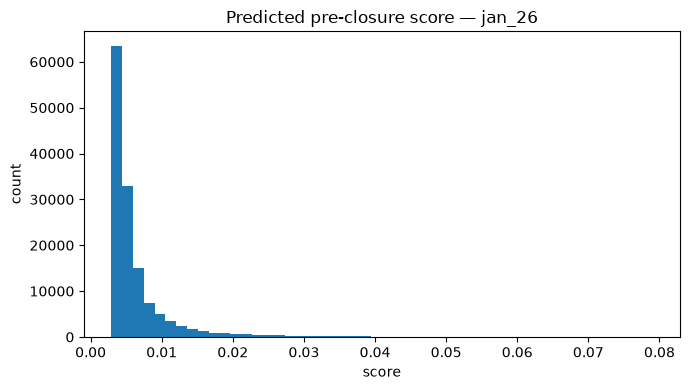

In [45]:
import matplotlib.pyplot as plt
print(predictions["preclosure_score"].describe())
plt.figure(figsize=(7,4)); plt.hist(predictions["preclosure_score"], bins=50)
plt.title(f"Predicted pre-closure score — {COHORT}"); plt.xlabel("score"); plt.ylabel("count"); plt.tight_layout(); plt.show()

---
**Scoring only.** No `preclosure_flag`, no 90-day outcome, no train/test split, no model fitting.
Output: `bureau_model_features_<cohort>.csv` (model-ready) and `bureau_predictions_<cohort>.csv`.
The bureau model uses future *scheduled* EMIs only via the population/`pos` calc (known at snapshot);
all observed dates are guarded <= SNAPSHOT_DATE.